In [ ]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Perform a sensitivity and convergence analysis across various step budgets and LR values

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name not in ("CLSBN26", "PepCL_Manuscript"):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find CLSBN26 project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "Data"
SRC_DIR = PROJECT_ROOT / "src"
MODEL_CHECKPOINTS_DIR = PROJECT_ROOT / "Model_Checkpoints"
FIGURES_DIR = PROJECT_ROOT / "Figures"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("FIGURES_DIR:", FIGURES_DIR)
print("PROJECT_ROOT in sys.path:", str(PROJECT_ROOT) in sys.path)

PROJECT_ROOT: /home/pchati/PepCL_Manuscript
DATA_DIR: /home/pchati/PepCL_Manuscript/Data
FIGURES_DIR: /home/pchati/PepCL_Manuscript/Figures
PROJECT_ROOT in sys.path: True


In [ ]:
# imports
from src.general_utils import *
from src.get_feature_data import *
from src.Model.mhcprime import *
from src.model_utils import *
from src.general_utils import *
from src.get_feature_data import *
from src.pepcl import *
from src.mhcprime_inference import *
from src.plotting import *
from src.pepcl_logging import *
from src.lr_step_variations_utils import *

# misc
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# change gpu
# GPU_ID = 0
# GPU_ID = 1
GPU_ID = 2
# GPU_ID = 3

torch.cuda.set_device(GPU_ID)
print(f"Using GPU: {torch.cuda.get_device_name(GPU_ID)} (ID: {torch.cuda.current_device()})")
# device="cuda"
device = torch.device(f"cuda:{GPU_ID}")

Using GPU: NVIDIA H100 80GB HBM3 (ID: 2)


### Figure output directory

In [ ]:
# create figures and data dir
lr_step_var_figures_dir=f"{FIGURES_DIR}/Revisions/LR_Step_Variation_Figures"
lr_step_var_figures_data_dir=f"{lr_step_var_figures_dir}/Associated_Data"

os.makedirs(lr_step_var_figures_dir, exist_ok=True)
os.makedirs(lr_step_var_figures_data_dir, exist_ok=True)

### Load and process results

#### Format pseudosequences and get feature data

In [ ]:
# format pseudosequences
from Data.mhc_pseudo_seqs import mhc_seq_dict
mhc_seq_dict={k.removeprefix("HLA-").replace("*","").replace(":",""):v for k,v in mhc_seq_dict.items()}

In [ ]:
# get feature table and processed features
aa_features_table_ext, descriptor_groups=load_feature_data()
processed_feature_table, corr_info = process_aa_feature_table(aa_features_table_ext)
feature_names = list(processed_feature_table.columns)  # pass to FeatureProjectionEncoder

#### Load runs and validation data

#### YD experiments

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/YD_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds/", 
]
print(results_dirs)

df_names=["ms_val", "holec_val"]


loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_holec=loaded_dfs_all["ms_val"]
holec_val=loaded_dfs_all["holec_val"]

# match the ms val to the assay val
ms_val_for_holec_matched, holec_val=filter_by_allele_len_pairs(ms_val_for_holec, holec_val, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
holec_dfs={
    "ms_val_matched": ms_val_for_holec_matched,
    "assay_val": holec_val,
}

for df_name, df in holec_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

['/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/YD_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds/']
[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/YD_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds/] found 2 df(s) (filtered to 2 requested)


dir 0: YD_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds: 100%|██████████| 2/2 [00:13<00:00,  6.52s/it]


total unique dfs in store: 2
ms_val_matched
Total: 80,000
Pos: 800 | 1.00%
Neg: 79,200 | 99.00%
N alleles: 16

assay_val
Total: 72,300
Pos: 723 | 1.00%
Neg: 71,577 | 99.00%
N alleles: 16

CPU times: user 12.6 s, sys: 1.71 s, total: 14.3 s
Wall time: 14.2 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/YD_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_CV_Datasplit_{ds}/" for ds in datasplits
]
print(results_dirs)

df_names=["ms_val", "holec_val"]

holec_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    holec_val=pd.read_csv(f"{rd}/holec_val.csv")
    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    holec_val.columns=holec_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    holec_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    holec_dfs_ds[f"assay_val_{ds}"]=holec_val

['/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/YD_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_CV_Datasplit_1/', '/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/YD_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_CV_Datasplit_2/', '/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/YD_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_CV_Datasplit_3/', '/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/YD_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_CV_Datasplit_4/']


  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:07<00:00,  1.99s/it]


In [ ]:
%%time
# get ft early stopping results

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/YD_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final/", 
]

df_names=["ms_val", "holec_val"]


loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_holec=loaded_dfs_all["ms_val"]
holec_val=loaded_dfs_all["holec_val"]

# match the ms val to the assay val
ms_val_for_holec_matched, holec_val=filter_by_allele_len_pairs(ms_val_for_holec, holec_val, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
holec_ft_es_dfs={
    "ms_val_matched": ms_val_for_holec_matched,
    "assay_val": holec_val,
}

for df_name, df in holec_ft_es_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/YD_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final/] found 2 df(s) (filtered to 2 requested)


dir 0: YD_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final: 100%|██████████| 2/2 [00:00<00:00,  3.88it/s]


total unique dfs in store: 2
ms_val_matched
Total: 80,000
Pos: 800 | 1.00%
Neg: 79,200 | 99.00%
N alleles: 16

assay_val
Total: 72,300
Pos: 723 | 1.00%
Neg: 71,577 | 99.00%
N alleles: 16

CPU times: user 653 ms, sys: 124 ms, total: 777 ms
Wall time: 771 ms


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/YD_FT_Early_Stopping_w_Alt_MHCPrime_CV_Datasplit_Final_{ds}/" for ds in datasplits
]

df_names=["ms_val", "holec_val"]

holec_ft_es_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    holec_val=pd.read_csv(f"{rd}/holec_val.csv")
    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    holec_val.columns=holec_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    holec_ft_es_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    holec_ft_es_dfs_ds[f"assay_val_{ds}"]=holec_val

100%|██████████| 4/4 [00:00<00:00,  4.22it/s]


#### EpiScan experiments

 - Forgot to keep `dataset_source` in R9/RT, we can just add back after (simple fix). For future runs, the script has already been corrected.

##### R9

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/EpiScan_R9_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds/", 
]

df_names=["ms_val", "episcan_r9_rt_val"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_episcan_r9=loaded_dfs_all["ms_val"]
episcan_r9_rt_val_for_r9=loaded_dfs_all["episcan_r9_rt_val"]

# match the ms val to the assay val
ms_val_for_episcan_r9_matched, episcan_r9_rt_val_for_r9=filter_by_allele_len_pairs(ms_val_for_episcan_r9, episcan_r9_rt_val_for_r9, allele_col="allele", seq_col="seq", filter_both=False)

episcan_r9_rt_val_for_r9_balanced=balance_across_dataset_sources(episcan_r9_rt_val_for_r9, allele_col="allele", label_col="label", source_col="dataset_source", seed=42, verbose=True)

# create dfs dict
episcan_r9_dfs={
    "ms_val_matched": ms_val_for_episcan_r9_matched,
    "assay_val": episcan_r9_rt_val_for_r9,
    "r9_val": episcan_r9_rt_val_for_r9.query("dataset_source == 'r9'"),
    "rt_val": episcan_r9_rt_val_for_r9.query("dataset_source == 'rt'"),
    "assay_val_balanced": episcan_r9_rt_val_for_r9_balanced,
}

for df_name, df in episcan_r9_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/EpiScan_R9_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds/] found 2 df(s) (filtered to 2 requested)


dir 0: EpiScan_R9_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds:   0%|          | 0/2 [00:00<?, ?it/s]

dir 0: EpiScan_R9_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds: 100%|██████████| 2/2 [00:05<00:00,  2.62s/it]


total unique dfs in store: 2
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)
allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
ms_val_matched
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

assay_val
Total: 33,800
Pos: 338 | 1.00%
Neg: 33,462 | 99.00%
N alleles: 4

r9_val
Total: 13,800
Pos: 138 | 1.00%
Neg: 13,662 | 99.00%
N alleles: 4

rt_val
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

assay_val_balanced
Total: 27,600
Pos: 276 | 1.00%
Neg: 27,324 | 99.00%
N alleles: 4

CPU times: user 7.65 s, sys: 966 ms, total: 8.62 s
Wall time: 8.57 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/EpiScan_R9_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_CV_Datasplit_{ds}/" for ds in datasplits
]

df_names=["ms_val", "episcan_r9_rt_val"]

episcan_r9_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    episcan_r9_rt_val=pd.read_csv(f"{rd}/episcan_r9_rt_val.csv")
    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_rt_val.columns=episcan_r9_rt_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    episcan_r9_dfs_ds[f"assay_val_{ds}"]=episcan_r9_rt_val

    episcan_r9_rt_val_balanced=balance_across_dataset_sources(episcan_r9_rt_val, allele_col="allele", label_col="label", source_col="dataset_source", seed=42, verbose=True)

    episcan_r9_dfs_ds[f"assay_val_balanced_{ds}"]=episcan_r9_rt_val_balanced


 25%|██▌       | 1/4 [00:01<00:03,  1.11s/it]

allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)


 50%|█████     | 2/4 [00:02<00:02,  1.08s/it]

allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)


 75%|███████▌  | 3/4 [00:03<00:01,  1.08s/it]

allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)


100%|██████████| 4/4 [00:04<00:00,  1.08s/it]

allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)


In [ ]:
%%time
# ft early stopping results
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/EpiScan_R9_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final/", 
]

df_names=["ms_val", "episcan_r9_rt_val"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_episcan_r9=loaded_dfs_all["ms_val"]
episcan_r9_rt_val_for_r9=loaded_dfs_all["episcan_r9_rt_val"]

# match the ms val to the assay val
ms_val_for_episcan_r9_matched, episcan_r9_rt_val_for_r9=filter_by_allele_len_pairs(ms_val_for_episcan_r9, episcan_r9_rt_val_for_r9, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
episcan_r9_ft_es_dfs={
    "ms_val_matched": ms_val_for_episcan_r9_matched,
    "assay_val": episcan_r9_rt_val_for_r9,
    "r9_val": episcan_r9_rt_val_for_r9.query("dataset_source == 'r9'"),
    "rt_val": episcan_r9_rt_val_for_r9.query("dataset_source == 'rt'"),
}

for df_name, df in episcan_r9_ft_es_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/EpiScan_R9_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final/] found 2 df(s) (filtered to 2 requested)


dir 0: EpiScan_R9_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final:   0%|          | 0/2 [00:00<?, ?it/s]

dir 0: EpiScan_R9_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final: 100%|██████████| 2/2 [00:00<00:00,  6.65it/s]


total unique dfs in store: 2
ms_val_matched
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

assay_val
Total: 33,800
Pos: 338 | 1.00%
Neg: 33,462 | 99.00%
N alleles: 4

r9_val
Total: 13,800
Pos: 138 | 1.00%
Neg: 13,662 | 99.00%
N alleles: 4

rt_val
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

CPU times: user 460 ms, sys: 4.16 ms, total: 464 ms
Wall time: 459 ms


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/EpiScan_R9_FT_Early_Stopping_w_Alt_MHCPrime_CV_Datasplit_Final_{ds}/" for ds in datasplits
]

df_names=["ms_val", "episcan_r9_rt_val"]

episcan_r9_ft_es_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    episcan_r9_rt_val=pd.read_csv(f"{rd}/episcan_r9_rt_val.csv")
    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_rt_val.columns=episcan_r9_rt_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_ft_es_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    episcan_r9_ft_es_dfs_ds[f"assay_val_{ds}"]=episcan_r9_rt_val

100%|██████████| 4/4 [00:00<00:00,  8.53it/s]


##### R9/RT

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/EpiScan_R9_RT_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds/", 
]

df_names=["ms_val", "episcan_r9_rt_val"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_episcan_r9rt=loaded_dfs_all["ms_val"]
episcan_r9_rt_val_for_r9rt=loaded_dfs_all["episcan_r9_rt_val"]

# match the ms val to the assay val
ms_val_for_episcan_r9rt_matched, episcan_r9_rt_val_for_r9rt=filter_by_allele_len_pairs(ms_val_for_episcan_r9rt, episcan_r9_rt_val_for_r9rt, allele_col="allele", seq_col="seq", filter_both=False)


episcan_r9_rt_val_for_r9rt_balanced=balance_across_dataset_sources(episcan_r9_rt_val_for_r9rt, allele_col="allele", label_col="label", source_col="dataset_source", seed=42, verbose=True)

# create dfs dict
episcan_r9rt_dfs={
    "ms_val_matched": ms_val_for_episcan_r9rt_matched,
    "assay_val": episcan_r9_rt_val_for_r9rt,
    "r9_val": episcan_r9_rt_val_for_r9rt.query("dataset_source == 'r9'"),
    "rt_val": episcan_r9_rt_val_for_r9rt.query("dataset_source == 'rt'"),
    "assay_val_balanced": episcan_r9_rt_val_for_r9rt_balanced
}

for df_name, df in episcan_r9rt_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/EpiScan_R9_RT_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds/] found 2 df(s) (filtered to 2 requested)


dir 0: EpiScan_R9_RT_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds:   0%|          | 0/2 [00:00<?, ?it/s]

dir 0: EpiScan_R9_RT_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds: 100%|██████████| 2/2 [00:04<00:00,  2.42s/it]


total unique dfs in store: 2
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)
allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
ms_val_matched
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

assay_val
Total: 33,800
Pos: 338 | 1.00%
Neg: 33,462 | 99.00%
N alleles: 4

r9_val
Total: 13,800
Pos: 138 | 1.00%
Neg: 13,662 | 99.00%
N alleles: 4

rt_val
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

assay_val_balanced
Total: 27,600
Pos: 276 | 1.00%
Neg: 27,324 | 99.00%
N alleles: 4

CPU times: user 7.12 s, sys: 1.02 s, total: 8.14 s
Wall time: 8.1 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/EpiScan_R9_RT_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_CV_Datasplit_{ds}/" for ds in datasplits
]

df_names=["ms_val", "episcan_r9_rt_val"]

episcan_r9rt_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    episcan_r9_rt_val=pd.read_csv(f"{rd}/episcan_r9_rt_val.csv")
    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_rt_val.columns=episcan_r9_rt_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9rt_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    episcan_r9rt_dfs_ds[f"assay_val_{ds}"]=episcan_r9_rt_val

    episcan_r9rt_dfs_ds[f"r9_val_{ds}"]=episcan_r9_rt_val.query("dataset_source == 'r9'")
    episcan_r9rt_dfs_ds[f"rt_val_{ds}"]=episcan_r9_rt_val.query("dataset_source == 'rt'")

    episcan_r9_rt_val_balanced=balance_across_dataset_sources(episcan_r9_rt_val, allele_col="allele", label_col="label", source_col="dataset_source", seed=42, verbose=True)

    episcan_r9rt_dfs_ds[f"assay_val_balanced_{ds}"]=episcan_r9_rt_val_balanced

 25%|██▌       | 1/4 [00:01<00:03,  1.10s/it]

allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)


 50%|█████     | 2/4 [00:02<00:02,  1.10s/it]

allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)


 75%|███████▌  | 3/4 [00:03<00:01,  1.11s/it]

allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)


100%|██████████| 4/4 [00:04<00:00,  1.12s/it]

allele=A0301 label=0 source=rt: 4950 -> 3267 (sampled down)
allele=B0801 label=0 source=rt: 4950 -> 495 (sampled down)
allele=A0301 label=1 source=rt: 50 -> 33 (sampled down)
allele=B0801 label=1 source=rt: 50 -> 5 (sampled down)


In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/EpiScan_R9_RT_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final/", 
]

df_names=["ms_val", "episcan_r9_rt_val"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_episcan_r9rt=loaded_dfs_all["ms_val"]
episcan_r9_rt_val_for_r9rt=loaded_dfs_all["episcan_r9_rt_val"]

# match the ms val to the assay val
ms_val_for_episcan_r9rt_matched, episcan_r9_rt_val_for_r9rt=filter_by_allele_len_pairs(ms_val_for_episcan_r9rt, episcan_r9_rt_val_for_r9rt, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
episcan_r9rt_ft_es_dfs={
    "ms_val_matched": ms_val_for_episcan_r9rt_matched,
    "assay_val": episcan_r9_rt_val_for_r9rt,
    "r9_val": episcan_r9_rt_val_for_r9rt.query("dataset_source == 'r9'"),
    "rt_val": episcan_r9_rt_val_for_r9rt.query("dataset_source == 'rt'"),
}

for df_name, df in episcan_r9rt_ft_es_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/EpiScan_R9_RT_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final/] found 2 df(s) (filtered to 2 requested)


dir 0: EpiScan_R9_RT_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final: 100%|██████████| 2/2 [00:00<00:00,  9.56it/s]


total unique dfs in store: 2
ms_val_matched
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

assay_val
Total: 33,800
Pos: 338 | 1.00%
Neg: 33,462 | 99.00%
N alleles: 4

r9_val
Total: 13,800
Pos: 138 | 1.00%
Neg: 13,662 | 99.00%
N alleles: 4

rt_val
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

CPU times: user 322 ms, sys: 28 ms, total: 350 ms
Wall time: 346 ms


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/EpiScan_R9_RT_FT_Early_Stopping_w_Alt_MHCPrime_CV_Datasplit_Final_{ds}/" for ds in datasplits
]

df_names=["ms_val", "episcan_r9_rt_val"]

episcan_r9rt_ft_es_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    episcan_r9_rt_val=pd.read_csv(f"{rd}/episcan_r9_rt_val.csv")
    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_rt_val.columns=episcan_r9_rt_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9rt_ft_es_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    episcan_r9rt_ft_es_dfs_ds[f"assay_val_{ds}"]=episcan_r9_rt_val

    episcan_r9rt_ft_es_dfs_ds[f"r9_val_{ds}"]=episcan_r9_rt_val.query("dataset_source == 'r9'")
    episcan_r9rt_ft_es_dfs_ds[f"rt_val_{ds}"]=episcan_r9_rt_val.query("dataset_source == 'rt'")

100%|██████████| 4/4 [00:00<00:00,  9.72it/s]


#### BA experiments

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/BA_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds/", 
]

df_names=["ms_val", "ba_val"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_ba_con=loaded_dfs_all["ms_val"]
ba_con_val=loaded_dfs_all["ba_val"]

# match the ms val to the assay val
ms_val_for_ba_con_matched, ba_con_val=filter_by_allele_len_pairs(ms_val_for_ba_con, ba_con_val, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
ba_con_dfs={
    "ms_val_matched": ms_val_for_ba_con_matched,
    "assay_val": ba_con_val,
}

for df_name, df in ba_con_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/BA_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds/] found 2 df(s) (filtered to 2 requested)


dir 0: BA_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds:   0%|          | 0/2 [00:00<?, ?it/s]

dir 0: BA_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds: 100%|██████████| 2/2 [00:06<00:00,  3.28s/it]


total unique dfs in store: 2
ms_val_matched
Total: 327,500
Pos: 3,275 | 1.00%
Neg: 324,225 | 99.00%
N alleles: 41

assay_val
Total: 3,052
Pos: 1,526 | 50.00%
Neg: 1,526 | 50.00%
N alleles: 41

CPU times: user 7.05 s, sys: 1.21 s, total: 8.26 s
Wall time: 8.23 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/BA_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_CV_Datasplit_{ds}/" for ds in datasplits
]

df_names=["ms_val", "ba_val"]

ba_con_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    ba_con_val=pd.read_csv(f"{rd}/ba_val.csv")

    ms_val, ba_con_val=filter_by_allele_len_pairs(ms_val, ba_con_val, allele_col="allele", seq_col="seq", filter_both=False)

    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ba_con_val.columns=ba_con_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ba_con_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    ba_con_dfs_ds[f"assay_val_{ds}"]=ba_con_val

100%|██████████| 4/4 [00:08<00:00,  2.23s/it]


In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/BA_CON_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final/", 
]

df_names=["ms_val", "ba_val"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_ba_con=loaded_dfs_all["ms_val"]
ba_con_val=loaded_dfs_all["ba_val"]

# match the ms val to the assay val
ms_val_for_ba_con_matched, ba_con_val=filter_by_allele_len_pairs(ms_val_for_ba_con, ba_con_val, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
ba_con_ft_es_dfs={
    "ms_val_matched": ms_val_for_ba_con_matched,
    "assay_val": ba_con_val,
}

for df_name, df in ba_con_ft_es_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/BA_CON_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final/] found 2 df(s) (filtered to 2 requested)


dir 0: BA_CON_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Final: 100%|██████████| 2/2 [00:02<00:00,  1.10s/it]


total unique dfs in store: 2
ms_val_matched
Total: 327,500
Pos: 3,275 | 1.00%
Neg: 324,225 | 99.00%
N alleles: 41

assay_val
Total: 3,052
Pos: 1,526 | 50.00%
Neg: 1,526 | 50.00%
N alleles: 41

CPU times: user 2.66 s, sys: 357 ms, total: 3.01 s
Wall time: 3.01 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/BA_CON_FT_Early_Stopping_w_Alt_MHCPrime_CV_Datasplit_Final_{ds}/" for ds in datasplits
]

df_names=["ms_val", "ba_val"]

ba_con_ft_es_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    ba_con_val=pd.read_csv(f"{rd}/ba_val.csv")

    ms_val, ba_con_val=filter_by_allele_len_pairs(ms_val, ba_con_val, allele_col="allele", seq_col="seq", filter_both=False)

    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ba_con_val.columns=ba_con_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ba_con_ft_es_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    ba_con_ft_es_dfs_ds[f"assay_val_{ds}"]=ba_con_val

100%|██████████| 4/4 [00:04<00:00,  1.10s/it]


#### ESCAPE-seq experiments

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/ESCAPE_seq_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds_Cleaned/", 
]

df_names=["ms_val", "escape_val"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_escape_con=loaded_dfs_all["ms_val"]
escape_con_val=loaded_dfs_all["escape_val"]

# match the ms val to the assay val
ms_val_for_escape_con_matched, escape_con_val=filter_by_allele_len_pairs(ms_val_for_escape_con, escape_con_val, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
escape_con_dfs={
    # "ms_val": ms_val_for_escape_con,
    "ms_val_matched": ms_val_for_escape_con_matched,
    "assay_val": escape_con_val,
}

for df_name, df in escape_con_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/ESCAPE_seq_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds_Cleaned/] found 2 df(s) (filtered to 2 requested)


dir 0: ESCAPE_seq_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds_Cleaned:   0%|          | 0/2 [00:00<?, ?it/s]

dir 0: ESCAPE_seq_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_Full_5_Seeds_Cleaned: 100%|██████████| 2/2 [00:03<00:00,  1.93s/it]


total unique dfs in store: 2
ms_val_matched
Total: 185,000
Pos: 1,850 | 1.00%
Neg: 183,150 | 99.00%
N alleles: 37

assay_val
Total: 1,315
Pos: 657 | 49.96%
Neg: 658 | 50.04%
N alleles: 41

CPU times: user 4.16 s, sys: 621 ms, total: 4.78 s
Wall time: 4.77 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/ESCAPE_seq_CON_Step_and_Learning_Rate_Ablations_w_Alt_MHCPrime_CV_Datasplit_Cleaned_{ds}/" for ds in datasplits

]

df_names=["ms_val", "escape_val"]

escape_con_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    escape_con_val=pd.read_csv(f"{rd}/escape_val.csv")

    ms_val, escape_con_val=filter_by_allele_len_pairs(ms_val, escape_con_val, allele_col="allele", seq_col="seq", filter_both=False)

    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    escape_con_val.columns=escape_con_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    escape_con_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    escape_con_dfs_ds[f"assay_val_{ds}"]=escape_con_val

100%|██████████| 4/4 [00:05<00:00,  1.29s/it]


In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/ESCAPE_seq_CON_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Cleaned_Final/",  
]

df_names=["ms_val", "escape_val"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_escape_con=loaded_dfs_all["ms_val"]
escape_con_val=loaded_dfs_all["escape_val"]

# match the ms val to the assay val
ms_val_for_escape_con_matched, escape_con_val=filter_by_allele_len_pairs(ms_val_for_escape_con, escape_con_val, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
escape_con_ft_es_dfs={
    # "ms_val": ms_val_for_escape_con,
    "ms_val_matched": ms_val_for_escape_con_matched,
    "assay_val": escape_con_val,
}

for df_name, df in escape_con_ft_es_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results/ESCAPE_seq_CON_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Cleaned_Final/] found 2 df(s) (filtered to 2 requested)


dir 0: ESCAPE_seq_CON_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Cleaned_Final:   0%|          | 0/2 [00:00<?, ?it/s]

dir 0: ESCAPE_seq_CON_FT_Early_Stopping_w_Alt_MHCPrime_Full_5_Seeds_Cleaned_Final: 100%|██████████| 2/2 [00:00<00:00,  5.41it/s]


total unique dfs in store: 2
ms_val_matched
Total: 185,000
Pos: 1,850 | 1.00%
Neg: 183,150 | 99.00%
N alleles: 37

assay_val
Total: 1,315
Pos: 657 | 49.96%
Neg: 658 | 50.04%
N alleles: 41

CPU times: user 603 ms, sys: 68 ms, total: 671 ms
Wall time: 665 ms


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results/ESCAPE_seq_CON_FT_Early_Stopping_w_Alt_MHCPrime_CV_Datasplit_Cleaned_Final_{ds}/" for ds in datasplits
]

df_names=["ms_val", "escape_val"]

escape_con_ft_es_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    escape_con_val=pd.read_csv(f"{rd}/escape_val.csv")

    ms_val, escape_con_val=filter_by_allele_len_pairs(ms_val, escape_con_val, allele_col="allele", seq_col="seq", filter_both=False)

    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    escape_con_val.columns=escape_con_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    escape_con_ft_es_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    escape_con_ft_es_dfs_ds[f"assay_val_{ds}"]=escape_con_val

100%|██████████| 4/4 [00:01<00:00,  2.15it/s]


### Perform validation-based candidate selection per dataset and method

#### Compute performance metrics

In [ ]:
# updated
learning_rates = [2e-5, 5e-5, 1e-4, 2e-4]
step_budgets = [25, 50, 100, 200, 300, 400, 600, 800]
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8] # seeds 5, 6, 7, 8 are cross dataset (include with seed 0)

ckpt_to_save_per_budget = {
    25: [5, 10, 15, 20, 25],
    50: [5, 10, 20, 30, 40, 50],
    100: [10, 20, 40, 60, 80, 100],
    200: [10, 20, 25, 50, 75, 100, 150, 200],
    300: [10, 25, 50, 75, 100, 150, 200, 250, 300],
    400: [10, 25, 50, 100, 150, 200, 250, 300, 350, 400],
    600: [10, 25, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600],
    800: [10, 25, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600, 650, 700, 750, 800],
}


learning_rate_strings=lr_to_strings(learning_rates)

holec_method_prefixes={
    "ft": "holec_ft_",
    "pepcl_r_dr": "holec_pepcl_r_dr_",
}

episcan_r9_method_prefixes={
    "ft": "episcan_r9_ft_",
    "pepcl_r_dr": "episcan_r9_pepcl_r_dr_",
}

episcan_r9rt_method_prefixes={
    "ft": "episcan_r9rt_ft_",
    "pepcl_r_dr": "episcan_r9rt_pepcl_r_dr_",
}

ba_con_method_prefixes={
    "ft": "ba_con_ft_",
    "pepcl_r_dr": "ba_con_pepcl_r_dr_",
}

escape_con_method_prefixes={
    "ft": "escape_con_ft_",
    "pepcl_r_dr": "escape_con_pepcl_r_dr_",
}

holec_model_groups = build_ablation_model_groups(
    holec_method_prefixes,
    step_budgets,
    learning_rates,
    seeds,
    ckpt_to_save_per_budget,
    learning_rate_strings=learning_rate_strings,
    lr_string_fn=None,
)

episcan_r9_model_groups = build_ablation_model_groups(
    episcan_r9_method_prefixes,
    step_budgets,
    learning_rates,
    seeds,
    ckpt_to_save_per_budget,
    learning_rate_strings=learning_rate_strings,
    lr_string_fn=None,
)

episcan_r9rt_model_groups = build_ablation_model_groups(
    episcan_r9rt_method_prefixes,
    step_budgets,
    learning_rates,
    seeds,
    ckpt_to_save_per_budget,
    learning_rate_strings=learning_rate_strings,
    lr_string_fn=None,
)

ba_con_model_groups = build_ablation_model_groups(
    ba_con_method_prefixes,
    step_budgets,
    learning_rates,
    seeds,
    ckpt_to_save_per_budget,
    learning_rate_strings=learning_rate_strings,
    lr_string_fn=None,
)

escape_con_model_groups = build_ablation_model_groups(
    escape_con_method_prefixes,
    step_budgets,
    learning_rates,
    seeds,
    ckpt_to_save_per_budget,
    learning_rate_strings=learning_rate_strings,
    lr_string_fn=None,
)

print("YD:", len(holec_model_groups.keys()), holec_model_groups.keys())
print("EpiScan R9:", len(episcan_r9_model_groups.keys()), episcan_r9_model_groups.keys())
print("EpiScan R9/RT:", len(episcan_r9rt_model_groups.keys()), episcan_r9rt_model_groups.keys())
print("BA CON:", len(ba_con_model_groups.keys()), ba_con_model_groups.keys())
print("ESCAPE CON:", len(escape_con_model_groups.keys()), escape_con_model_groups.keys())

YD: 576 dict_keys(['holec_ft_steps_25_lr_2eN5_seed_0', 'holec_ft_steps_25_lr_5eN5_seed_0', 'holec_ft_steps_25_lr_1eN4_seed_0', 'holec_ft_steps_25_lr_2eN4_seed_0', 'holec_ft_steps_50_lr_2eN5_seed_0', 'holec_ft_steps_50_lr_5eN5_seed_0', 'holec_ft_steps_50_lr_1eN4_seed_0', 'holec_ft_steps_50_lr_2eN4_seed_0', 'holec_ft_steps_100_lr_2eN5_seed_0', 'holec_ft_steps_100_lr_5eN5_seed_0', 'holec_ft_steps_100_lr_1eN4_seed_0', 'holec_ft_steps_100_lr_2eN4_seed_0', 'holec_ft_steps_200_lr_2eN5_seed_0', 'holec_ft_steps_200_lr_5eN5_seed_0', 'holec_ft_steps_200_lr_1eN4_seed_0', 'holec_ft_steps_200_lr_2eN4_seed_0', 'holec_ft_steps_300_lr_2eN5_seed_0', 'holec_ft_steps_300_lr_5eN5_seed_0', 'holec_ft_steps_300_lr_1eN4_seed_0', 'holec_ft_steps_300_lr_2eN4_seed_0', 'holec_ft_steps_400_lr_2eN5_seed_0', 'holec_ft_steps_400_lr_5eN5_seed_0', 'holec_ft_steps_400_lr_1eN4_seed_0', 'holec_ft_steps_400_lr_2eN4_seed_0', 'holec_ft_steps_600_lr_2eN5_seed_0', 'holec_ft_steps_600_lr_5eN5_seed_0', 'holec_ft_steps_600_lr_1eN4

#### YD experiments

In [ ]:
def rename_mhcprime_by_datasplit(df_dict, ds_to_seed_offset=4):
    out={}

    for key,df in df_dict.items():
        df=df.copy()

        # assumes key ends in _1, _2, _3, _4
        ds=int(key.rsplit("_",1)[-1])
        seed=ds+ds_to_seed_offset

        if "mhcprime" in df.columns:
            df=df.rename(columns={"mhcprime":f"mhcprime_seed_{seed}"})

        out[key]=df

    return out

In [ ]:
%%time
# compute ap matrices at a baseline for the ms val and assay val (will have to do separately for episcan set)

# dict of dfs:
# holec_dfs
# episcan_r9_dfs
# episcan_r9rt_dfs
# ba_con_dfs
# escape_con_dfs

# holec ap matrices
holec_ap_dfs={}

for df_name, df in tqdm(holec_dfs.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    holec_ap_dfs[df_name]=ap_df


holec_ap_dfs_ds={}

for df_name, df in tqdm(holec_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    holec_ap_dfs_ds[df_name]=ap_df

# merge dataset splits ap dfs
holec_ap_dfs_ds=rename_mhcprime_by_datasplit(holec_ap_dfs_ds, ds_to_seed_offset=4)

holec_ap_dfs_ds_merged=merge_dfs_by_prefix(holec_ap_dfs_ds, ["ms_val_matched", "assay_val"])

# create full ap df
holec_ap_dfs=merge_two_dicts_by_keys(holec_ap_dfs, holec_ap_dfs_ds_merged, ["ms_val_matched", "assay_val"])

100%|██████████| 8/8 [00:29<00:00,  3.64s/it]

CPU times: user 1min 5s, sys: 213 ms, total: 1min 5s
Wall time: 1min 5s


In [ ]:
# early stopping results
holec_ft_es_ap_dfs={}

for df_name, df in tqdm(holec_ft_es_dfs.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    holec_ft_es_ap_dfs[df_name]=ap_df


holec_ft_es_ap_dfs_ds={}

for df_name, df in tqdm(holec_ft_es_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    holec_ft_es_ap_dfs_ds[df_name]=ap_df

# merge dataset splits ap dfs
holec_ft_es_ap_dfs_ds=rename_mhcprime_by_datasplit(holec_ft_es_ap_dfs_ds, ds_to_seed_offset=4)

holec_ft_es_ap_dfs_ds_merged=merge_dfs_by_prefix(holec_ft_es_ap_dfs_ds, ["ms_val_matched", "assay_val"])

# create full ap df
holec_ft_es_ap_dfs=merge_two_dicts_by_keys(holec_ft_es_ap_dfs, holec_ft_es_ap_dfs_ds_merged, ["ms_val_matched", "assay_val"])

100%|██████████| 8/8 [00:01<00:00,  6.01it/s]


In [ ]:
holec_pepcl_ft_es_ap_dfs=merge_dicts_prefer_second_stripped(holec_ap_dfs, holec_ft_es_ap_dfs, ["ms_val_matched", "assay_val"])

#### EpiScan experiments

##### R9

In [ ]:
%%time
# episcan r9 aps
datasplits=[1, 2, 3, 4]

episcan_r9_ap_dfs={}

for df_name, df in tqdm(episcan_r9_dfs.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9_ap_dfs[df_name] = ap_df

episcan_r9_ap_dfs_ds={}

for df_name, df in tqdm(episcan_r9_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9_ap_dfs_ds[df_name]=ap_df

n_iterations=100
allele_pos_counts = {"A0201": 100, "A0301": 100, "B0801": 100, "B5701": 100}

# per-allele AP matrix, pos-focused (negs from r9 only)
print("EpiScan R9")
episcan_r9_val_set_for_r9=episcan_r9_dfs["assay_val"].query("dataset_source == 'r9'")
episcan_rt_val_set_for_r9=episcan_r9_dfs["assay_val"].query("dataset_source == 'rt'")

score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
score_cols=keep_present_cols(episcan_r9_dfs["assay_val"], score_cols)

r9rt_pos_r9_neg_per_allele_ap_for_r9 = mixed_df_per_allele_ap_pos_focused_fast(episcan_r9_val_set_for_r9, episcan_rt_val_set_for_r9.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

episcan_r9_ap_dfs["assay_val_mixture"]=r9rt_pos_r9_neg_per_allele_ap_for_r9

# repeat for datasplits
for ds in datasplits:
    print("EpiScan R9")
    episcan_r9_val_set_for_r9=episcan_r9_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'r9'")
    episcan_rt_val_set_for_r9=episcan_r9_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'rt'")

    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    score_cols=keep_present_cols(episcan_r9_dfs_ds[f"assay_val_{ds}"], score_cols)

    # standard sampling procedure
    r9rt_pos_r9_neg_per_allele_ap_for_r9 = mixed_df_per_allele_ap_pos_focused_fast(episcan_r9_val_set_for_r9, episcan_rt_val_set_for_r9.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

    episcan_r9_ap_dfs_ds[f"assay_val_mixture_{ds}"]=r9rt_pos_r9_neg_per_allele_ap_for_r9

# merge dataset splits ap dfs
episcan_r9_ap_dfs_ds=rename_mhcprime_by_datasplit(episcan_r9_ap_dfs_ds, ds_to_seed_offset=4)

episcan_r9_ap_dfs_ds_merged=merge_dfs_by_prefix(episcan_r9_ap_dfs_ds, ["ms_val_matched", "assay_val_mixture", "assay_val_balanced"])

# create full ap df
episcan_r9_ap_dfs=merge_two_dicts_by_keys(episcan_r9_ap_dfs, episcan_r9_ap_dfs_ds_merged, ["ms_val_matched", "assay_val_mixture", "assay_val_balanced"])

100%|██████████| 12/12 [00:20<00:00,  1.67s/it]


EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [01:24<00:00,  1.18it/s]


EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [00:18<00:00,  5.38it/s]


...

EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [00:17<00:00,  5.57it/s]


EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [00:18<00:00,  5.41it/s]


CPU times: user 25min 16s, sys: 8.45 s, total: 25min 24s
Wall time: 3min 40s


In [ ]:
%%time
# for ft early stopping

# episcan r9 aps
datasplits=[1, 2, 3, 4]

episcan_r9_ft_es_ap_dfs={}

for df_name, df in tqdm(episcan_r9_ft_es_dfs.items()):
    # score_cols = ["mhcprime"] + list(episcan_r9_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9_ft_es_ap_dfs[df_name] = ap_df

episcan_r9_ft_es_ap_dfs_ds={}

for df_name, df in tqdm(episcan_r9_ft_es_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9_ft_es_ap_dfs_ds[df_name]=ap_df

n_iterations=100
allele_pos_counts = {"A0201": 100, "A0301": 100, "B0801": 100, "B5701": 100}

# per-allele AP matrix, pos-focused (negs from r9 only)
print("EpiScan R9")
episcan_r9_val_set_for_r9=episcan_r9_ft_es_dfs["assay_val"].query("dataset_source == 'r9'")
episcan_rt_val_set_for_r9=episcan_r9_ft_es_dfs["assay_val"].query("dataset_source == 'rt'")

# score_cols = ["mhcprime"] + list(episcan_r9_model_groups.keys())
score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
score_cols=keep_present_cols(episcan_r9_ft_es_dfs["assay_val"], score_cols)

r9rt_pos_r9_neg_per_allele_ap_for_r9 = mixed_df_per_allele_ap_pos_focused_fast(episcan_r9_val_set_for_r9, episcan_rt_val_set_for_r9.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

episcan_r9_ft_es_ap_dfs["assay_val_mixture"]=r9rt_pos_r9_neg_per_allele_ap_for_r9

# repeat for datasplits
for ds in datasplits:
    # per-allele AP matrix, pos-focused (negs from r9 only)
    print("EpiScan R9")
    episcan_r9_val_set_for_r9=episcan_r9_ft_es_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'r9'")
    episcan_rt_val_set_for_r9=episcan_r9_ft_es_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'rt'")

    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    score_cols=keep_present_cols(episcan_r9_ft_es_dfs_ds[f"assay_val_{ds}"], score_cols)

    r9rt_pos_r9_neg_per_allele_ap_for_r9 = mixed_df_per_allele_ap_pos_focused_fast(episcan_r9_val_set_for_r9, episcan_rt_val_set_for_r9.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

    episcan_r9_ft_es_ap_dfs_ds[f"assay_val_mixture_{ds}"]=r9rt_pos_r9_neg_per_allele_ap_for_r9

# merge dataset splits ap dfs
episcan_r9_ft_es_ap_dfs_ds=rename_mhcprime_by_datasplit(episcan_r9_ft_es_ap_dfs_ds, ds_to_seed_offset=4)

episcan_r9_ft_es_ap_dfs_ds_merged=merge_dfs_by_prefix(episcan_r9_ft_es_ap_dfs_ds, ["ms_val_matched", "assay_val_mixture"])

# create full ap df
episcan_r9_ft_es_ap_dfs=merge_two_dicts_by_keys(episcan_r9_ft_es_ap_dfs, episcan_r9_ft_es_ap_dfs_ds_merged, ["ms_val_matched", "assay_val_mixture"])

100%|██████████| 8/8 [00:01<00:00,  6.54it/s]


EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [00:03<00:00, 27.31it/s]


EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [00:01<00:00, 94.57it/s]


...

EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [00:01<00:00, 93.48it/s]


EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [00:01<00:00, 95.76it/s]

CPU times: user 1min, sys: 2.76 s, total: 1min 3s
Wall time: 11.8 s


In [ ]:
episcan_r9_pepcl_ft_es_ap_dfs=merge_dicts_prefer_second_stripped(episcan_r9_ap_dfs, episcan_r9_ft_es_ap_dfs, ["ms_val_matched", "assay_val_mixture"])

##### R9/RT

In [ ]:
%%time
# episcan r9rt aps
datasplits=[1, 2, 3, 4]

episcan_r9rt_ap_dfs={}

for df_name, df in tqdm(episcan_r9rt_dfs.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9rt_ap_dfs[df_name] = ap_df

episcan_r9rt_ap_dfs_ds={}

for df_name, df in tqdm(episcan_r9rt_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9rt_ap_dfs_ds[df_name]=ap_df

n_iterations=100

# per-allele AP matrix, both (negs split across r9 and rt)
print("EpiScan R9/RT")
episcan_r9_val_set_for_r9rt=episcan_r9rt_dfs["assay_val"].query("dataset_source == 'r9'")
episcan_rt_val_set_for_r9rt=episcan_r9rt_dfs["assay_val"].query("dataset_source == 'rt'")

score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
score_cols=keep_present_cols(episcan_r9rt_dfs["assay_val"], score_cols)

r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt = mixed_df_per_allele_ap_balanced_fast(episcan_r9_val_set_for_r9rt, episcan_rt_val_set_for_r9rt, score_cols, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

episcan_r9rt_ap_dfs["assay_val_mixture"]=r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt

# repeat for datasplits
for ds in datasplits:
    # per-allele AP matrix, both (negs split across r9 and rt)
    print("EpiScan R9/RT")
    episcan_r9_val_set_for_r9rt=episcan_r9rt_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'r9'")
    episcan_rt_val_set_for_r9rt=episcan_r9rt_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'rt'")

    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    score_cols=keep_present_cols(episcan_r9rt_dfs_ds[f"assay_val_{ds}"], score_cols)

    # accounting for imbalance
    r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt = mixed_df_per_allele_ap_balanced_fast(episcan_r9_val_set_for_r9rt, episcan_rt_val_set_for_r9rt, score_cols, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

    episcan_r9rt_ap_dfs_ds[f"assay_val_mixture_{ds}"]=r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt

# merge dataset splits ap dfs
episcan_r9rt_ap_dfs_ds=rename_mhcprime_by_datasplit(episcan_r9rt_ap_dfs_ds, ds_to_seed_offset=4)

episcan_r9rt_ap_dfs_ds_merged=merge_dfs_by_prefix(episcan_r9rt_ap_dfs_ds, ["ms_val_matched", "assay_val_mixture", "assay_val", "rt_val", "r9_val", "assay_val_balanced"])

# create full ap df
episcan_r9rt_ap_dfs=merge_two_dicts_by_keys(episcan_r9rt_ap_dfs, episcan_r9rt_ap_dfs_ds_merged, ["ms_val_matched", "assay_val_mixture", "assay_val", "rt_val", "r9_val", "assay_val_balanced"])

100%|██████████| 20/20 [00:31<00:00,  1.58s/it]


EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [01:19<00:00,  1.26it/s]


EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:20<00:00,  4.86it/s]


...

EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:15<00:00,  6.35it/s]


EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:19<00:00,  5.24it/s]

CPU times: user 28min 52s, sys: 15.7 s, total: 29min 7s
Wall time: 3min 51s


In [ ]:
%%time
# episcan r9rt aps
datasplits=[1, 2, 3, 4]

episcan_r9rt_ft_es_ap_dfs={}

for df_name, df in tqdm(episcan_r9rt_ft_es_dfs.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9rt_ft_es_ap_dfs[df_name] = ap_df

episcan_r9rt_ft_es_ap_dfs_ds={}

for df_name, df in tqdm(episcan_r9rt_ft_es_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9rt_ft_es_ap_dfs_ds[df_name]=ap_df


n_iterations=100

# per-allele AP matrix, both (negs split across r9 and rt)
print("EpiScan R9/RT")
episcan_r9_val_set_for_r9rt=episcan_r9rt_ft_es_dfs["assay_val"].query("dataset_source == 'r9'")
episcan_rt_val_set_for_r9rt=episcan_r9rt_ft_es_dfs["assay_val"].query("dataset_source == 'rt'")

score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
score_cols=keep_present_cols(episcan_r9rt_ft_es_dfs["assay_val"], score_cols)

r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt = mixed_df_per_allele_ap_balanced_fast(episcan_r9_val_set_for_r9rt, episcan_rt_val_set_for_r9rt, score_cols, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)


episcan_r9rt_ft_es_ap_dfs["assay_val_mixture"]=r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt

# repeat for datasplits
for ds in datasplits:
    # per-allele AP matrix, both (negs split across r9 and rt)
    print("EpiScan R9/RT")
    episcan_r9_val_set_for_r9rt=episcan_r9rt_ft_es_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'r9'")
    episcan_rt_val_set_for_r9rt=episcan_r9rt_ft_es_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'rt'")

    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    score_cols=keep_present_cols(episcan_r9rt_ft_es_dfs_ds[f"assay_val_{ds}"], score_cols)

    r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt = mixed_df_per_allele_ap_balanced_fast(episcan_r9_val_set_for_r9rt, episcan_rt_val_set_for_r9rt, score_cols, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

    episcan_r9rt_ft_es_ap_dfs_ds[f"assay_val_mixture_{ds}"]=r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt

# merge dataset splits ap dfs
episcan_r9rt_ft_es_ap_dfs_ds=rename_mhcprime_by_datasplit(episcan_r9rt_ft_es_ap_dfs_ds, ds_to_seed_offset=4)

episcan_r9rt_ft_es_ap_dfs_ds_merged=merge_dfs_by_prefix(episcan_r9rt_ft_es_ap_dfs_ds, ["ms_val_matched", "assay_val_mixture", "assay_val", "rt_val", "r9_val"])

# create full ap df
episcan_r9rt_ft_es_ap_dfs=merge_two_dicts_by_keys(episcan_r9rt_ft_es_ap_dfs, episcan_r9rt_ft_es_ap_dfs_ds_merged, ["ms_val_matched", "assay_val_mixture", "assay_val", "rt_val", "r9_val"])

100%|██████████| 16/16 [00:01<00:00,  9.61it/s]


EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:05<00:00, 19.69it/s]


EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:01<00:00, 57.66it/s]


...

EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:01<00:00, 75.60it/s]


EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:01<00:00, 73.88it/s]

CPU times: user 1min 29s, sys: 2.54 s, total: 1min 32s
Wall time: 14.9 s


In [ ]:
episcan_r9rt_pepcl_ft_es_ap_dfs=merge_dicts_prefer_second_both_stripped(episcan_r9rt_ap_dfs, episcan_r9rt_ft_es_ap_dfs, ["ms_val_matched", "assay_val_mixture", "assay_val", "rt_val", "r9_val"])

#### BA CON

In [ ]:
%%time
# ba aps
ba_con_ap_dfs={}

for df_name, df in tqdm(ba_con_dfs.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups)
    if df_name == "ms_val" or df_name == "ms_val_matched":
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        ba_con_ap_dfs[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="ba_value", allele_col='allele', disable_tqdm=True)
        ba_con_ap_dfs[df_name] = spearman_df

ba_con_ap_dfs_ds={}

for df_name, df in tqdm(ba_con_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups)
    if "ms_val_matched" in df_name:
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        ba_con_ap_dfs_ds[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="ba_value", allele_col='allele', disable_tqdm=True)
        ba_con_ap_dfs_ds[df_name] = spearman_df


# merge dataset splits ap dfs
ba_con_ap_dfs_ds=rename_mhcprime_by_datasplit(ba_con_ap_dfs_ds, ds_to_seed_offset=4)

ba_con_ap_dfs_ds_merged=merge_dfs_by_prefix(ba_con_ap_dfs_ds, ["ms_val_matched", "assay_val"])

# create full ap df
ba_con_ap_dfs=merge_two_dicts_by_keys(ba_con_ap_dfs, ba_con_ap_dfs_ds_merged, ["ms_val_matched", "assay_val"])

  0%|          | 0/2 [00:00<?, ?it/s]

ms_val_matched: AP branch


 50%|█████     | 1/2 [00:23<00:23, 23.26s/it]

assay_val: SPEARMAN branch


  0%|          | 0/8 [00:00<?, ?it/s]

...

ms_val_matched_4: AP branch


 88%|████████▊ | 7/8 [00:50<00:06,  6.93s/it]

assay_val_4: SPEARMAN branch


100%|██████████| 8/8 [01:02<00:00,  7.79s/it]

CPU times: user 2min 23s, sys: 861 ms, total: 2min 24s
Wall time: 2min 24s


In [ ]:
%%time
# ba aps
ba_con_ft_es_ap_dfs={}

for df_name, df in tqdm(ba_con_ft_es_dfs.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups)
    if df_name == "ms_val" or df_name == "ms_val_matched":
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        ba_con_ft_es_ap_dfs[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="ba_value", allele_col='allele', disable_tqdm=True)
        ba_con_ft_es_ap_dfs[df_name] = spearman_df

ba_con_ft_es_ap_dfs_ds={}

for df_name, df in tqdm(ba_con_ft_es_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups)
    if "ms_val_matched" in df_name:
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        ba_con_ft_es_ap_dfs_ds[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="ba_value", allele_col='allele', disable_tqdm=True)
        ba_con_ft_es_ap_dfs_ds[df_name] = spearman_df

# merge dataset splits ap dfs
ba_con_ft_es_ap_dfs_ds=rename_mhcprime_by_datasplit(ba_con_ft_es_ap_dfs_ds, ds_to_seed_offset=4)

ba_con_ft_es_ap_dfs_ds_merged=merge_dfs_by_prefix(ba_con_ft_es_ap_dfs_ds, ["ms_val_matched", "assay_val"])

# create full ap df
ba_con_ft_es_ap_dfs=merge_two_dicts_by_keys(ba_con_ft_es_ap_dfs, ba_con_ft_es_ap_dfs_ds_merged, ["ms_val_matched", "assay_val"])

  0%|          | 0/2 [00:00<?, ?it/s]

ms_val_matched: AP branch


 50%|█████     | 1/2 [00:05<00:05,  5.43s/it]

assay_val: SPEARMAN branch


  0%|          | 0/8 [00:00<?, ?it/s]

...

ms_val_matched_4: AP branch


 88%|████████▊ | 7/8 [00:06<00:00,  1.09it/s]

assay_val_4: SPEARMAN branch


100%|██████████| 8/8 [00:06<00:00,  1.17it/s]

CPU times: user 14.9 s, sys: 87.6 ms, total: 15 s
Wall time: 15 s


In [ ]:
# merge to final dict
ba_con_pepcl_ft_es_ap_dfs=merge_dicts_prefer_second_both_stripped(ba_con_ap_dfs, ba_con_ft_es_ap_dfs, ["ms_val_matched", "assay_val"])

#### ESCAPE CON

In [ ]:
%%time
# escape aps
escape_con_ap_dfs={}

for df_name, df in tqdm(escape_con_dfs.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups)
    if df_name == "ms_val" or df_name == "ms_val_matched":
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        escape_con_ap_dfs[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="escore", allele_col='allele', disable_tqdm=True)
        escape_con_ap_dfs[df_name] = spearman_df

escape_con_ap_dfs_ds={}

for df_name, df in tqdm(escape_con_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups)
    if "ms_val_matched" in df_name:
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        escape_con_ap_dfs_ds[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="escore", allele_col='allele', disable_tqdm=True)
        escape_con_ap_dfs_ds[df_name] = spearman_df

# merge dataset splits ap dfs
escape_con_ap_dfs_ds=rename_mhcprime_by_datasplit(escape_con_ap_dfs_ds, ds_to_seed_offset=4)

escape_con_ap_dfs_ds_merged=merge_dfs_by_prefix(escape_con_ap_dfs_ds, ["ms_val_matched", "assay_val"])

# create full ap df
escape_con_ap_dfs=merge_two_dicts_by_keys(escape_con_ap_dfs, escape_con_ap_dfs_ds_merged, ["ms_val_matched", "assay_val"])

  0%|          | 0/2 [00:00<?, ?it/s]

ms_val_matched: AP branch


 50%|█████     | 1/2 [00:14<00:14, 14.30s/it]

assay_val: SPEARMAN branch


  0%|          | 0/8 [00:00<?, ?it/s]

...

ms_val_matched_4: AP branch


 88%|████████▊ | 7/8 [00:26<00:03,  3.72s/it]

assay_val_4: SPEARMAN branch


100%|██████████| 8/8 [00:33<00:00,  4.13s/it]

CPU times: user 1min 15s, sys: 484 ms, total: 1min 15s
Wall time: 1min 15s


In [ ]:
%%time
# for ft early stopping
# escape aps
escape_con_ft_es_ap_dfs={}

for df_name, df in tqdm(escape_con_ft_es_dfs.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups)
    if df_name == "ms_val" or df_name == "ms_val_matched":
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        escape_con_ft_es_ap_dfs[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="escore", allele_col='allele', disable_tqdm=True)
        escape_con_ft_es_ap_dfs[df_name] = spearman_df

escape_con_ft_es_ap_dfs_ds={}

for df_name, df in tqdm(escape_con_ft_es_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups)
    if "ms_val_matched" in df_name:
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        escape_con_ft_es_ap_dfs_ds[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="escore", allele_col='allele', disable_tqdm=True)
        escape_con_ft_es_ap_dfs_ds[df_name] = spearman_df

# merge dataset splits ap dfs
escape_con_ft_es_ap_dfs_ds=rename_mhcprime_by_datasplit(escape_con_ft_es_ap_dfs_ds, ds_to_seed_offset=4)

escape_con_ft_es_ap_dfs_ds_merged=merge_dfs_by_prefix(escape_con_ft_es_ap_dfs_ds, ["ms_val_matched", "assay_val"])

# create full ap df
escape_con_ft_es_ap_dfs=merge_two_dicts_by_keys(escape_con_ft_es_ap_dfs, escape_con_ft_es_ap_dfs_ds_merged, ["ms_val_matched", "assay_val"])

  0%|          | 0/2 [00:00<?, ?it/s]

ms_val_matched: AP branch


 50%|█████     | 1/2 [00:00<00:00,  1.60it/s]

assay_val: SPEARMAN branch


 12%|█▎        | 1/8 [00:00<00:01,  5.81it/s]

...

ms_val_matched_3: AP branch
assay_val_3: SPEARMAN branch


 88%|████████▊ | 7/8 [00:01<00:00,  6.59it/s]

ms_val_matched_4: AP branch
assay_val_4: SPEARMAN branch


100%|██████████| 8/8 [00:01<00:00,  6.75it/s]

CPU times: user 2.28 s, sys: 36.3 ms, total: 2.32 s
Wall time: 2.3 s


In [ ]:
escape_con_pepcl_ft_es_ap_dfs=merge_dicts_prefer_second_stripped(escape_con_ap_dfs, escape_con_ft_es_ap_dfs, ["ms_val_matched", "assay_val"])

### Select early-stopping models for FT

 - Reimport early-stopping results and merge then after.

In [ ]:
# make output dir for early stopping configs
ft_es_config_dir=f"{DATA_DIR}/FT_LR_Step_Ablations_Early_Stopping_Configs"
os.makedirs(ft_es_config_dir, exist_ok=True)

In [ ]:
# early stopping configs should just be a dict indexed from 0 to N for all the combinations we early stop with, and each key corresponds to a dict that has the keys lr, steps, stop. We can use this with our early stopping function to get the versions for FT. 
early_stopping_params=dict(
    rule="patience",
    patience=2,
    patience_mode="evaluations",
    min_delta=0.01,
    relative_delta=False,
    min_steps=25,
    min_evaluations=3,
    restore_best=False,
    require_complete_seeds=True,
    include_full_endpoint=True,
    verbose=False,
)

holec_trajectory_df, holec_early_stop_df = evaluate_ft_early_stopping(
    assay_val_df=holec_ap_dfs["assay_val"],
    model_groups=holec_model_groups,
    ft_prefix="holec_ft_",
    **early_stopping_params,
)

episcan_r9_trajectory_df, episcan_r9_early_stop_df = evaluate_ft_early_stopping(
    assay_val_df=episcan_r9_ap_dfs["assay_val_mixture"],
    model_groups=episcan_r9_model_groups,
    ft_prefix="episcan_r9_ft_",
    **early_stopping_params,
)

episcan_r9rt_trajectory_df, episcan_r9rt_early_stop_df = evaluate_ft_early_stopping(
    assay_val_df=episcan_r9rt_ap_dfs["assay_val_mixture"],
    # assay_val_df=episcan_r9rt_ap_dfs["assay_val_balanced"],
    model_groups=episcan_r9rt_model_groups,
    ft_prefix="episcan_r9rt_ft_",
    **early_stopping_params,
)

ba_con_trajectory_df, ba_con_early_stop_df = evaluate_ft_early_stopping(
    assay_val_df=ba_con_ap_dfs["assay_val"],
    model_groups=ba_con_model_groups,
    ft_prefix="ba_con_ft_",
    **early_stopping_params,
)

escape_con_trajectory_df, escape_con_early_stop_df = evaluate_ft_early_stopping(
    assay_val_df=escape_con_ap_dfs["assay_val"],
    model_groups=escape_con_model_groups,
    ft_prefix="escape_con_ft_",
    **early_stopping_params,
)

In [ ]:
# get early stopping configs
holec_early_stop_configs = early_stopping_df_to_dict(holec_early_stop_df)
print(f"holec: {len(holec_early_stop_configs)}")

episcan_r9_early_stop_configs = early_stopping_df_to_dict(episcan_r9_early_stop_df)
print(f"episcan_r9: {len(episcan_r9_early_stop_configs)}")

episcan_r9rt_early_stop_configs = early_stopping_df_to_dict(episcan_r9rt_early_stop_df)
print(f"episcan_r9rt: {len(episcan_r9rt_early_stop_configs)}")

ba_con_early_stop_configs = early_stopping_df_to_dict(ba_con_early_stop_df)
print(f"ba_con: {len(ba_con_early_stop_configs)}")

escape_con_early_stop_configs = early_stopping_df_to_dict(escape_con_early_stop_df)
print(f"escape_con: {len(escape_con_early_stop_configs)}")

holec: 9
episcan_r9: 14
episcan_r9rt: 10
ba_con: 18
escape_con: 3


In [ ]:
# save updated versions

save_es_configs=False
# save_es_configs=True

if save_es_configs:
    save_dict_pickle(holec_early_stop_configs, f"{ft_es_config_dir}/holec_early_stop_configs_final.pkl")
    save_dict_pickle(episcan_r9_early_stop_configs, f"{ft_es_config_dir}/episcan_r9_early_stop_configs_final.pkl")
    save_dict_pickle(episcan_r9rt_early_stop_configs, f"{ft_es_config_dir}/episcan_r9rt_early_stop_configs_final.pkl")
    save_dict_pickle(ba_con_early_stop_configs, f"{ft_es_config_dir}/ba_con_early_stop_configs_final.pkl")
    save_dict_pickle(escape_con_early_stop_configs, f"{ft_es_config_dir}/escape_con_cleaned_early_stop_configs_final.pkl")

### Analysis

### Get PepCL and FT validation-selected hyperparameter configurations

In [ ]:
# params
verbose=False
include_checkpoint_models=False

# YD
holec_candidate_df, holec_selected_df, holec_selection_log = select_ft_pepcl_validation_candidates(
    holec_pepcl_ft_es_ap_dfs["ms_val_matched"],
    holec_pepcl_ft_es_ap_dfs["assay_val"],
    ["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups),
    holec_method_prefixes,
    ref_col="mhcprime",
    ft_method="ft",
    pepcl_method="pepcl_r_dr",
    min_seeds=3,
    focus_seeds=None,
    selection_se_multiplier=1.0,
    include_checkpoint_models=include_checkpoint_models,
    verbose=verbose,
)

# EpiScan R9
episcan_r9_candidate_df, episcan_r9_selected_df, episcan_r9_selection_log = select_ft_pepcl_validation_candidates(
    episcan_r9_pepcl_ft_es_ap_dfs["ms_val_matched"],
    episcan_r9_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    ["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups),
    episcan_r9_method_prefixes,
    ref_col="mhcprime",
    ft_method="ft",
    pepcl_method="pepcl_r_dr",
    min_seeds=3,
    focus_seeds=None,
    selection_se_multiplier=1.0,
    include_checkpoint_models=include_checkpoint_models,
    verbose=verbose,
)

# EpiScan R9/RT
episcan_r9rt_candidate_df, episcan_r9rt_selected_df, episcan_r9rt_selection_log = select_ft_pepcl_validation_candidates(
    episcan_r9rt_pepcl_ft_es_ap_dfs["ms_val_matched"],
    episcan_r9rt_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    ["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups),
    episcan_r9rt_method_prefixes,
    ref_col="mhcprime",
    ft_method="ft",
    pepcl_method="pepcl_r_dr",
    min_seeds=3,
    focus_seeds=None,
    selection_se_multiplier=1.0,
    include_checkpoint_models=include_checkpoint_models,
    verbose=verbose,
)

# BA
ba_con_candidate_df, ba_con_selected_df, ba_con_selection_log = select_ft_pepcl_validation_candidates(
    ba_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
    ba_con_pepcl_ft_es_ap_dfs["assay_val"],
    ["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups),
    ba_con_method_prefixes,
    ref_col="mhcprime",
    ft_method="ft",
    pepcl_method="pepcl_r_dr",
    min_seeds=3,
    focus_seeds=None,
    selection_se_multiplier=1.0,
    include_checkpoint_models=include_checkpoint_models,
    verbose=verbose,
)

# ESCAPE-seq
escape_con_candidate_df, escape_con_selected_df, escape_con_selection_log = select_ft_pepcl_validation_candidates(
    escape_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
    escape_con_pepcl_ft_es_ap_dfs["assay_val"],
    ["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups),
    escape_con_method_prefixes,
    ref_col="mhcprime",
    ft_method="ft",
    pepcl_method="pepcl_r_dr",
    min_seeds=3,
    focus_seeds=None,
    selection_se_multiplier=1.0,
    include_checkpoint_models=include_checkpoint_models,
    verbose=verbose,
)

selected_dfs = {
    "YD": holec_selected_df,
    "EpiScan R9": episcan_r9_selected_df,
    "EpiScan R9/RT": episcan_r9rt_selected_df,
    "BA": ba_con_selected_df,
    "ESCAPE-seq": escape_con_selected_df,
}

### Log all hyperparameter sweep points and save for supplementary data

In [ ]:
# ================================================================
# Validation sweep aggregation across all assays
#
# Replicate groupings:
#   all         = seeds/splits 0-8
#   seed        = 5 training seeds on primary validation split
#   val split   = fixed training seed 0 across 5 validation splits
# ================================================================

replicate_groups={
    "all":[0,1,2,3,4,5,6,7,8],
    "seed":[0,1,2,3,4],
    "val_split":[0,5,6,7,8],
}


# ================================================================
# Dataset-specific inputs
# ================================================================

dataset_specs={
    "YD":{
        "ap_dfs":holec_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val",
        "ms_key":"ms_val_matched",
        "model_groups":holec_model_groups,
        "method_prefixes":holec_method_prefixes,
        "early_stop_configs":holec_early_stop_configs,
        "sheet_prefix":"YD",
    },

    "EpiScan R9":{
        "ap_dfs":episcan_r9_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val_mixture",
        "ms_key":"ms_val_matched",
        "model_groups":episcan_r9_model_groups,
        "method_prefixes":episcan_r9_method_prefixes,
        "early_stop_configs":episcan_r9_early_stop_configs,
        "sheet_prefix":"EpiScan R9",
    },

    "EpiScan R9/RT":{
        "ap_dfs":episcan_r9rt_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val_mixture",
        "ms_key":"ms_val_matched",
        "model_groups":episcan_r9rt_model_groups,
        "method_prefixes":episcan_r9rt_method_prefixes,
        "early_stop_configs":episcan_r9rt_early_stop_configs,

        # "/" cannot appear in an Excel sheet name.
        "sheet_prefix":"EpiScan R9RT",
    },

    "BA":{
        "ap_dfs":ba_con_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val",
        "ms_key":"ms_val_matched",
        "model_groups":ba_con_model_groups,
        "method_prefixes":ba_con_method_prefixes,
        "early_stop_configs":ba_con_early_stop_configs,
        "sheet_prefix":"BA",
    },

    "ESCAPE-seq":{
        "ap_dfs":escape_con_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val",
        "ms_key":"ms_val_matched",
        "model_groups":escape_con_model_groups,
        "method_prefixes":escape_con_method_prefixes,
        "early_stop_configs":escape_con_early_stop_configs,
        "sheet_prefix":"ESCAPE-seq",
    },
}


# ================================================================
# Build nested summary dictionary
#
# Structure:
#
# validation_sweep_summaries = {
#     "YD":{
#         "YD - all": df,
#         "YD - seeds": df,
#         "YD - val splits": df,
#     },
#     ...
# }
#
# Also retain replicate-level outputs separately in case they are
# useful later for supplementary-data auditing.
# ================================================================

validation_sweep_summaries={}
validation_sweep_replicates={}

for dataset_name,spec in dataset_specs.items():

    print(f"\n{'='*100}")
    print(dataset_name)
    print(f"{'='*100}")

    ap_dfs=spec["ap_dfs"]
    assay_df=ap_dfs[spec["assay_key"]]
    ms_df=ap_dfs[spec["ms_key"]]

    score_cols=[
        "mhcprime"
    ]+flatten_dict_keys_and_values(
        spec["model_groups"]
    )

    sheet_names={
        "all":f"{spec['sheet_prefix']} - all",
        "seed":f"{spec['sheet_prefix']} - seeds",
        "val_split":f"{spec['sheet_prefix']} - val splits",
    }

    validation_sweep_summaries[dataset_name]={}
    validation_sweep_replicates[dataset_name]={}

    for group_name,focus_seeds in replicate_groups.items():

        print(
            f"{group_name}: "
            f"{focus_seeds}"
        )

        summary_df,replicate_df=\
            summarize_ft_pepcl_validation_sweep(
                ms_val_df=ms_df,
                assay_val_df=assay_df,
                score_cols=score_cols,
                method_prefixes=spec["method_prefixes"],
                ft_early_stopping_config=spec["early_stop_configs"],
                ref_col="mhcprime",
                ft_method="ft",
                pepcl_method="pepcl_r_dr",
                method_labels={
                    "ft":"FT",
                    "pepcl_r_dr":"PepCL",
                },
                focus_seeds=focus_seeds,
                ci_level=0.95,
                require_complete_replicates=True,
                verbose=False,
            )

        sheet_name=sheet_names[group_name]

        validation_sweep_summaries[
            dataset_name
        ][sheet_name]=summary_df

        validation_sweep_replicates[
            dataset_name
        ][sheet_name]=replicate_df


# ================================================================
# Quick inspection
# ================================================================

for dataset_name,sheets in validation_sweep_summaries.items():
    print(f"\n{dataset_name}")

    for sheet_name,df in sheets.items():
        print(
            f"  {sheet_name}: "
            f"{len(df)} configurations"
        )


YD
all: [0, 1, 2, 3, 4, 5, 6, 7, 8]
seed: [0, 1, 2, 3, 4]
val_split: [0, 5, 6, 7, 8]

EpiScan R9
all: [0, 1, 2, 3, 4, 5, 6, 7, 8]
seed: [0, 1, 2, 3, 4]
val_split: [0, 5, 6, 7, 8]

EpiScan R9/RT
all: [0, 1, 2, 3, 4, 5, 6, 7, 8]
seed: [0, 1, 2, 3, 4]
val_split: [0, 5, 6, 7, 8]

BA
all: [0, 1, 2, 3, 4, 5, 6, 7, 8]
seed: [0, 1, 2, 3, 4]
val_split: [0, 5, 6, 7, 8]

ESCAPE-seq
all: [0, 1, 2, 3, 4, 5, 6, 7, 8]
seed: [0, 1, 2, 3, 4]
val_split: [0, 5, 6, 7, 8]

YD
  YD - all: 64 configurations
  YD - seeds: 64 configurations
  YD - val splits: 64 configurations

EpiScan R9
  EpiScan R9 - all: 64 configurations
  EpiScan R9 - seeds: 64 configurations
  EpiScan R9 - val splits: 64 configurations

EpiScan R9/RT
  EpiScan R9RT - all: 64 configurations
  EpiScan R9RT - seeds: 64 configurations
  EpiScan R9RT - val splits: 64 configurations

BA
  BA - all: 64 configurations
  BA - seeds: 64 configurations
  BA - val splits: 64 configurations

ESCAPE-seq
  ESCAPE-seq - all: 64 configurations
  ESCAPE

In [ ]:
from pathlib import Path
import pandas as pd

# output directory
supplementary_data_dir=f"{FIGURES_DIR}/Supplementary_Data"

output_dir=Path(supplementary_data_dir)
output_dir.mkdir(parents=True,exist_ok=True)

output_path=output_dir/"learning_rate_and_step_budget_sweep_validation_performance.xlsx"

with pd.ExcelWriter(output_path,engine="openpyxl") as writer:
    for dataset_name,sheets in validation_sweep_summaries.items():
        for sheet_name,df in sheets.items():
            # Excel restrictions:
            #   max 31 characters
            #   cannot contain: \ / * ? : [ ]
            safe_name=(
                sheet_name
                .replace("/","-")
                .replace("\\","-")
                .replace("*","")
                .replace("?","")
                .replace(":","-")
                .replace("[","(")
                .replace("]",")")
            )[:31]

            df.to_excel(
                writer,
                sheet_name=safe_name,
                index=False,
            )

print(f"Saved: {output_path}")

In [ ]:
# save
revisions_data={
    "yd":{
        "ap_dfs":holec_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val",
        "ms_key":"ms_val_matched",
        "model_groups":holec_model_groups,
        "method_prefixes":holec_method_prefixes,
        "early_stop_configs":holec_early_stop_configs,
        "sheet_prefix":"YD",
    },

    "episcan_r9":{
        "ap_dfs":episcan_r9_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val_mixture",
        "ms_key":"ms_val_matched",
        "model_groups":episcan_r9_model_groups,
        "method_prefixes":episcan_r9_method_prefixes,
        "early_stop_configs":episcan_r9_early_stop_configs,
        "sheet_prefix":"EpiScan R9",
    },

    "episcan_r9rt":{
        "ap_dfs":episcan_r9rt_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val_mixture",
        "ms_key":"ms_val_matched",
        "model_groups":episcan_r9rt_model_groups,
        "method_prefixes":episcan_r9rt_method_prefixes,
        "early_stop_configs":episcan_r9rt_early_stop_configs,

        # "/" cannot appear in an Excel sheet name.
        "sheet_prefix":"EpiScan R9RT",
    },

    "ba_con":{
        "ap_dfs":ba_con_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val",
        "ms_key":"ms_val_matched",
        "model_groups":ba_con_model_groups,
        "method_prefixes":ba_con_method_prefixes,
        "early_stop_configs":ba_con_early_stop_configs,
        "sheet_prefix":"BA",
    },

    "escape_con":{
        "ap_dfs":escape_con_pepcl_ft_es_ap_dfs,
        "assay_key":"assay_val",
        "ms_key":"ms_val_matched",
        "model_groups":escape_con_model_groups,
        "method_prefixes":escape_con_method_prefixes,
        "early_stop_configs":escape_con_early_stop_configs,
        "sheet_prefix":"ESCAPE-seq",
    },
}

# save_dict_pickle(revisions_data, f"{DATA_DIR}/Revisions_Data/assay_specific_learning_rate_and_step_variations_w_early_stopping.pkl")

### Plot cross-assay scatterplots

In [ ]:
# define seed groups
seed_groups={
    1:[0,1,2,3,4,5,6,7,8],
    2:[0,1,2,3,4],
    3:[0,5,6,7,8],
}

panel_titles={
    1:"All Replicates (n = 9)",
    2:"Seeds (n = 5)",
    3:"CV (n = 5)",
}

step_colors_green={
    25:  "#081470",
    50:  "#3057A6",
    100: "#6C8FD3",
    200: "#9BB0ED",
    # 300: "#58A6A0",
    # 400: "#79AF73",
    300: "#37837C",
    400: "#7DCBBB",
    600: "#FFB55C",
    800: "#FFDEA4",
}

In [ ]:
# holec
highlight_targets={
    1:{
        holec_method_prefixes["ft"]: ("2eN4", 300),
        holec_method_prefixes["pepcl_r_dr"]: ("2eN4", 200),
    },
    2:{
        holec_method_prefixes["ft"]: ("2eN4", 300),
        holec_method_prefixes["pepcl_r_dr"]: ("2eN4", 200),
    },
    3:{
        holec_method_prefixes["ft"]: ("2eN4", 300),
        holec_method_prefixes["pepcl_r_dr"]: ("2eN4", 200),
    },
}

ylabels={1:"YD ΔmAP vs MHCPrime", 2:"", 3:""}

panel_dfs, fig, axes=plot_map_trajectories_grid_from_ap(
    holec_pepcl_ft_es_ap_dfs["ms_val_matched"],
    holec_pepcl_ft_es_ap_dfs["assay_val"],
    ["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups),
    holec_method_prefixes,
    ft_name="YD",
    seed_groups=seed_groups,
    panel_titles=panel_titles,
    highlight_targets=highlight_targets,
    step_cmap=step_colors_green,
    checkpoint_only_mode=False,
    pareto_front=False,
    equal_tradeoff_line=True,
    show_target_text=True,
    square_panels=True,
    method_legend_labels=["FT","PepCL"],
    optimal_method_names=["FT","PepCL"],
    verbose=False,
    spine_width=1.0,
    tick_width=1.0,
    zero_line_color="#393939",
    title_fontsize=12,
    axis_label_fontsize=12,
    tick_fontsize=10,
    xlabels="MS ΔmAP vs MHCPrime",
    ylabels=ylabels,
    fig_size=(16, 6),
    dpi=300,
    # save_path=f"{lr_step_var_figures_dir}/yd_all_lr_step_variation_points_scatterplot"
)

In [ ]:
# episcan r9

highlight_targets={
    1:{
        episcan_r9_method_prefixes["ft"]: ("2eN4", 300),
        episcan_r9_method_prefixes["pepcl_r_dr"]: ("2eN4", 800),
    },
    2:{
        episcan_r9_method_prefixes["ft"]: ("2eN4", 300),
        episcan_r9_method_prefixes["pepcl_r_dr"]: ("2eN4", 800),
    },
    3:{
        episcan_r9_method_prefixes["ft"]: ("2eN4", 300),
        episcan_r9_method_prefixes["pepcl_r_dr"]: ("2eN4", 800),
    },
}

ylabels={1:"EpiScan R9 ΔmAP vs MHCPrime", 2:"", 3:""}

panel_dfs, fig, axes=plot_map_trajectories_grid_from_ap(
    episcan_r9_pepcl_ft_es_ap_dfs["ms_val_matched"],
    episcan_r9_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    ["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups),
    episcan_r9_method_prefixes,
    ft_name="EpiScan R9",
    seed_groups=seed_groups,
    panel_titles=panel_titles,
    highlight_targets=highlight_targets,
    step_cmap=step_colors_green,
    checkpoint_only_mode=False,
    pareto_front=False,
    equal_tradeoff_line=True,
    show_target_text=True,
    square_panels=True,
    method_legend_labels=["FT","PepCL"],
    optimal_method_names=["FT","PepCL"],
    verbose=False,
    spine_width=1.0,
    tick_width=1.0,
    zero_line_color="#393939",
    title_fontsize=12,
    axis_label_fontsize=12,
    tick_fontsize=10,
    xlabels="MS ΔmAP vs MHCPrime",
    ylabels=ylabels,
    fig_size=(16, 6),
    dpi=300,
    # save_path=f"{lr_step_var_figures_dir}/episcan_r9_all_lr_step_variation_points_scatterplot"
)

In [ ]:
# episcan r9/rt
highlight_targets={
    1:{
        episcan_r9rt_method_prefixes["ft"]: ("2eN4", 400),
        episcan_r9rt_method_prefixes["pepcl_r_dr"]: ("2eN4", 400),
    },
    2:{
        episcan_r9rt_method_prefixes["ft"]: ("2eN4", 400),
        episcan_r9rt_method_prefixes["pepcl_r_dr"]: ("2eN4", 400),
    },
    3:{
        episcan_r9rt_method_prefixes["ft"]: ("2eN4", 400),
        episcan_r9rt_method_prefixes["pepcl_r_dr"]: ("2eN4", 400),
    },
}

ylabels={1:"EpiScan R9/RT ΔmAP vs MHCPrime", 2:"", 3:""}

panel_dfs, fig, axes=plot_map_trajectories_grid_from_ap(
    episcan_r9rt_pepcl_ft_es_ap_dfs["ms_val_matched"],
    episcan_r9rt_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    ["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups),
    episcan_r9rt_method_prefixes,
    ft_name="EpiScan R9/RT",
    seed_groups=seed_groups,
    panel_titles=panel_titles,
    highlight_targets=highlight_targets,
    step_cmap=step_colors_green,
    checkpoint_only_mode=False,
    pareto_front=False,
    equal_tradeoff_line=True,
    show_target_text=True,
    square_panels=True,
    method_legend_labels=["FT","PepCL"],
    optimal_method_names=["FT","PepCL"],
    verbose=False,
    spine_width=1.0,
    tick_width=1.0,
    zero_line_color="#393939",
    title_fontsize=12,
    axis_label_fontsize=12,
    tick_fontsize=10,
    xlabels="MS ΔmAP vs MHCPrime",
    ylabels=ylabels,
    fig_size=(16, 6),
    dpi=300,
    # save_path=f"{lr_step_var_figures_dir}/episcan_r9rt_all_lr_step_variation_points_scatterplot"
)

In [ ]:
# ba
highlight_targets={
    1:{
        ba_con_method_prefixes["ft"]: ("2eN4", 200),
        ba_con_method_prefixes["pepcl_r_dr"]: ("2eN4", 800),
    },
    2:{
        ba_con_method_prefixes["ft"]: ("2eN4", 200),
        ba_con_method_prefixes["pepcl_r_dr"]: ("2eN4", 800),
    },
    3:{
        ba_con_method_prefixes["ft"]: ("2eN4", 200),
        ba_con_method_prefixes["pepcl_r_dr"]: ("2eN4", 800),
    },
}

ylabels={1:"BA ΔSpearman vs MHCPrime", 2:"", 3:""}

panel_dfs, fig, axes=plot_map_trajectories_grid_from_ap(
    ba_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
    ba_con_pepcl_ft_es_ap_dfs["assay_val"],
    ["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups),
    ba_con_method_prefixes,
    ft_name="BA",
    seed_groups=seed_groups,
    panel_titles=panel_titles,
    highlight_targets=highlight_targets,
    step_cmap=step_colors_green,
    checkpoint_only_mode=False,
    pareto_front=False,
    equal_tradeoff_line=True,
    show_target_text=True,
    square_panels=True,
    method_legend_labels=["FT","PepCL"],
    optimal_method_names=["FT","PepCL"],
    verbose=False,
    spine_width=1.0,
    tick_width=1.0,
    zero_line_color="#393939",
    title_fontsize=12,
    axis_label_fontsize=12,
    tick_fontsize=10,
    xlabels="MS ΔmAP vs MHCPrime",
    ylabels=ylabels,
    fig_size=(16, 6),
    dpi=300,
    # save_path=f"{lr_step_var_figures_dir}/ba_con_all_lr_step_variation_points_scatterplot"
)

In [ ]:
# escape-seq
highlight_targets={
    1:{
        escape_con_method_prefixes["ft"]: ("2eN4", 200),
        escape_con_method_prefixes["pepcl_r_dr"]: ("2eN4", 300),
    },
    2:{
        escape_con_method_prefixes["ft"]: ("2eN4", 200),
        escape_con_method_prefixes["pepcl_r_dr"]: ("2eN4", 300),
    },
    3:{
        escape_con_method_prefixes["ft"]: ("2eN4", 200),
        escape_con_method_prefixes["pepcl_r_dr"]: ("2eN4", 300),
    },
}

ylabels={1:"ESCAPE-seq ΔSpearman vs MHCPrime", 2:"", 3:""}

panel_dfs, fig, axes=plot_map_trajectories_grid_from_ap(
    escape_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
    escape_con_pepcl_ft_es_ap_dfs["assay_val"],
    ["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups),
    escape_con_method_prefixes,
    ft_name="ESCAPE-seq",
    seed_groups=seed_groups,
    panel_titles=panel_titles,
    highlight_targets=highlight_targets,
    step_cmap=step_colors_green,
    checkpoint_only_mode=False,
    pareto_front=False,
    equal_tradeoff_line=True,
    show_target_text=True,
    square_panels=True,
    method_legend_labels=["FT","PepCL"],
    optimal_method_names=["FT","PepCL"],
    verbose=False,
    spine_width=1.0,
    tick_width=1.0,
    zero_line_color="#393939",
    title_fontsize=12,
    axis_label_fontsize=12,
    tick_fontsize=10,
    xlabels="MS ΔmAP vs MHCPrime",
    ylabels=ylabels,
    fig_size=(16, 6),
    dpi=300,
    # save_path=f"{lr_step_var_figures_dir}/escape_con_all_lr_step_variation_points_scatterplot"
)

### Matched FT to PepCL optimum plots

 - Identify the points that match for PepCL adaptation and retention for FT and plot their losses in each. 

In [ ]:
# get matched adaptation and retention ft candidates
verbose=False
se_aware_matching=False
se_band=1.0
frontier_matching=True

# holec
target_step=200
target_lr="2eN4"

score_cols=["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups)
holec_comparison_df, holec_candidate_df=get_ft_matches_to_pepcl(
    holec_pepcl_ft_es_ap_dfs["ms_val_matched"], holec_pepcl_ft_es_ap_dfs["assay_val"], score_cols, holec_method_prefixes, pepcl_target_lr=target_lr, pepcl_target_step=target_step, ref_col="mhcprime", ft_method="ft", pepcl_method="pepcl_r_dr", pepcl_target_step_budget=target_step, min_seeds=5, focus_seeds=None, verbose=verbose, se_aware_matching=se_aware_matching, se_band=se_band, 
    difference_direction="pepcl_minus_ft",
    frontier_matching=frontier_matching,
)

# episcan r9
target_step=800
target_lr="2eN4"

score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
episcan_r9_comparison_df, episcan_r9_candidate_df=get_ft_matches_to_pepcl(
    episcan_r9_pepcl_ft_es_ap_dfs["ms_val_matched"], episcan_r9_pepcl_ft_es_ap_dfs["assay_val_mixture"], score_cols, episcan_r9_method_prefixes, pepcl_target_lr=target_lr, pepcl_target_step=target_step, ref_col="mhcprime", ft_method="ft", pepcl_method="pepcl_r_dr", pepcl_target_step_budget=target_step, min_seeds=5, focus_seeds=None, verbose=verbose, se_aware_matching=se_aware_matching, se_band=se_band, 
    difference_direction="pepcl_minus_ft",
    frontier_matching=frontier_matching,
)


# episcan r9/rt
target_step=400
target_lr="2eN4"

score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
episcan_r9rt_comparison_df, episcan_r9rt_candidate_df=get_ft_matches_to_pepcl(
    episcan_r9rt_pepcl_ft_es_ap_dfs["ms_val_matched"], episcan_r9rt_pepcl_ft_es_ap_dfs["assay_val_mixture"], score_cols, episcan_r9rt_method_prefixes, pepcl_target_lr=target_lr, pepcl_target_step=target_step, ref_col="mhcprime", ft_method="ft", pepcl_method="pepcl_r_dr", pepcl_target_step_budget=target_step, min_seeds=5, focus_seeds=None, verbose=verbose, se_aware_matching=se_aware_matching, se_band=se_band, 
    difference_direction="pepcl_minus_ft",
    frontier_matching=frontier_matching,
)


# ba
target_step=800
target_lr="2eN4"

score_cols=["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups)
ba_con_comparison_df, ba_con_candidate_df=get_ft_matches_to_pepcl(
    ba_con_pepcl_ft_es_ap_dfs["ms_val_matched"], ba_con_pepcl_ft_es_ap_dfs["assay_val"], score_cols, ba_con_method_prefixes, pepcl_target_lr=target_lr, pepcl_target_step=target_step, ref_col="mhcprime", ft_method="ft", pepcl_method="pepcl_r_dr", pepcl_target_step_budget=target_step, min_seeds=5, focus_seeds=None, verbose=verbose, se_aware_matching=se_aware_matching, se_band=se_band, 
    difference_direction="pepcl_minus_ft",
    frontier_matching=frontier_matching,
)

# escape-seq
target_step=300
target_lr="2eN4"

score_cols=["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups)
escape_con_comparison_df, escape_con_candidate_df=get_ft_matches_to_pepcl(
    escape_con_pepcl_ft_es_ap_dfs["ms_val_matched"], escape_con_pepcl_ft_es_ap_dfs["assay_val"], score_cols, escape_con_method_prefixes, pepcl_target_lr=target_lr, pepcl_target_step=target_step, ref_col="mhcprime", ft_method="ft", pepcl_method="pepcl_r_dr", pepcl_target_step_budget=target_step, min_seeds=5, focus_seeds=None, verbose=verbose, se_aware_matching=se_aware_matching, se_band=se_band, 
    difference_direction="pepcl_minus_ft",
    frontier_matching=frontier_matching,
)

In [ ]:
step_colors_green={
    25:  "#081470",
    50:  "#3057A6",
    100: "#6C8FD3",
    200: "#9BB0ED",
    # 300: "#58A6A0",
    # 400: "#79AF73",
    300: "#37837C",
    400: "#7DCBBB",
    600: "#FFB55C",
    800: "#FFDEA4",
}

In [ ]:
# default plotting params
plotting_params=dict(
    seeds=[0,1,2,3,4,5,6,7,8],
    ref_col="mhcprime",
    ms_name="MS",
    ft_method="ft",
    pepcl_method="pepcl_r_dr",
    step_cmap=step_colors_green,
    method_style="fill",
    method_legend_labels=["FT","PepCL"],
    square_panel=True,
    background_point_color="0.80",
    background_line_color="0.82",
    background_point_alpha=0.45,
    background_line_alpha=0.35,
    marker_size=70,
    line_width=1.5,
    hollow_linewidth=1.8,
    background_hollow_edge_color="0.80",
    background_filled_edge_color="0.65",
    background_filled_edge_width=0.6,
    pepcl_target_name="PepCL",
    ft_adaptation_name="FT matched adaptation",
    ft_ms_name="FT matched MS retention",
    ft_highlight_target=None,
    highlight_marker_size=200,
    target_point_alpha=1.0,
    matched_point_alpha=1.0,
    horizontal_bar=True,
    horizontal_bar_color="#393939",
    horizontal_bar_linewidth=1.5,
    horizontal_bar_linestyle="-",
    horizontal_cap_size=0.025,
    horizontal_bar_end_padding=0.0,
    horizontal_target_clearance=0.03,
    horizontal_match_clearance=0.025,
    horizontal_delta_prefix="ΔMS = ",
    horizontal_delta_color="#393939",
    horizontal_delta_fontsize=10,
    horizontal_delta_rotation=0,
    horizontal_delta_xoffset=0.0,
    horizontal_delta_yoffset=0.012,
    horizontal_delta_ha="center",
    horizontal_delta_va="bottom",
    vertical_bar=True,
    vertical_bar_color="#393939",
    vertical_bar_linewidth=1.5,
    vertical_bar_linestyle="-",
    vertical_cap_size=0.025,
    vertical_bar_end_padding=0.0,
    vertical_target_clearance=0.03,
    vertical_match_clearance=0.025,
    vertical_delta_color="#393939",
    vertical_delta_fontsize=10,
    vertical_delta_rotation=0,
    vertical_delta_xoffset=-0.018,
    vertical_delta_yoffset=0.0,
    vertical_delta_ha="right",
    vertical_delta_va="center",

    delta_decimals=2,
    trim_delta_zeros=True,
    zero_lines=True,
    zero_line_color="#393939",
    zero_line_width=1.0,
    zero_line_style="--",
    equal_tradeoff_line=True,
    equal_tradeoff_linecolor="0.80",
    equal_tradeoff_linewidth=1.2,
    equal_tradeoff_linestyle="--",
    xlabel="MS ΔmAP vs MHCPrime",
    title_fontsize=12,
    axis_label_fontsize=12,
    tick_fontsize=10,
    spine_width=1.0,
    tick_width=1.0,
    tick_length=4,
    tick_pad=5,
    n_ticks=5,
    tick_decimals=2,
    trim_tick_zeros=True,
    grid=False,
    show_step_colorbar=True,
    colorbar_label="Optimization step",
    colorbar_width=0.035,
    colorbar_pad=0.035,
    colorbar_tick_fontsize=9,
    colorbar_label_fontsize=10,
    colorbar_outline_width=1.0,
    show_target_text=True,
    show_matched_ft_text=True,
    target_text_position="bottom_left_above_zero",
    target_text_fontsize=9,
    target_text_rotation=0,
    target_text_xpad=0.03,
    target_text_ypad=0.025,
    target_text_linespacing=1.25,
    legend=False,
    fig_size=(6,6),
    dpi=300,
    left_margin=0.14,
    right_margin=0.88,
    bottom_margin=0.12,
    top_margin=0.96,
    verbose=False,
    show_plot=True,

)

In [ ]:
# assay specific configs
yd_assay_config=dict(
    comparison_df=holec_comparison_df,
    ms_ap_df=holec_pepcl_ft_es_ap_dfs["ms_val_matched"],
    assay_ap_df=holec_pepcl_ft_es_ap_dfs["assay_val"],
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups),
    method_prefixes=holec_method_prefixes,
    title="YD",
    assay_name="YD",
    ylabel="YD ΔmAP vs MHCPrime",
    vertical_delta_prefix="ΔYD = ",
)

episcan_r9_assay_config=dict(
    comparison_df=episcan_r9_comparison_df,
    ms_ap_df=episcan_r9_pepcl_ft_es_ap_dfs["ms_val_matched"],
    assay_ap_df=episcan_r9_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups),
    method_prefixes=episcan_r9_method_prefixes,
    title="EpiScan R9",
    assay_name="EpiScan R9",
    ylabel="EpiScan R9 ΔmAP vs MHCPrime",
    vertical_delta_prefix="ΔEpiScan R9 = ",
)

episcan_r9rt_assay_config=dict(
    comparison_df=episcan_r9rt_comparison_df,
    ms_ap_df=episcan_r9rt_pepcl_ft_es_ap_dfs["ms_val_matched"],
    assay_ap_df=episcan_r9rt_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups),
    method_prefixes=episcan_r9rt_method_prefixes,
    title="EpiScan R9/RT",
    assay_name="EpiScan R9/RT",
    ylabel="EpiScan R9/RT ΔmAP vs MHCPrime",
    vertical_delta_prefix="ΔEpiScan R9/RT = ",
)

ba_con_assay_config=dict(
    comparison_df=ba_con_comparison_df,
    ms_ap_df=ba_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
    assay_ap_df=ba_con_pepcl_ft_es_ap_dfs["assay_val"],
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups),
    method_prefixes=ba_con_method_prefixes,
    title="BA",
    assay_name="BA",
    ylabel="BA ΔSpearman vs MHCPrime",
    vertical_delta_prefix="ΔBA = ",
)

escape_con_assay_config=dict(
    comparison_df=escape_con_comparison_df,
    ms_ap_df=escape_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
    assay_ap_df=escape_con_pepcl_ft_es_ap_dfs["assay_val"],
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups),
    method_prefixes=escape_con_method_prefixes,
    title="ESCAPE-seq",
    assay_name="ESCAPE-seq",
    ylabel="ESCAPE-seq ΔSpearman vs MHCPrime",
    vertical_delta_prefix="ΔESCAPE-seq = ",
)


assay_configs = {
    "yd": yd_assay_config,
    "episcan_r9": episcan_r9_assay_config,
    "episcan_r9rt": episcan_r9rt_assay_config,
    "ba": ba_con_assay_config,
    "escape": escape_con_assay_config,
}

In [ ]:
# plot all assays
results,fig,axes=plot_ft_matches_trajectory_grid_from_ap(
    assay_configs=assay_configs,
    plotting_params=plotting_params,
    nrows=3,
    ncols=2,
    fig_size=(12,16),
    dpi=300,
    wspace=0.35,
    hspace=0.30,
    left_margin=0.08,
    right_margin=0.97,
    bottom_margin=0.06,
    top_margin=0.97,
    show_plot=True,
    verbose=False,
    # save_path=f"{lr_step_var_figures_dir}/matched_ft_points_across_all_assays_scatterplots"
)

In [ ]:
# plot table for the comparisons (potentially include best ft point as well)
matched_ft_comparison_dfs = {
    "YD": holec_comparison_df,
    "EpiScan R9": episcan_r9_comparison_df,
    "EpiScan R9/RT": episcan_r9rt_comparison_df,
    "BA": ba_con_comparison_df,
    "ESCAPE-seq": escape_con_comparison_df,
}


fig,ax,tbl,display_df=plot_matched_ft_comparison_table(
    matched_ft_comparison_dfs,

    dataset_order=[
        "YD",
        "EpiScan R9",
        "EpiScan R9/RT",
        "BA",
        "ESCAPE-seq",
    ],

    col_widths=[0.12,0.14,0.14,0.20,0.20,0.18,0.18],

    decimals=3,
    show_plus=True,

    assay_delta_label="ΔAssay",
    ms_delta_label="ΔMS",

    title="",

    fig_size=(18,6),
    dpi=300,

    header_fontsize=11,
    body_fontsize=11,
    title_fontsize=16,

    top_linewidth=1.5,
    header_linewidth=0.8,
    bottom_linewidth=1.5,

    independent_lines=True,

    # save_path=f"{lr_step_var_figures_dir}/matched_ft_comparison_table"
)


### Select cross-assay default settings for PepCL and FT

In [ ]:
%%time
# get overlap dfs for all

verbose=False
include_target=True
n_uncertainty=1
overlap_mode_by_method={
    "ft": "assay",
    "pepcl_r_dr": "or",
}

holec_candidate_df, holec_overlap_df, holec_target_df=find_validation_overlap_candidates(
    holec_pepcl_ft_es_ap_dfs["ms_val_matched"],
    holec_pepcl_ft_es_ap_dfs["assay_val"],
    ["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups),
    holec_method_prefixes,
    target_step_budget={"ft": 300, "pepcl_r_dr": 200},
    target_learning_rate={"ft": "2eN4", "pepcl_r_dr": "2eN4"},
    ref_col="mhcprime",
    min_seeds=3,
    n_uncertainty=n_uncertainty,
    uncertainty="se",
    include_target=include_target,
    verbose=verbose,
    overlap_mode_by_method=overlap_mode_by_method
)

episcan_r9_candidate_df, episcan_r9_overlap_df, episcan_r9_target_df = find_validation_overlap_candidates(
    episcan_r9_pepcl_ft_es_ap_dfs["ms_val_matched"],
    episcan_r9_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    ["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups),
    episcan_r9_method_prefixes,
    target_step_budget={"ft": 300, "pepcl_r_dr": 800},
    target_learning_rate={"ft": "2eN4", "pepcl_r_dr": "2eN4"},
    ref_col="mhcprime",
    min_seeds=3,
    n_uncertainty=n_uncertainty,
    uncertainty="se",
    include_target=include_target,
    verbose=verbose,
    overlap_mode_by_method=overlap_mode_by_method
)

episcan_r9rt_candidate_df, episcan_r9rt_overlap_df, episcan_r9rt_target_df = find_validation_overlap_candidates(
    episcan_r9rt_pepcl_ft_es_ap_dfs["ms_val_matched"],
    episcan_r9rt_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    ["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups),
    episcan_r9rt_method_prefixes,
    target_step_budget={"ft": 400, "pepcl_r_dr": 400},
    target_learning_rate={"ft": "2eN4", "pepcl_r_dr": "2eN4"},
    ref_col="mhcprime",
    min_seeds=3,
    n_uncertainty=n_uncertainty,
    uncertainty="se",
    include_target=include_target,
    verbose=verbose,
    overlap_mode_by_method=overlap_mode_by_method
)

ba_con_candidate_df, ba_con_overlap_df, ba_con_target_df = find_validation_overlap_candidates(
    ba_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
    ba_con_pepcl_ft_es_ap_dfs["assay_val"],
    ["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups),
    ba_con_method_prefixes,
    target_step_budget={"ft": 200, "pepcl_r_dr": 800},
    target_learning_rate={"ft": "2eN4", "pepcl_r_dr": "2eN4"},
    ref_col="mhcprime",
    min_seeds=3,
    n_uncertainty=n_uncertainty,
    uncertainty="se",
    include_target=include_target,
    verbose=verbose,
    overlap_mode_by_method=overlap_mode_by_method
)

escape_con_candidate_df, escape_con_overlap_df, escape_con_target_df = find_validation_overlap_candidates(
    escape_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
    escape_con_pepcl_ft_es_ap_dfs["assay_val"],
    ["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups),
    escape_con_method_prefixes,
    target_step_budget={"ft": 200, "pepcl_r_dr": 300},
    target_learning_rate={"ft": "2eN4", "pepcl_r_dr": "2eN4"},
    ref_col="mhcprime",
    min_seeds=3,
    n_uncertainty=n_uncertainty,
    uncertainty="se",
    include_target=include_target,
    verbose=verbose,
    overlap_mode_by_method=overlap_mode_by_method,
)

candidate_overlap_dfs = {
    "holec": holec_overlap_df,
    "episcan_r9": episcan_r9_overlap_df,
    "episcan_r9rt": episcan_r9rt_overlap_df,
    "ba_con": ba_con_overlap_df,
    "escape_con": escape_con_overlap_df,
}

CPU times: user 557 ms, sys: 4.02 ms, total: 561 ms
Wall time: 560 ms


In [ ]:
# summarize hp frequency
frequency_df, method_frequency_dfs=summarize_overlap_hyperparameter_frequency(candidate_overlap_dfs, method_col="method", lr_col="learning_rate", step_col="checkpoint",budget_col="step_budget", include_step_budget=False, include_target=True, sort=True, verbose=False)

In [ ]:
# plot the frequency bar plots
def lr_numeric_string(x):
    s=str(x)
    if "eN" in s:
        a,b=s.split("eN",1)
        return f"{a}e-{int(b)}"
    try:
        v=float(s)
        if v==0: return "0"
        mant,exp=f"{v:.10e}".split("e")
        return f"{mant.rstrip('0').rstrip('.')}e{int(exp)}"
    except (TypeError,ValueError):
        return s

def frequency_df_to_bar_dict(df,lr_col="learning_rate",step_col="checkpoint",frequency_col="frequency"):
    d=df.copy()
    d["_lr_float"]=d[lr_col].map(lambda x:float(str(x).replace("eN","e-")))

    # Frequency high -> low; ties prefer fewer steps; then lower LR.
    d=d.sort_values(
        [frequency_col,step_col,"_lr_float"],
        ascending=[False,True,True]
    ).reset_index(drop=True)

    return {
        f"{lr_numeric_string(r[lr_col])}, {int(r[step_col])}":int(r[frequency_col])
        for _,r in d.iterrows()
    }

pepcl_frequency_data=frequency_df_to_bar_dict(
    method_frequency_dfs["pepcl_r_dr"]
)

ft_frequency_data=frequency_df_to_bar_dict(
    method_frequency_dfs["ft"]
)

frequency_plot_params={
    "title":"",
    "title_fontsize":10,
    "title_bold":False,
    # "xlabel":"LR, Steps",
    "ylabel":"Frequency",
    "xlabel_fontsize":10,
    "ylabel_fontsize":10,
    # "figsize":(6,6),
    "figsize":(4,4),
    "dpi":300,
    "legend_fontsize":12,
    "legend_cols":1,
    "legend_handle_size":0.9,
    "axis_linewidth":0.6,
    "tick_length":5.0,
    "xlabel_pad":10.0,
    "ylabel_pad":5.0,

    # Larger diagonal x labels.
    "xtick_labelsize":11,
    "xtick_rotation":45,
    "xtick_ha":"right",

    "ytick_labelsize":8,
    "xtick_labelsize":8,
}

pepcl_color="#9aafec"
pepcl_colors={k:pepcl_color for k in pepcl_frequency_data}
frequency_plot_params["title"]="PepCL cross-assay common parameters"

plot_simple_bars_v2(
    data_dict=pepcl_frequency_data,
    colors=pepcl_colors,
    plot_params=frequency_plot_params,
    grid_alpha=0.0,
    default_font="Nimbus Sans",

    bar_width=0.22,
    bar_spacing=0.10,
    bar_outline_color="black",
    bar_outline_width=0.8,

    hline_y=None,
    hline_label=None,
    hline_color="gray",
    hline_width=1.0,
    hline_style=":",
    hline_text=None,

    show_legend=False,
    # save_path=f"{lr_step_var_figures_dir}/pepcl_cross_assay_common_parameters_barplot"
)

In [ ]:
# get the assay adaptation and ms retention achieved by each combination relative to the assay optimal chosen
validation_dfs={
    "holec":{
        "ms_val":holec_pepcl_ft_es_ap_dfs["ms_val_matched"],
        "assay_val":holec_pepcl_ft_es_ap_dfs["assay_val"],
    },
    "episcan_r9":{
        "ms_val":episcan_r9_pepcl_ft_es_ap_dfs["ms_val_matched"],
        "assay_val":episcan_r9_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    },
    "episcan_r9rt":{
        "ms_val":episcan_r9rt_pepcl_ft_es_ap_dfs["ms_val_matched"],
        "assay_val":episcan_r9rt_pepcl_ft_es_ap_dfs["assay_val_mixture"],
    },
    "ba_con":{
        "ms_val":ba_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
        "assay_val":ba_con_pepcl_ft_es_ap_dfs["assay_val"],
    },
    "escape_con":{
        "ms_val":escape_con_pepcl_ft_es_ap_dfs["ms_val_matched"],
        "assay_val":escape_con_pepcl_ft_es_ap_dfs["assay_val"],
    },
}

optimal_points={
    "holec":{
        "ft":("2eN4",300),
        "pepcl":("2eN4",200),
    },
    "episcan_r9":{
        "ft":("2eN4",300),
        "pepcl":("2eN4",800),
    },
    "episcan_r9rt":{
        "ft":("2eN4",400),
        "pepcl":("2eN4",400),
    },
    "ba_con":{
        "ft":("2eN4",200),
        "pepcl":("2eN4",800),
    },
    "escape_con":{
        "ft":("2eN4",200),
        "pepcl":("2eN4",300),
    },
}

score_cols_by_dataset={
    "holec":["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups),
    "episcan_r9":["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups),
    "episcan_r9rt":["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups),
    "ba_con":["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups),
    "escape_con":["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups),
}

method_prefixes_by_dataset={
    "holec":holec_method_prefixes,
    "episcan_r9":episcan_r9_method_prefixes,
    "episcan_r9rt":episcan_r9rt_method_prefixes,
    "ba_con":ba_con_method_prefixes,
    "escape_con":escape_con_method_prefixes,
}

(
    pepcl_results,
    pepcl_long_df,
    pepcl_assay_recovery_df,
    pepcl_ms_retention_df,
    pepcl_col_labels,
    pepcl_hp_frequency_df,
)=summarize_frequency_hyperparameters_relative_to_optimal(
    validation_dfs=validation_dfs,
    optimal_points=optimal_points,
    frequency_df=frequency_df,
    score_cols_by_dataset=score_cols_by_dataset,
    method_prefixes_by_dataset=method_prefixes_by_dataset,
    method="pepcl_r_dr",
    optimal_method_key="pepcl",
    ref_col="mhcprime",
    min_seeds=1,
    focus_seeds=None,
    verbose=False,
    frequency_filter=[5, 4],
)

In [ ]:
# plot results
dataset_colors=["#5A4D98","#6D83FF","#5F968D","#ffb55c","#d34a4d"]


recovery_plot_params=dict(
    figsize=(4, 4),
    dpi=300,
    default_font="Nimbus Sans",

    jitter=0.45,
    point_size=70,
    point_alpha=1.0,
    point_edge_color="none",
    point_edge_width=0,
    point_marker="o",
    colors=dataset_colors,

    show_mean=True,
    mean_above_points=True,
    mean_color="black",
    mean_width=0.8,
    mean_style="--",
    mean_length_pad=0.05,

    title=None,
    title_fontsize=10,
    title_bold=False,

    # xlabel="LR, Steps",
    ylabel=None,
    xlabel_fontsize=10,
    ylabel_fontsize=10,
    xlabel_pad=8.0,
    ylabel_pad=5.0,

    xtick_labelsize=10,
    ytick_labelsize=10,
    xtick_rotation=45,
    xtick_ha="right",
    xtick_va="top",
    xtick_rotation_mode="anchor",

    despine=True,
    spine_width=1.0,
    tick_length=6.0,
    tick_width=1.0,
    tick_direction="out",

    grid_alpha=0.0,
    hide_legend=True,
    legend_fontsize=9,
    legend_loc="upper center",
    legend_bbox=(0.5,-0.22),
    legend_ncol=5,
    legend_frameon=False,

    square_aspect=False,
    y_bottom_pad=0.0,
    y_clip_top=False,
    show=True,
)

# pepcl assay adaptation
recovery_plot_params["title"]="Assay adaptation relative to PepCL optimum"
pepcl_assay_plot_params={
    **recovery_plot_params,
    # "ylabel":"Percent assay adaptation achieved (%)",
    "ylabel":"Relative assay adaptation performance (%)",
}
pepcl_assay_plot_params["ylim"]=(85, 103)

_=plot_jitter_advanced_v2(
    pepcl_assay_recovery_df,
    col_label_dict=pepcl_col_labels,
    # save_path=f"{lr_step_var_figures_dir}/pepcl_default_parameters_assay_adaptation_jitterplot",
    **pepcl_assay_plot_params,
)


# pepcl ms retention
recovery_plot_params["title"]="MS retention relative to PepCL optimum"
pepcl_ms_plot_params={
    **recovery_plot_params,
    # "ylabel":"Percent MS retention achieved (%)",
    "ylabel":"Relative MS retention performance (%)",
}
pepcl_ms_plot_params["ylim"]=(85, 103)

_=plot_jitter_advanced_v2(
    pepcl_ms_retention_df,
    col_label_dict=pepcl_col_labels,
    # save_path=f"{lr_step_var_figures_dir}/pepcl_default_parameters_ms_retention_jitterplot",
    **pepcl_ms_plot_params,
)

dataset_colors=["#5A4D98","#6D83FF","#5F968D","#ffb55c","#d34a4d"]

# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'YD': '#5A4D98',
        'EpiScan R9': '#6D83FF',
        'EpiScan R9/RT':'#5F968D',
        'BA':'#ffb55c',
        'ESCAPE-seq':'#d34a4d',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    swatch_shape="circle",
    # save_path=f"{lr_step_var_figures_dir}/pepcl_default_params_jitterplot_legend",
)

### Import test sets with final and default hyperparameters

In [ ]:
def merge_keep_first_dups(df1, df2, key_cols=("seq","allele","label"), how="outer"):
    key_cols = list(key_cols)
    dup_cols = [c for c in df2.columns if c in df1.columns and c not in key_cols]
    df2_trimmed = df2.drop(columns=dup_cols)
    return df1.merge(df2_trimmed, on=key_cols, how=how)

#### YD experiments

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_5_Seeds/", 
]

df_names=["ms_val", "holec_val", "ms_test", "holec_test"]


loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_holec=loaded_dfs_all["ms_val"]
holec_val=loaded_dfs_all["holec_val"]

ms_test_for_holec=loaded_dfs_all["ms_test"]
holec_test=loaded_dfs_all["holec_test"]

# match the ms val to the assay val
ms_val_for_holec_matched, holec_val=filter_by_allele_len_pairs(ms_val_for_holec, holec_val, allele_col="allele", seq_col="seq", filter_both=False)

ms_test_for_holec_matched, holec_test=filter_by_allele_len_pairs(ms_test_for_holec, holec_test, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
holec_dfs={
    "ms_val_matched": ms_val_for_holec_matched,
    "assay_val": holec_val,
    "ms_test_matched": ms_test_for_holec_matched,
    "assay_test": holec_test,
}

for df_name, df in holec_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_5_Seeds/] found 4 df(s) (filtered to 4 requested)


dir 0: YD_Validation_Selected_Final_5_Seeds: 100%|██████████| 4/4 [00:03<00:00,  1.28it/s]


total unique dfs in store: 4
ms_val_matched
Total: 80,000
Pos: 800 | 1.00%
Neg: 79,200 | 99.00%
N alleles: 16

assay_val
Total: 72,300
Pos: 723 | 1.00%
Neg: 71,577 | 99.00%
N alleles: 16

ms_test_matched
Total: 158,400
Pos: 1,584 | 1.00%
Neg: 156,816 | 99.00%
N alleles: 16

assay_test
Total: 160,000
Pos: 1,600 | 1.00%
Neg: 158,400 | 99.00%
N alleles: 16

CPU times: user 3.76 s, sys: 441 ms, total: 4.2 s
Wall time: 4.19 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_CV_Datasplit_{ds}/" for ds in datasplits
]

df_names=["ms_val", "holec_val", "ms_test", "holec_test"]

holec_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    holec_val=pd.read_csv(f"{rd}/holec_val.csv")
    ms_test=pd.read_csv(f"{rd}/ms_test.csv")
    holec_test=pd.read_csv(f"{rd}/holec_test.csv")

    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    holec_val.columns=holec_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ms_test.columns=ms_test.columns.str.replace("seed_0", f"seed_{seed_num}")
    holec_test.columns=holec_test.columns.str.replace("seed_0", f"seed_{seed_num}")

    holec_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    holec_dfs_ds[f"assay_val_{ds}"]=holec_val
    holec_dfs_ds[f"ms_test_matched_{ds}"]=ms_test
    holec_dfs_ds[f"assay_test_{ds}"]=holec_test

100%|██████████| 4/4 [00:03<00:00,  1.25it/s]


In [ ]:
# get scored cov samples as well
pathogen_set_datasets_dir= DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets" / "Pathogen_Sets"

# get validation selected outputs
ms_cov_set=pd.read_csv(f"{pathogen_set_datasets_dir}/ms_cov_set_yd_opt.csv", index_col=0)

#### EpiScan experiments

##### R9

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds/", 
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds_Updated/",
]

df_names=["ms_val", "episcan_r9_rt_val", "ms_test", "episcan_r9_rt_test", "cov_test"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_episcan_r9=loaded_dfs_all["ms_val"]
episcan_r9_rt_val_for_r9=loaded_dfs_all["episcan_r9_rt_val"]
ms_test_for_episcan_r9=loaded_dfs_all["ms_test"]
episcan_r9_rt_test_for_r9=loaded_dfs_all["episcan_r9_rt_test"]
cov_test_for_r9=loaded_dfs_all["cov_test"]

# match the ms val to the assay val
ms_val_for_episcan_r9_matched, episcan_r9_rt_val_for_r9=filter_by_allele_len_pairs(ms_val_for_episcan_r9, episcan_r9_rt_val_for_r9, allele_col="allele", seq_col="seq", filter_both=False)

ms_test_for_episcan_r9_matched, episcan_r9_rt_test_for_r9=filter_by_allele_len_pairs(ms_test_for_episcan_r9, episcan_r9_rt_test_for_r9, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
episcan_r9_dfs={
    "ms_val_matched": ms_val_for_episcan_r9_matched,
    "assay_val": episcan_r9_rt_val_for_r9,
    "ms_test_matched": ms_test_for_episcan_r9_matched,
    "assay_test": episcan_r9_rt_test_for_r9,
    "cov_test": cov_test_for_r9,

}

for df_name, df in episcan_r9_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds/] found 5 df(s) (filtered to 5 requested)


dir 0: EpiScan_R9_Validation_Selected_Final_5_Seeds: 100%|██████████| 5/5 [00:01<00:00,  3.24it/s]


[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds_Updated/] found 5 df(s) (filtered to 5 requested)


dir 1: EpiScan_R9_Validation_Selected_Final_5_Seeds_Updated: 100%|██████████| 5/5 [00:01<00:00,  3.70it/s]


total unique dfs in store: 5
ms_val_matched
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

assay_val
Total: 33,800
Pos: 338 | 1.00%
Neg: 33,462 | 99.00%
N alleles: 4

ms_test_matched
Total: 40,000
Pos: 400 | 1.00%
Neg: 39,600 | 99.00%
N alleles: 4

assay_test
Total: 80,000
Pos: 800 | 1.00%
Neg: 79,200 | 99.00%
N alleles: 4

cov_test
Total: 326,579
Pos: 767 | 0.23%
Neg: 325,812 | 99.77%
N alleles: 11

CPU times: user 3.04 s, sys: 344 ms, total: 3.39 s
Wall time: 3.37 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_CV_Datasplit_{ds}/" for ds in datasplits
]

results_dirs_2=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_CV_Datasplit_Updated_{ds}/" for ds in datasplits
]


df_names=["ms_val", "episcan_r9_rt_val", "ms_test", "episcan_r9_rt_test", "cov_test"]

episcan_r9_dfs_ds={}

for ds in tqdm(datasplits):
    seed_num=ds+4 # offset by 4

    rd1=f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_CV_Datasplit_{ds}/"
    rd2=f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_CV_Datasplit_Updated_{ds}/"

    ms_val_1=pd.read_csv(f"{rd1}/ms_val.csv")
    episcan_r9_rt_val_1=pd.read_csv(f"{rd1}/episcan_r9_rt_val.csv")
    ms_test_1=pd.read_csv(f"{rd1}/ms_test.csv")
    episcan_r9_rt_test_1=pd.read_csv(f"{rd1}/episcan_r9_rt_test.csv")
    cov_test_1=pd.read_csv(f"{rd1}/cov_test.csv")

    ms_val_2=pd.read_csv(f"{rd2}/ms_val.csv")
    episcan_r9_rt_val_2=pd.read_csv(f"{rd2}/episcan_r9_rt_val.csv")
    ms_test_2=pd.read_csv(f"{rd2}/ms_test.csv")
    episcan_r9_rt_test_2=pd.read_csv(f"{rd2}/episcan_r9_rt_test.csv")
    cov_test_2=pd.read_csv(f"{rd2}/cov_test.csv")

    ms_val=merge_keep_first_dups(ms_val_1, ms_val_2, key_cols=("seq","allele","label"), how="outer")
    episcan_r9_rt_val=merge_keep_first_dups(episcan_r9_rt_val_1, episcan_r9_rt_val_2, key_cols=("seq","allele","label"), how="outer")
    ms_test=merge_keep_first_dups(ms_test_1, ms_test_2, key_cols=("seq","allele","label"), how="outer")
    episcan_r9_rt_test=merge_keep_first_dups(episcan_r9_rt_test_1, episcan_r9_rt_test_2, key_cols=("seq","allele","label"), how="outer")
    cov_test=merge_keep_first_dups(cov_test_1, cov_test_2, key_cols=("seq","allele","label"), how="outer")
    
    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_rt_val.columns=episcan_r9_rt_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ms_test.columns=ms_test.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_rt_test.columns=episcan_r9_rt_test.columns.str.replace("seed_0", f"seed_{seed_num}")
    cov_test.columns=cov_test.columns.str.replace("seed_0", f"seed_{seed_num}")

    episcan_r9_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    episcan_r9_dfs_ds[f"assay_val_{ds}"]=episcan_r9_rt_val
    episcan_r9_dfs_ds[f"ms_test_matched_{ds}"]=ms_test
    episcan_r9_dfs_ds[f"assay_test_{ds}"]=episcan_r9_rt_test
    episcan_r9_dfs_ds[f"cov_test_{ds}"]=cov_test

100%|██████████| 4/4 [00:07<00:00,  1.82s/it]


##### R9/RT

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds/", 
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds_Updated/", 
]


df_names=["ms_val", "episcan_r9_rt_val", "ms_test", "episcan_r9_rt_test", "cov_test"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_episcan_r9rt=loaded_dfs_all["ms_val"]
episcan_r9_rt_val_for_r9rt=loaded_dfs_all["episcan_r9_rt_val"]
ms_test_for_episcan_r9rt=loaded_dfs_all["ms_test"]
episcan_r9_rt_test_for_r9rt=loaded_dfs_all["episcan_r9_rt_test"]
cov_test_for_r9rt=loaded_dfs_all["cov_test"]

# match the ms val to the assay val
ms_val_for_episcan_r9rt_matched, episcan_r9_rt_val_for_r9rt=filter_by_allele_len_pairs(ms_val_for_episcan_r9rt, episcan_r9_rt_val_for_r9rt, allele_col="allele", seq_col="seq", filter_both=False)
ms_test_for_episcan_r9rt_matched, episcan_r9_rt_test_for_r9rt=filter_by_allele_len_pairs(ms_test_for_episcan_r9rt, episcan_r9_rt_test_for_r9rt, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
episcan_r9rt_dfs={
    "ms_val_matched": ms_val_for_episcan_r9rt_matched,
    "assay_val": episcan_r9_rt_val_for_r9rt,
    "ms_test_matched": ms_test_for_episcan_r9rt_matched,
    "assay_test": episcan_r9_rt_test_for_r9rt,
    "cov_test": cov_test_for_r9rt,
}

for df_name, df in episcan_r9rt_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds/] found 5 df(s) (filtered to 5 requested)


dir 0: EpiScan_R9_RT_Validation_Selected_Final_5_Seeds:   0%|          | 0/5 [00:00<?, ?it/s]

dir 0: EpiScan_R9_RT_Validation_Selected_Final_5_Seeds: 100%|██████████| 5/5 [00:01<00:00,  4.10it/s]


[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds_Updated/] found 5 df(s) (filtered to 5 requested)


dir 1: EpiScan_R9_RT_Validation_Selected_Final_5_Seeds_Updated: 100%|██████████| 5/5 [00:01<00:00,  2.99it/s]


total unique dfs in store: 5
ms_val_matched
Total: 20,000
Pos: 200 | 1.00%
Neg: 19,800 | 99.00%
N alleles: 4

assay_val
Total: 33,800
Pos: 338 | 1.00%
Neg: 33,462 | 99.00%
N alleles: 4

ms_test_matched
Total: 40,000
Pos: 400 | 1.00%
Neg: 39,600 | 99.00%
N alleles: 4

assay_test
Total: 80,000
Pos: 800 | 1.00%
Neg: 79,200 | 99.00%
N alleles: 4

cov_test
Total: 326,579
Pos: 767 | 0.23%
Neg: 325,812 | 99.77%
N alleles: 11

CPU times: user 3 s, sys: 337 ms, total: 3.34 s
Wall time: 3.32 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_CV_Datasplit_{ds}/" for ds in datasplits
]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_CV_Datasplit_Updated_{ds}/" for ds in datasplits
]


df_names=["ms_val", "episcan_r9_rt_val", "ms_test", "episcan_r9_rt_test", "cov_test"]

episcan_r9rt_dfs_ds={}

for ds in tqdm(datasplits):
    seed_num=ds+4 # offset by 4
    rd1=f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_CV_Datasplit_{ds}/"
    rd2=f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_CV_Datasplit_Updated_{ds}/"

    ms_val_1=pd.read_csv(f"{rd1}/ms_val.csv")
    episcan_r9_rt_val_1=pd.read_csv(f"{rd1}/episcan_r9_rt_val.csv")
    ms_test_1=pd.read_csv(f"{rd1}/ms_test.csv")
    episcan_r9_rt_test_1=pd.read_csv(f"{rd1}/episcan_r9_rt_test.csv")
    cov_test_1=pd.read_csv(f"{rd1}/cov_test.csv")

    ms_val_2=pd.read_csv(f"{rd2}/ms_val.csv")
    episcan_r9_rt_val_2=pd.read_csv(f"{rd2}/episcan_r9_rt_val.csv")
    ms_test_2=pd.read_csv(f"{rd2}/ms_test.csv")
    episcan_r9_rt_test_2=pd.read_csv(f"{rd2}/episcan_r9_rt_test.csv")
    cov_test_2=pd.read_csv(f"{rd2}/cov_test.csv")

    ms_val=merge_keep_first_dups(ms_val_1, ms_val_2, key_cols=("seq","allele","label"), how="outer")
    episcan_r9_rt_val=merge_keep_first_dups(episcan_r9_rt_val_1, episcan_r9_rt_val_2, key_cols=("seq","allele","label"), how="outer")
    ms_test=merge_keep_first_dups(ms_test_1, ms_test_2, key_cols=("seq","allele","label"), how="outer")
    episcan_r9_rt_test=merge_keep_first_dups(episcan_r9_rt_test_1, episcan_r9_rt_test_2, key_cols=("seq","allele","label"), how="outer")
    cov_test=merge_keep_first_dups(cov_test_1, cov_test_2, key_cols=("seq","allele","label"), how="outer")
    
    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_rt_val.columns=episcan_r9_rt_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ms_test.columns=ms_test.columns.str.replace("seed_0", f"seed_{seed_num}")
    episcan_r9_rt_test.columns=episcan_r9_rt_test.columns.str.replace("seed_0", f"seed_{seed_num}")
    cov_test.columns=cov_test.columns.str.replace("seed_0", f"seed_{seed_num}")

    episcan_r9rt_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    episcan_r9rt_dfs_ds[f"assay_val_{ds}"]=episcan_r9_rt_val
    episcan_r9rt_dfs_ds[f"ms_test_matched_{ds}"]=ms_test
    episcan_r9rt_dfs_ds[f"assay_test_{ds}"]=episcan_r9_rt_test
    episcan_r9rt_dfs_ds[f"cov_test_{ds}"]=cov_test

100%|██████████| 4/4 [00:07<00:00,  1.80s/it]


#### BA experiments

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_5_Seeds/", 
]

df_names=["ms_val", "ba_val", "ms_test", "ba_test"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_ba_con=loaded_dfs_all["ms_val"]
ba_con_val=loaded_dfs_all["ba_val"]
ms_test_for_ba_con=loaded_dfs_all["ms_test"]
ba_con_test=loaded_dfs_all["ba_test"]

# match the ms val to the assay val
ms_val_for_ba_con_matched, ba_con_val=filter_by_allele_len_pairs(ms_val_for_ba_con, ba_con_val, allele_col="allele", seq_col="seq", filter_both=False)
ms_test_for_ba_con_matched, ba_con_test=filter_by_allele_len_pairs(ms_test_for_ba_con, ba_con_test, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
ba_con_dfs={
    "ms_val_matched": ms_val_for_ba_con_matched,
    "assay_val": ba_con_val,
    "ms_test_matched": ms_test_for_ba_con_matched,
    "assay_test": ba_con_test,
}

for df_name, df in ba_con_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_5_Seeds/] found 4 df(s) (filtered to 4 requested)


dir 0: BA_CON_Validation_Selected_Final_5_Seeds: 100%|██████████| 4/4 [00:06<00:00,  1.75s/it]


total unique dfs in store: 4
ms_val_matched
Total: 327,500
Pos: 3,275 | 1.00%
Neg: 324,225 | 99.00%
N alleles: 41

assay_val
Total: 3,052
Pos: 1,526 | 50.00%
Neg: 1,526 | 50.00%
N alleles: 41

ms_test_matched
Total: 1,361,400
Pos: 13,614 | 1.00%
Neg: 1,347,786 | 99.00%
N alleles: 51

assay_test
Total: 4,221
Pos: 2,077 | 49.21%
Neg: 2,144 | 50.79%
N alleles: 51

CPU times: user 8.29 s, sys: 1.83 s, total: 10.1 s
Wall time: 10.1 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_CV_Datasplit_{ds}/" for ds in datasplits
]

df_names=["ms_val", "ba_val", "ms_test", "ba_test"]

ba_con_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    ba_con_val=pd.read_csv(f"{rd}/ba_val.csv")
    ms_test=pd.read_csv(f"{rd}/ms_test.csv")
    ba_con_test=pd.read_csv(f"{rd}/ba_test.csv")

    ms_val, ba_con_val=filter_by_allele_len_pairs(ms_val, ba_con_val, allele_col="allele", seq_col="seq", filter_both=False)
    ms_test, ba_con_test=filter_by_allele_len_pairs(ms_test, ba_con_test, allele_col="allele", seq_col="seq", filter_both=False)

    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ba_con_val.columns=ba_con_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ms_test.columns=ms_test.columns.str.replace("seed_0", f"seed_{seed_num}")
    ba_con_test.columns=ba_con_test.columns.str.replace("seed_0", f"seed_{seed_num}")

    ba_con_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    ba_con_dfs_ds[f"assay_val_{ds}"]=ba_con_val
    ba_con_dfs_ds[f"ms_test_matched_{ds}"]=ms_test
    ba_con_dfs_ds[f"assay_test_{ds}"]=ba_con_test

100%|██████████| 4/4 [00:20<00:00,  5.07s/it]


#### ESCAPE-seq experiments

In [ ]:
%%time
# load multiple dfs
results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_5_Seeds_Cleaned/",  
]

df_names=["ms_val", "escape_val", "ms_test", "escape_test"]

loaded_dfs_all=load_and_merge_dir_dfs(results_dirs, df_names=df_names, key_cols=("seq", "allele", "label"), how="outer")

ms_val_for_escape_con=loaded_dfs_all["ms_val"]
escape_con_val=loaded_dfs_all["escape_val"]
ms_test_for_escape_con=loaded_dfs_all["ms_test"]
escape_con_test=loaded_dfs_all["escape_test"]

# match the ms val to the assay val
ms_val_for_escape_con_matched, escape_con_val=filter_by_allele_len_pairs(ms_val_for_escape_con, escape_con_val, allele_col="allele", seq_col="seq", filter_both=False)
ms_test_for_escape_con_matched, escape_con_test=filter_by_allele_len_pairs(ms_test_for_escape_con, escape_con_test, allele_col="allele", seq_col="seq", filter_both=False)

# create dfs dict
escape_con_dfs={
    # "ms_val": ms_val_for_escape_con,
    "ms_val_matched": ms_val_for_escape_con_matched,
    "assay_val": escape_con_val,
    "ms_test_matched": ms_test_for_escape_con_matched,
    "assay_test": escape_con_test,
}

for df_name, df in escape_con_dfs.items():
    print(df_name)
    print_data_stats(df)
    print(end="\n")

[/home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_5_Seeds_Cleaned/] found 4 df(s) (filtered to 4 requested)


dir 0: ESCAPE_seq_CON_Validation_Selected_Final_5_Seeds_Cleaned: 100%|██████████| 4/4 [00:02<00:00,  1.93it/s]


total unique dfs in store: 4
ms_val_matched
Total: 185,000
Pos: 1,850 | 1.00%
Neg: 183,150 | 99.00%
N alleles: 37

assay_val
Total: 1,315
Pos: 657 | 49.96%
Neg: 658 | 50.04%
N alleles: 41

ms_test_matched
Total: 361,900
Pos: 3,619 | 1.00%
Neg: 358,281 | 99.00%
N alleles: 37

assay_test
Total: 1,446
Pos: 718 | 49.65%
Neg: 728 | 50.35%
N alleles: 41

CPU times: user 2.82 s, sys: 293 ms, total: 3.11 s
Wall time: 3.1 s


In [ ]:
# get datasplits
datasplits=[1, 2, 3, 4]

results_dirs=[
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_CV_Datasplit_Cleaned_{ds}/" for ds in datasplits
]

df_names=["ms_val", "escape_val", "ms_test", "escape_test"]

escape_con_dfs_ds={}

for ds, rd in zip(tqdm(datasplits), results_dirs):
    seed_num=ds+4 # offset by 4
    ms_val=pd.read_csv(f"{rd}/ms_val.csv")
    escape_con_val=pd.read_csv(f"{rd}/escape_val.csv")
    ms_test=pd.read_csv(f"{rd}/ms_test.csv")
    escape_con_test=pd.read_csv(f"{rd}/escape_test.csv")

    ms_val, escape_con_val=filter_by_allele_len_pairs(ms_val, escape_con_val, allele_col="allele", seq_col="seq", filter_both=False)
    ms_test, escape_con_test=filter_by_allele_len_pairs(ms_test, escape_con_test, allele_col="allele", seq_col="seq", filter_both=False)

    ms_val.columns=ms_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    escape_con_val.columns=escape_con_val.columns.str.replace("seed_0", f"seed_{seed_num}")
    ms_test.columns=ms_test.columns.str.replace("seed_0", f"seed_{seed_num}")
    escape_con_test.columns=escape_con_test.columns.str.replace("seed_0", f"seed_{seed_num}")

    escape_con_dfs_ds[f"ms_val_matched_{ds}"]=ms_val
    escape_con_dfs_ds[f"assay_val_{ds}"]=escape_con_val
    escape_con_dfs_ds[f"ms_test_matched_{ds}"]=ms_test
    escape_con_dfs_ds[f"assay_test_{ds}"]=escape_con_test

100%|██████████| 4/4 [00:06<00:00,  1.55s/it]


In [ ]:
# reported neoantigens

# escape seq
escape_seq_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "ESCAPE_seq"
escapeseq_reported_neoantigens=pd.read_csv(f"{escape_seq_datasets_dir}/escapeseq_reported_neoantigens.csv", index_col=0)

escapeseq_reported_neoantigens_expanded=pd.read_csv(f"{escape_seq_datasets_dir}/escapeseq_reported_neoantigens_expanded_opt.csv", index_col=0)

# process
escapeseq_reported_neoantigens=full_process_data(escapeseq_reported_neoantigens, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escapeseq_reported_neoantigens=create_seq_allele_column(escapeseq_reported_neoantigens)

escapeseq_reported_neoantigens_expanded=full_process_data(escapeseq_reported_neoantigens_expanded, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escapeseq_reported_neoantigens_expanded=create_seq_allele_column(escapeseq_reported_neoantigens_expanded)

### Compute test and validation performances

In [ ]:
import re
import pandas as pd
from collections import defaultdict

# def average_all_seed_groups(df, keep_non_seed=True):
#     pattern = re.compile(r"^(.*)_seed_\d+$")
#     groups = defaultdict(list)
#     seed_cols = []
#     for c in df.columns:
#         m = pattern.match(str(c))
#         if m:
#             groups[m.group(1)].append(c)
#             seed_cols.append(c)
#     out = df.copy()
#     for prefix, cols in groups.items():
#         out[prefix] = out[cols].mean(axis=1)
#     out = out.drop(columns=seed_cols)
#     if not keep_non_seed:
#         out = out[list(groups.keys())]
#     return out

def average_all_seed_groups(df, keep_non_seed=True, shared_base_repeats=None):
    """
    Average columns that end in '_seed_<n>' into their shared prefix.

    Special case:
    If an unsuffixed base column also exists for that prefix, it can be included
    in the mean with a configurable repeat count. This is useful for columns like
    'mhcprime', where the unsuffixed version represents multiple replicates
    (e.g. seeds 0-4), while additional validation-split baselines appear as
    'mhcprime_seed_5', ..., 'mhcprime_seed_8'.

    Parameters
    ----------
    df : pd.DataFrame
    keep_non_seed : bool, default True
        If True, keep non-seed columns. If False, return only averaged group columns.
    shared_base_repeats : dict or None, default None
        Mapping {prefix: repeat_count} for unsuffixed base columns that should be
        counted multiple times in the average.
        Example: {"mhcprime": 5}

    Returns
    -------
    pd.DataFrame
    """
    if shared_base_repeats is None:
        shared_base_repeats = {"mhcprime": 5}

    pattern = re.compile(r"^(.*)_seed_(\d+)$")
    groups = defaultdict(list)
    seed_cols = []

    for c in df.columns:
        m = pattern.match(str(c))
        if m:
            prefix = m.group(1)
            seed = int(m.group(2))
            groups[prefix].append((seed, c))
            seed_cols.append(c)

    out = df.copy()

    for prefix, cols in groups.items():
        cols = [c for _, c in sorted(cols, key=lambda x: x[0])]
        pieces = []

        if prefix in df.columns:
            repeat_n = shared_base_repeats.get(prefix, 1)
            pieces.extend([df[prefix]] * repeat_n)

        pieces.extend(df[c] for c in cols)
        out[prefix] = pd.concat(pieces, axis=1).mean(axis=1)

    out = out.drop(columns=seed_cols)

    if not keep_non_seed:
        keep_cols = list(groups.keys())
        out = out[[c for c in keep_cols if c in out.columns]]

    return out

def divide_metric_and_ci_by_100(metric_df, ci_df):
    metric_out=metric_df.copy()
    ci_out=ci_df.copy()

    metric_num_cols=metric_out.select_dtypes(include="number").columns
    ci_num_cols=ci_out.select_dtypes(include="number").columns

    metric_out[metric_num_cols]=metric_out[metric_num_cols]/100.0
    ci_out[ci_num_cols]=ci_out[ci_num_cols]/100.0

    return metric_out,ci_out

#### YD experiments

In [ ]:
%%time
# compute ap matrices at a baseline for the ms val and assay val (will have to do separately for episcan set)

# dict of dfs:
# holec_dfs
# episcan_r9_dfs
# episcan_r9rt_dfs
# ba_con_dfs
# escape_con_dfs

# holec ap matrices
holec_ap_dfs={}

for df_name, df in tqdm(holec_dfs.items()):
    # score_cols=["mhcprime"] + list(holec_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups)
    # if df_name == "ms_val":
    #     continue
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    holec_ap_dfs[df_name]=ap_df


holec_ap_dfs_ds={}

for df_name, df in tqdm(holec_dfs_ds.items()):
    # score_cols=["mhcprime"] + list(holec_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(holec_model_groups)
    # if df_name == "ms_val":
    #     continue
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    holec_ap_dfs_ds[df_name]=ap_df

# merge dataset splits ap dfs
holec_ap_dfs_ds=rename_mhcprime_by_datasplit(holec_ap_dfs_ds, ds_to_seed_offset=4)

holec_ap_dfs_ds_merged=merge_dfs_by_prefix(holec_ap_dfs_ds, ["ms_val_matched", "assay_val", "ms_test_matched", "assay_test"])

# create full ap df
holec_ap_dfs=merge_two_dicts_by_keys(holec_ap_dfs, holec_ap_dfs_ds_merged, ["ms_val_matched", "assay_val", "ms_test_matched", "assay_test"])

100%|██████████| 16/16 [00:04<00:00,  3.35it/s]

CPU times: user 11.8 s, sys: 35.7 ms, total: 11.9 s
Wall time: 11.8 s


In [ ]:
# get averages over seeds
holec_ap_dfs_avg={}
for df_name, df in tqdm(holec_ap_dfs.items()):
    df_avg=average_all_seed_groups(df)
    holec_ap_dfs_avg[df_name]=df_avg

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 249.38it/s]


In [ ]:
# get thresholded recovery
threshold=98 # top 2.0%
score_cols=['mhcprime_abt', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_1', 'holec_ft_steps_300_lr_2eN4_seed_3', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_0', 'holec_pepcl_r_dr_steps_200_lr_2eN4_seed_1', 'holec_ft_steps_300_lr_2eN4_seed_2', 'holec_ft_steps_300_lr_2eN4_seed_0', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_3', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_2', 'holec_pepcl_r_dr_steps_200_lr_2eN4_seed_0', 'holec_pepcl_r_dr_steps_200_lr_2eN4_seed_3', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_4', 'holec_pepcl_r_dr_steps_200_lr_2eN4_seed_4', 'holec_pepcl_r_dr_steps_200_lr_2eN4_seed_2', 'holec_ft_steps_300_lr_2eN4_seed_4', 'holec_ft_steps_300_lr_2eN4_seed_1', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_5', 'holec_ft_steps_300_lr_2eN4_seed_5', 'holec_pepcl_r_dr_steps_200_lr_2eN4_seed_5', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_6', 'holec_ft_steps_300_lr_2eN4_seed_6', 'holec_pepcl_r_dr_steps_200_lr_2eN4_seed_6', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_7', 'holec_ft_steps_300_lr_2eN4_seed_7', 'holec_pepcl_r_dr_steps_200_lr_2eN4_seed_7', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_8', 'holec_ft_steps_300_lr_2eN4_seed_8', 'holec_pepcl_r_dr_steps_200_lr_2eN4_seed_8']

df_to_use=ms_cov_set.copy()
# donor_split_col="group"
    
df_to_use["all"]=1
donor_split_col="all"

above_threshold_df_cov=pd.DataFrame()
for score_col in score_cols:
    score_col+="_rank_r_chp"
    df_to_use_max_bg_chp=keep_max_score_per_id(df_to_use, score_col, "peptide_id")
    df_to_use_max_bg_chp_above_threshold=pct_above_threshold_per_subject_single(df_to_use_max_bg_chp, donor_split_col, score_col, threshold=threshold)
    above_threshold_df_cov=pd.concat([above_threshold_df_cov, df_to_use_max_bg_chp_above_threshold], axis = 1)

above_threshold_df_cov=above_threshold_df_cov.T.reset_index()
# above_threshold_df_cov.columns=["model", "pct_recovery_above_2"]
above_threshold_df_cov.columns=["model", "pct_recovery"]

prefix_map={
    "holec_ft_steps_300_lr_2eN4": "holec_ft_steps_300_lr_2eN4",
    "holec_pepcl_r_dr_steps_200_lr_2eN4": "holec_pepcl_r_dr_steps_200_lr_2eN4",
    "holec_pepcl_r_dr_steps_300_lr_2eN4": "holec_pepcl_r_dr_steps_300_lr_2eN4",
}

above_threshold_df_cov_avg, above_threshold_df_cov_ci = average_models_by_prefix_with_ci(
    above_threshold_df_cov,
    prefix_map,
    model_col="model",
    score_col="pct_recovery",
    ci=0.95,
)

above_threshold_df_cov_avg.columns=["model_name", "metric"]
above_threshold_df_cov_avg.model_name=above_threshold_df_cov_avg.model_name.str.replace("mhcprime_abt_rank_r_chp", "mhcprime")

above_threshold_df_cov_avg, above_threshold_df_cov_ci=divide_metric_and_ci_by_100(above_threshold_df_cov_avg, above_threshold_df_cov_ci)

#### EpiScan experiments

##### R9

In [ ]:
%%time
# episcan r9 aps
datasplits=[1, 2, 3, 4]

episcan_r9_ap_dfs={}

for df_name, df in tqdm(episcan_r9_dfs.items()):
    # score_cols = ["mhcprime"] + list(episcan_r9_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9_ap_dfs[df_name] = ap_df

episcan_r9_ap_dfs_ds={}

for df_name, df in tqdm(episcan_r9_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9_ap_dfs_ds[df_name]=ap_df

n_iterations=100
allele_pos_counts = {"A0201": 100, "A0301": 100, "B0801": 100, "B5701": 100}

# per-allele AP matrix, pos-focused (negs from r9 only)
print("EpiScan R9")
episcan_r9_val_set_for_r9=episcan_r9_dfs["assay_val"].query("dataset_source == 'r9'")
episcan_rt_val_set_for_r9=episcan_r9_dfs["assay_val"].query("dataset_source == 'rt'")

# score_cols = ["mhcprime"] + list(episcan_r9_model_groups.keys())
score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
score_cols=keep_present_cols(episcan_r9_dfs["assay_val"], score_cols)

r9rt_pos_r9_neg_per_allele_ap_for_r9 = mixed_df_per_allele_ap_pos_focused_fast(episcan_r9_val_set_for_r9, episcan_rt_val_set_for_r9.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

episcan_r9_ap_dfs["assay_val_mixture"]=r9rt_pos_r9_neg_per_allele_ap_for_r9

# repeat for datasplits
for ds in datasplits:
    # per-allele AP matrix, pos-focused (negs from r9 only)
    print("EpiScan R9")
    episcan_r9_val_set_for_r9=episcan_r9_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'r9'")
    episcan_rt_val_set_for_r9=episcan_r9_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'rt'")

    # score_cols = ["mhcprime"] + list(episcan_r9_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    score_cols=keep_present_cols(episcan_r9_dfs_ds[f"assay_val_{ds}"], score_cols)

    r9rt_pos_r9_neg_per_allele_ap_for_r9 = mixed_df_per_allele_ap_pos_focused_fast(episcan_r9_val_set_for_r9, episcan_rt_val_set_for_r9.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

    episcan_r9_ap_dfs_ds[f"assay_val_mixture_{ds}"]=r9rt_pos_r9_neg_per_allele_ap_for_r9

# per-allele AP matrix, pos-focused (negs from r9 only)
print("EpiScan R9")
episcan_r9_test_set_for_r9=episcan_r9_dfs["assay_test"].query("dataset_source == 'r9'")
episcan_rt_test_set_for_r9=episcan_r9_dfs["assay_test"].query("dataset_source == 'rt'")

# score_cols = ["mhcprime"] + list(episcan_r9_model_groups.keys())
score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
score_cols=keep_present_cols(episcan_r9_dfs["assay_test"], score_cols)

r9rt_pos_r9_neg_per_allele_ap_for_r9 = mixed_df_per_allele_ap_pos_focused_fast(episcan_r9_test_set_for_r9, episcan_rt_test_set_for_r9.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

episcan_r9_ap_dfs["assay_test_mixture"]=r9rt_pos_r9_neg_per_allele_ap_for_r9

# repeat for datasplits
for ds in datasplits:
    # per-allele AP matrix, pos-focused (negs from r9 only)
    print("EpiScan R9")
    episcan_r9_test_set_for_r9=episcan_r9_dfs_ds[f"assay_test_{ds}"].query("dataset_source == 'r9'")
    episcan_rt_test_set_for_r9=episcan_r9_dfs_ds[f"assay_test_{ds}"].query("dataset_source == 'rt'")

    # score_cols = ["mhcprime"] + list(episcan_r9_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9_model_groups)
    score_cols=keep_present_cols(episcan_r9_dfs_ds[f"assay_test_{ds}"], score_cols)

    r9rt_pos_r9_neg_per_allele_ap_for_r9 = mixed_df_per_allele_ap_pos_focused_fast(episcan_r9_test_set_for_r9, episcan_rt_test_set_for_r9.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

    episcan_r9_ap_dfs_ds[f"assay_test_mixture_{ds}"]=r9rt_pos_r9_neg_per_allele_ap_for_r9

100%|██████████| 20/20 [00:03<00:00,  5.37it/s]


EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [00:12<00:00,  8.31it/s]


EpiScan R9
[WARNING] Allele A0301 has only 83 positives (df1=33, df2=50), below requested 100
[WARNING] Allele B0801 has only 55 positives (df1=5, df2=50), below requested 100


Iterations: 100%|██████████| 100/100 [00:02<00:00, 35.64it/s]


...

EpiScan R9


Iterations: 100%|██████████| 100/100 [00:02<00:00, 47.07it/s]


EpiScan R9


Iterations: 100%|██████████| 100/100 [00:02<00:00, 47.61it/s]

CPU times: user 4min 4s, sys: 5.49 s, total: 4min 9s
Wall time: 47.8 s


In [ ]:
# get cov test
cov_test=episcan_r9_dfs["cov_test"].copy()
cov_test["seq_len"]=cov_test.seq.str.replace("$", "").apply(len)
score_cols = ["mhcprime"] + list(episcan_r9_model_groups.keys())
score_cols=keep_present_cols(cov_test, score_cols)

sd3_allele_ap_matrix_seen_r9=iterative_neg_subsample_map_per_allele(cov_test[cov_test.allele.isin(["A0201", "A0301", "B0801"])].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

episcan_r9_ap_dfs["cov_test"]=sd3_allele_ap_matrix_seen_r9

datasplits=[1,2,3,4]
for ds in datasplits:

    cov_test=episcan_r9_dfs_ds[f"cov_test_{ds}"].copy()
    cov_test["seq_len"]=cov_test.seq.str.replace("$", "").apply(len)
    score_cols = ["mhcprime"] + list(episcan_r9_model_groups.keys())
    score_cols=keep_present_cols(cov_test, score_cols)

    sd3_allele_ap_matrix_seen_r9_ds=iterative_neg_subsample_map_per_allele(cov_test[cov_test.allele.isin(["A0201", "A0301", "B0801"])].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

    episcan_r9_ap_dfs_ds[f"cov_test_{ds}"]=sd3_allele_ap_matrix_seen_r9_ds

Iterations: 100%|██████████| 100/100 [00:02<00:00, 40.50it/s]


In [ ]:
# merge dataset splits ap dfs
episcan_r9_ap_dfs_ds=rename_mhcprime_by_datasplit(episcan_r9_ap_dfs_ds, ds_to_seed_offset=4)

episcan_r9_ap_dfs_ds_merged=merge_dfs_by_prefix(episcan_r9_ap_dfs_ds, ["ms_val_matched", "assay_val_mixture", "ms_test_matched", "assay_test_mixture", "cov_test"])

# create full ap df
episcan_r9_ap_dfs=merge_two_dicts_by_keys(episcan_r9_ap_dfs, episcan_r9_ap_dfs_ds_merged, ["ms_val_matched", "assay_val_mixture", "ms_test_matched", "assay_test_mixture", "cov_test"])

In [ ]:
# get average over seeds
episcan_r9_ap_dfs_avg={}
for df_name, df in tqdm(episcan_r9_ap_dfs.items()):
    df_avg=average_all_seed_groups(df)
    episcan_r9_ap_dfs_avg[df_name]=df_avg

  0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 5/5 [00:00<00:00, 110.55it/s]


##### R9/RT

In [ ]:
%%time
# episcan r9rt aps
datasplits=[1, 2, 3, 4]

episcan_r9rt_ap_dfs={}

for df_name, df in tqdm(episcan_r9rt_dfs.items()):
    # score_cols = ["mhcprime"] + list(episcan_r9rt_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9rt_ap_dfs[df_name] = ap_df

episcan_r9rt_ap_dfs_ds={}

for df_name, df in tqdm(episcan_r9rt_dfs_ds.items()):
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    ap_df=compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
    episcan_r9rt_ap_dfs_ds[df_name]=ap_df


n_iterations=100
allele_pos_counts = {"A0201": 100, "A0301": 100, "B0801": 100, "B5701": 100}

# per-allele AP matrix, both (negs split across r9 and rt)
print("EpiScan R9/RT")
episcan_r9_val_set_for_r9rt=episcan_r9rt_dfs["assay_val"].query("dataset_source == 'r9'")
episcan_rt_val_set_for_r9rt=episcan_r9rt_dfs["assay_val"].query("dataset_source == 'rt'")

# score_cols = ["mhcprime"] + list(episcan_r9rt_model_groups.keys())
score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
score_cols=keep_present_cols(episcan_r9rt_dfs["assay_val"], score_cols)

r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt = mixed_df_per_allele_ap_balanced_fast(episcan_r9_val_set_for_r9rt, episcan_rt_val_set_for_r9rt, score_cols, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)


episcan_r9rt_ap_dfs["assay_val_mixture"]=r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt

# repeat for datasplits
for ds in datasplits:
    # per-allele AP matrix, both (negs split across r9 and rt)
    print("EpiScan R9/RT")
    episcan_r9_val_set_for_r9rt=episcan_r9rt_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'r9'")
    episcan_rt_val_set_for_r9rt=episcan_r9rt_dfs_ds[f"assay_val_{ds}"].query("dataset_source == 'rt'")

    # score_cols = ["mhcprime"] + list(episcan_r9rt_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    score_cols=keep_present_cols(episcan_r9rt_dfs_ds[f"assay_val_{ds}"], score_cols)

    r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt = mixed_df_per_allele_ap_balanced_fast(episcan_r9_val_set_for_r9rt, episcan_rt_val_set_for_r9rt, score_cols, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)


    episcan_r9rt_ap_dfs_ds[f"assay_val_mixture_{ds}"]=r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt

# per-allele AP matrix, both (negs split across r9 and rt)
print("EpiScan R9/RT")
episcan_r9_test_set_for_r9rt=episcan_r9rt_dfs["assay_test"].query("dataset_source == 'r9'")
episcan_rt_test_set_for_r9rt=episcan_r9rt_dfs["assay_test"].query("dataset_source == 'rt'")

# score_cols = ["mhcprime"] + list(episcan_r9rt_model_groups.keys())
score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
score_cols=keep_present_cols(episcan_r9rt_dfs["assay_test"], score_cols)

r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt = mixed_df_per_allele_ap_both_fast(episcan_r9_test_set_for_r9rt, episcan_rt_test_set_for_r9rt, score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

episcan_r9rt_ap_dfs["assay_test_mixture"]=r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt

# repeat for datasplits
for ds in datasplits:
    # per-allele AP matrix, both (negs split across r9 and rt)
    print("EpiScan R9/RT")
    episcan_r9_test_set_for_r9rt=episcan_r9rt_dfs_ds[f"assay_test_{ds}"].query("dataset_source == 'r9'")
    episcan_rt_test_set_for_r9rt=episcan_r9rt_dfs_ds[f"assay_test_{ds}"].query("dataset_source == 'rt'")

    # score_cols = ["mhcprime"] + list(episcan_r9rt_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(episcan_r9rt_model_groups)
    score_cols=keep_present_cols(episcan_r9rt_dfs_ds[f"assay_test_{ds}"], score_cols)

    r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt = mixed_df_per_allele_ap_both_fast(episcan_r9_test_set_for_r9rt, episcan_rt_test_set_for_r9rt, score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=n_iterations, seed=42, chunk_size=256, num_threads=16)

    episcan_r9rt_ap_dfs_ds[f"assay_test_mixture_{ds}"]=r9rt_pos_r9rt_neg_per_allele_ap_for_r9rt


  0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 20/20 [00:03<00:00,  5.38it/s]


EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:09<00:00, 10.40it/s]


EpiScan R9/RT


...

EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:02<00:00, 43.30it/s]


EpiScan R9/RT


Iterations: 100%|██████████| 100/100 [00:02<00:00, 43.56it/s]

CPU times: user 5min 50s, sys: 5.65 s, total: 5min 56s
Wall time: 51.3 s


In [ ]:
# get cov test
cov_test=episcan_r9rt_dfs["cov_test"].copy()
cov_test["seq_len"]=cov_test.seq.str.replace("$", "").apply(len)
score_cols = ["mhcprime"] + list(episcan_r9rt_model_groups.keys())
score_cols=keep_present_cols(cov_test, score_cols)

sd3_allele_ap_matrix_seen_r9=iterative_neg_subsample_map_per_allele(cov_test[cov_test.allele.isin(["A0201", "A0301", "B0801"])].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

episcan_r9rt_ap_dfs["cov_test"]=sd3_allele_ap_matrix_seen_r9

datasplits=[1,2,3,4]
for ds in datasplits:

    cov_test=episcan_r9rt_dfs_ds[f"cov_test_{ds}"].copy()
    cov_test["seq_len"]=cov_test.seq.str.replace("$", "").apply(len)
    score_cols = ["mhcprime"] + list(episcan_r9rt_model_groups.keys())
    score_cols=keep_present_cols(cov_test, score_cols)

    sd3_allele_ap_matrix_seen_r9_ds=iterative_neg_subsample_map_per_allele(cov_test[cov_test.allele.isin(["A0201", "A0301", "B0801"])].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

    episcan_r9rt_ap_dfs_ds[f"cov_test_{ds}"]=sd3_allele_ap_matrix_seen_r9_ds


Iterations: 100%|██████████| 100/100 [00:02<00:00, 40.43it/s]


In [ ]:
# merge dataset splits ap dfs
episcan_r9rt_ap_dfs_ds=rename_mhcprime_by_datasplit(episcan_r9rt_ap_dfs_ds, ds_to_seed_offset=4)

episcan_r9rt_ap_dfs_ds_merged=merge_dfs_by_prefix(episcan_r9rt_ap_dfs_ds, ["ms_val_matched", "assay_val_mixture", "ms_test_matched", "assay_test_mixture", "cov_test"])

# create full ap df
episcan_r9rt_ap_dfs=merge_two_dicts_by_keys(episcan_r9rt_ap_dfs, episcan_r9rt_ap_dfs_ds_merged, ["ms_val_matched", "assay_val_mixture", "ms_test_matched", "assay_test_mixture", "cov_test"])

In [ ]:
# get average over seeds
episcan_r9rt_ap_dfs_avg={}
for df_name, df in tqdm(episcan_r9rt_ap_dfs.items()):
    df_avg=average_all_seed_groups(df)
    episcan_r9rt_ap_dfs_avg[df_name]=df_avg

  0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 5/5 [00:00<00:00, 208.38it/s]


#### BA CON

In [ ]:
%%time
# ba aps
ba_con_ap_dfs={}

for df_name, df in tqdm(ba_con_dfs.items()):
    # score_cols = ["mhcprime"] + list(ba_con_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups)
    # if df_name == "ms_val" or df_name == "ms_val_matched":
    if "ms_val_matched" in df_name or "ms_test_matched" in df_name:
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        ba_con_ap_dfs[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="ba_value", allele_col='allele', disable_tqdm=True)
        ba_con_ap_dfs[df_name] = spearman_df

ba_con_ap_dfs_ds={}

for df_name, df in tqdm(ba_con_dfs_ds.items()):
    # score_cols = ["mhcprime"] + list(ba_con_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(ba_con_model_groups)
    # if "ms_val_matched" in df_name:
    if "ms_val_matched" in df_name or "ms_test_matched" in df_name:
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        ba_con_ap_dfs_ds[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="ba_value", allele_col='allele', disable_tqdm=True)
        ba_con_ap_dfs_ds[df_name] = spearman_df

# merge dataset splits ap dfs
ba_con_ap_dfs_ds=rename_mhcprime_by_datasplit(ba_con_ap_dfs_ds, ds_to_seed_offset=4)

ba_con_ap_dfs_ds_merged=merge_dfs_by_prefix(ba_con_ap_dfs_ds, ["ms_val_matched", "assay_val", "ms_test_matched", "assay_test"])

# create full ap df
ba_con_ap_dfs=merge_two_dicts_by_keys(ba_con_ap_dfs, ba_con_ap_dfs_ds_merged, ["ms_val_matched", "assay_val", "ms_test_matched", "assay_test"])

  0%|          | 0/4 [00:00<?, ?it/s]

ms_val_matched: AP branch


 25%|██▌       | 1/4 [00:11<00:33, 11.28s/it]

assay_val: SPEARMAN branch


 50%|█████     | 2/4 [00:16<00:15,  7.97s/it]

...

assay_val_4: SPEARMAN branch


 88%|████████▊ | 14/16 [00:17<00:02,  1.27s/it]

ms_test_matched_4: AP branch


100%|██████████| 16/16 [00:18<00:00,  1.14s/it]

assay_test_4: SPEARMAN branch
CPU times: user 39.1 s, sys: 131 ms, total: 39.2 s
Wall time: 39.2 s


In [ ]:
# get average over seeds
ba_con_ap_dfs_avg={}
for df_name, df in tqdm(ba_con_ap_dfs.items()):
    df_avg=average_all_seed_groups(df)
    ba_con_ap_dfs_avg[df_name]=df_avg

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 241.86it/s]


#### ESCAPE CON

In [ ]:
%%time
# escape aps
escape_con_ap_dfs={}

for df_name, df in tqdm(escape_con_dfs.items()):
    # score_cols = ["mhcprime"] + list(escape_con_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups)
    # if df_name == "ms_val" or df_name == "ms_val_matched":
    if "ms_val_matched" in df_name or "ms_test_matched" in df_name:
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        escape_con_ap_dfs[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="escore", allele_col='allele', disable_tqdm=True)
        escape_con_ap_dfs[df_name] = spearman_df


escape_con_ap_dfs_ds={}

for df_name, df in tqdm(escape_con_dfs_ds.items()):
    # score_cols = ["mhcprime"] + list(escape_con_model_groups.keys())
    score_cols=["mhcprime"] + flatten_dict_keys_and_values(escape_con_model_groups)
    # if "ms_val_matched" in df_name:
    if "ms_val_matched" in df_name or "ms_test_matched" in df_name:
        print(f"{df_name}: AP branch")
        ap_df = compute_ap_matrix_optimized(df, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)
        escape_con_ap_dfs_ds[df_name] = ap_df
    else:
        print(f"{df_name}: SPEARMAN branch")
        spearman_df = compute_spearman_matrix_optimized(df, score_cols, reference_col="escore", allele_col='allele', disable_tqdm=True)
        escape_con_ap_dfs_ds[df_name] = spearman_df

# merge dataset splits ap dfs
escape_con_ap_dfs_ds=rename_mhcprime_by_datasplit(escape_con_ap_dfs_ds, ds_to_seed_offset=4)

escape_con_ap_dfs_ds_merged=merge_dfs_by_prefix(escape_con_ap_dfs_ds, ["ms_val_matched", "assay_val", "ms_test_matched", "assay_test"])

# create full ap df
escape_con_ap_dfs=merge_two_dicts_by_keys(escape_con_ap_dfs, escape_con_ap_dfs_ds_merged, ["ms_val_matched", "assay_val", "ms_test_matched", "assay_test"])

  0%|          | 0/4 [00:00<?, ?it/s]

ms_val_matched: AP branch


 25%|██▌       | 1/4 [00:03<00:10,  3.59s/it]

assay_val: SPEARMAN branch


 50%|█████     | 2/4 [00:06<00:06,  3.12s/it]

...

assay_val_4: SPEARMAN branch


 88%|████████▊ | 14/16 [00:06<00:00,  2.21it/s]

ms_test_matched_4: AP branch


100%|██████████| 16/16 [00:06<00:00,  2.40it/s]

assay_test_4: SPEARMAN branch
CPU times: user 14.1 s, sys: 39.5 ms, total: 14.2 s
Wall time: 14.1 s


In [ ]:
# get average over seeds
escape_con_ap_dfs_avg={}
for df_name, df in tqdm(escape_con_ap_dfs.items()):
    df_avg=average_all_seed_groups(df)
    escape_con_ap_dfs_avg[df_name]=df_avg

100%|██████████| 4/4 [00:00<00:00, 324.94it/s]


In [ ]:
# recovery of neoantigens

score_cols=['mhcprime_abt_rapid', 'escape_con_ft_steps_200_lr_2eN4_seed_2', 'escape_con_ft_steps_200_lr_2eN4_seed_1', 'escape_con_pepcl_r_dr_steps_300_lr_2eN4_seed_2', 'escape_con_ft_steps_200_lr_2eN4_seed_3', 'escape_con_pepcl_r_dr_steps_300_lr_2eN4_seed_0', 'escape_con_ft_steps_200_lr_2eN4_seed_0', 'escape_con_pepcl_r_dr_steps_300_lr_2eN4_seed_1', 'escape_con_ft_steps_200_lr_2eN4_seed_4', 'escape_con_pepcl_r_dr_steps_300_lr_2eN4_seed_3', 'escape_con_pepcl_r_dr_steps_300_lr_2eN4_seed_4', 'escape_con_pepcl_r_dr_steps_300_lr_2eN4_seed_5', 'escape_con_ft_steps_200_lr_2eN4_seed_5', 'escape_con_pepcl_r_dr_steps_300_lr_2eN4_seed_6', 'escape_con_ft_steps_200_lr_2eN4_seed_6', 'escape_con_pepcl_r_dr_steps_300_lr_2eN4_seed_7', 'escape_con_ft_steps_200_lr_2eN4_seed_7', 'escape_con_pepcl_r_dr_steps_300_lr_2eN4_seed_8', 'escape_con_ft_steps_200_lr_2eN4_seed_8']

escapeseq_all_neoantigens_recovery=compute_recovery(escapeseq_reported_neoantigens_expanded, score_cols, [], threshold=98)

prefix_map={
    "escape_con_ft_steps_200_lr_2eN4": "escape_con_ft_steps_200_lr_2eN4",
    "escape_con_pepcl_r_dr_steps_300_lr_2eN4": "escape_con_pepcl_r_dr_steps_300_lr_2eN4"
}
escapeseq_all_neoantigens_recovery_avg, escapeseq_all_neoantigens_recovery_ci = average_models_by_prefix_with_ci(
    escapeseq_all_neoantigens_recovery,
    prefix_map,
    model_col="model_name",
    score_col="recovered",
    ci=0.95,
)

escapeseq_all_neoantigens_recovery_avg.columns=["model_name", "metric"]
escapeseq_all_neoantigens_recovery_avg.model_name=escapeseq_all_neoantigens_recovery_avg.model_name.str.replace("mhcprime_abt_rapid", "mhcprime")

#### Save for figure generation

In [ ]:
# save for fig gen
lr_step_data_final_val_test={
    "yd":{
        "dfs": holec_dfs,
        "dfs_ds": holec_dfs_ds,
        "ap_dfs": holec_ap_dfs,
        "ap_dfs_avg":holec_ap_dfs_avg,
        "ms_cov_test":above_threshold_df_cov_avg,
        "ms_cov_test_ci":above_threshold_df_cov_ci,
    },

    "episcan_r9":{
        "ap_dfs_avg":episcan_r9_ap_dfs_avg,
    },

    "episcan_r9rt":{
        "ap_dfs_avg":episcan_r9rt_ap_dfs_avg,
    },

    "ba_con":{
        "ap_dfs_avg":ba_con_ap_dfs_avg,
    },

    "escape_con":{
        "ap_dfs_avg":escape_con_ap_dfs_avg,
        "neoantigens_test":escapeseq_all_neoantigens_recovery_avg,
        "neoantigens_test_ci":escapeseq_all_neoantigens_recovery_ci,
    },
}

# save_dict_pickle(lr_step_data_final_val_test, f"{DATA_DIR}/Revisions_Data/assay_specific_learning_rate_and_step_variations_w_early_stopping_final_models_test_val_performances.pkl")

### Plot performances

#### YD experiments

In [ ]:
"""
Plotting parameters for boxplots.
"""
score_cols=["mhcprime", "holec_ft_steps_300_lr_2eN4", "holec_pepcl_r_dr_steps_300_lr_2eN4", "holec_pepcl_r_dr_steps_200_lr_2eN4"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["holec_ft_steps_300_lr_2eN4"],
    'PepCL Default': ["holec_pepcl_r_dr_steps_300_lr_2eN4"],
    'PepCL': ["holec_pepcl_r_dr_steps_200_lr_2eN4"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL Default': "#9bb0ed",
    'PepCL': '#ffb55c',
    # 'PepCL Default': "#334a90",
}


plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    # 'figsize': (1.20, 1.65),
    'figsize': (1.40, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,
    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

{'MHCPrime': ['mhcprime'], 'FT': ['holec_ft_steps_300_lr_2eN4'], 'PepCL Default': ['holec_pepcl_r_dr_steps_300_lr_2eN4'], 'PepCL': ['holec_pepcl_r_dr_steps_200_lr_2eN4']}


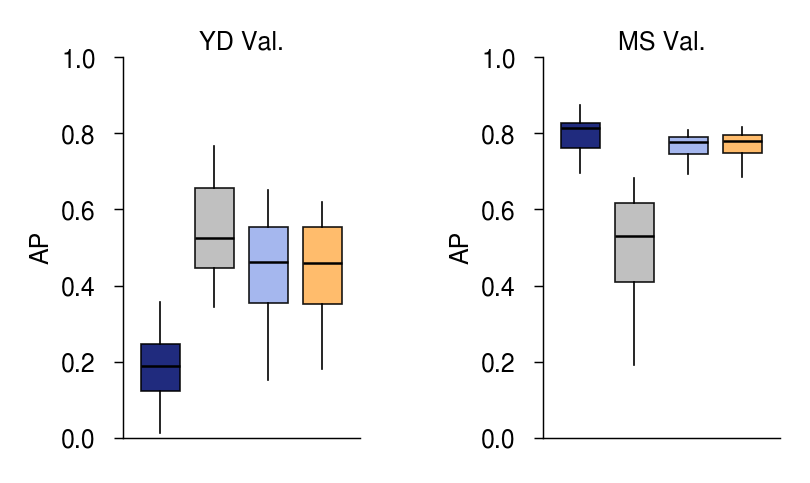

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'YD Val.',
        'df': holec_ap_dfs_avg["assay_val"],
    },
    'ms': {
        'title': 'MS Val.',
        'df': holec_ap_dfs_avg["ms_val_matched"],
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/yd_ms_val_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)

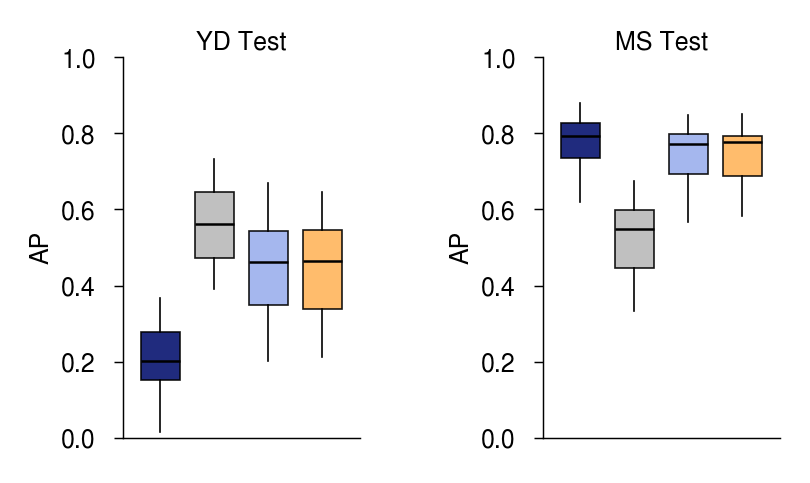

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'YD Test',
        'df': holec_ap_dfs_avg["assay_test"],
    },
    'ms': {
        'title': 'MS Test',
        'df': holec_ap_dfs_avg["ms_test_matched"],
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/yd_ms_test_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


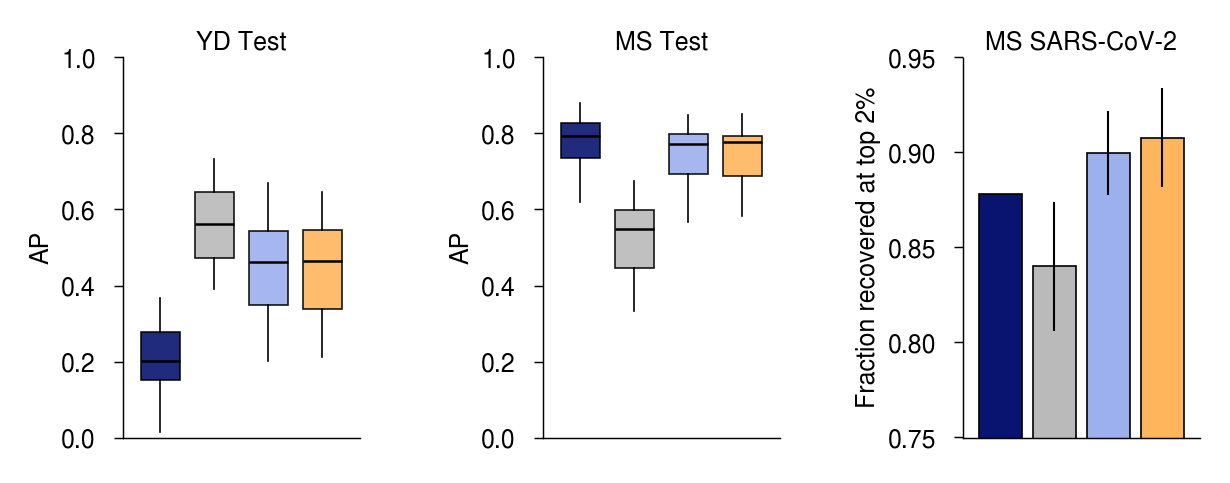

In [ ]:
plot_dict = {
    'assay': {
        'title': 'YD Test',
        'df': holec_ap_dfs_avg["assay_test"],
        'mode': 'box',
    },

    'ms': {
        'title': 'MS Test',
        'df': holec_ap_dfs_avg["ms_test_matched"],
        'mode': 'box',
    },

    'cov': {
        'title': 'MS SARS-CoV-2',
        'df': above_threshold_df_cov_avg,
        'mode': 'bar',
        'interval_df': above_threshold_df_cov_ci,
        'ylim': (0.75, 0.95),
        'interval_linewidth': 0.5,
        'interval_capsize': 0.0,
        'plot_params': {
            'ylabel': 'Fraction recovered at top 2%',
        },
    },
}

fig, axes = plot_model_performance_box_grid_v3(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/yd_ms_cov_test_box_and_barplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)

#### EpiScan experiments

##### R9

In [ ]:
"""
Plotting parameters for boxplots.
"""
score_cols=["mhcprime", "episcan_r9_ft_steps_300_lr_2eN4", "episcan_r9_pepcl_r_dr_steps_300_lr_2eN4", "episcan_r9_pepcl_r_dr_steps_800_lr_2eN4"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["episcan_r9_ft_steps_300_lr_2eN4"],
    'PepCL Default': ["episcan_r9_pepcl_r_dr_steps_300_lr_2eN4"],
    'PepCL': ["episcan_r9_pepcl_r_dr_steps_800_lr_2eN4"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL Default': "#9bb0ed",
    'PepCL': '#ffb55c',
    # 'PepCL Default': "#334a90",
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    # 'figsize': (1.20, 1.65),
    'figsize': (1.40, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,
    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

{'MHCPrime': ['mhcprime'], 'FT': ['episcan_r9_ft_steps_300_lr_2eN4'], 'PepCL Default': ['episcan_r9_pepcl_r_dr_steps_300_lr_2eN4'], 'PepCL': ['episcan_r9_pepcl_r_dr_steps_800_lr_2eN4']}


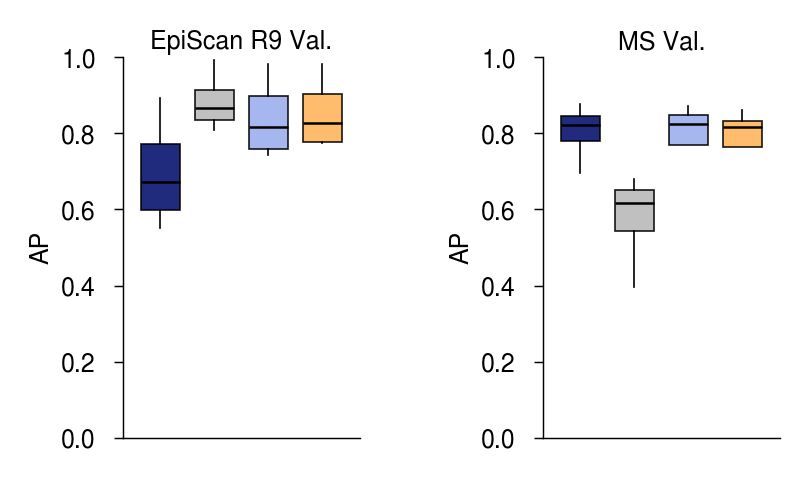

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'EpiScan R9 Val.',
        'df': episcan_r9_ap_dfs_avg["assay_val_mixture"],
    },
    'ms': {
        'title': 'MS Val.',
        'df': episcan_r9_ap_dfs_avg["ms_val_matched"],
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/episcan_r9_ms_val_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


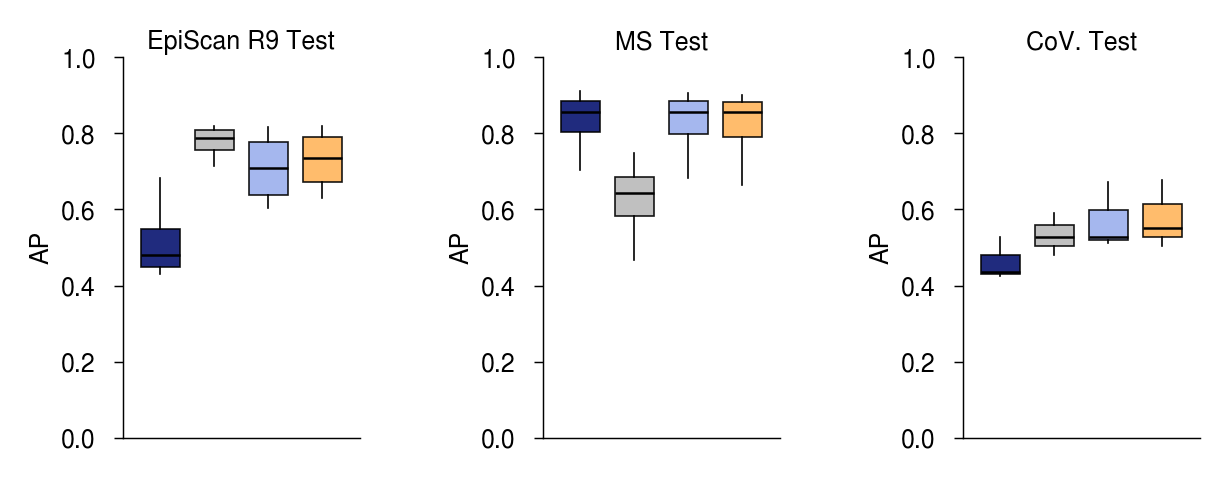

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'EpiScan R9 Test',
        'df': episcan_r9_ap_dfs_avg["assay_test_mixture"],
    },
    'ms': {
        'title': 'MS Test',
        'df': episcan_r9_ap_dfs_avg["ms_test_matched"],
    },
    'cov': {
        'title': 'CoV. Test',
        'df': episcan_r9_ap_dfs_avg["cov_test"],
    },

}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/episcan_r9_ms_cov_test_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


##### R9/RT

In [ ]:
"""
Plotting parameters for boxplots.
"""
score_cols=["mhcprime", "episcan_r9rt_ft_steps_400_lr_2eN4", "episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4", "episcan_r9rt_pepcl_r_dr_steps_400_lr_2eN4"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["episcan_r9rt_ft_steps_400_lr_2eN4"],
    'PepCL Default': ["episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4"],
    'PepCL': ["episcan_r9rt_pepcl_r_dr_steps_400_lr_2eN4"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    # 'PepCL': '#9bb0ed',
    'PepCL Default': "#9bb0ed",
    'PepCL': '#ffb55c',
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    # 'figsize': (1.20, 1.65),
    'figsize': (1.40, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,
    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

{'MHCPrime': ['mhcprime'], 'FT': ['episcan_r9rt_ft_steps_400_lr_2eN4'], 'PepCL Default': ['episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4'], 'PepCL': ['episcan_r9rt_pepcl_r_dr_steps_400_lr_2eN4']}


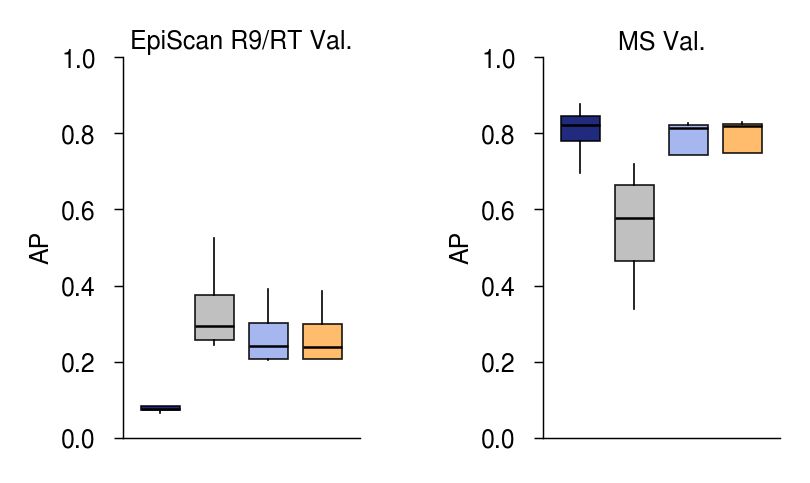

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'EpiScan R9/RT Val.',
        'df': episcan_r9rt_ap_dfs_avg["assay_val_mixture"],
    },
    'ms': {
        'title': 'MS Val.',
        'df': episcan_r9rt_ap_dfs_avg["ms_val_matched"],
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/episcan_r9rt_ms_val_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


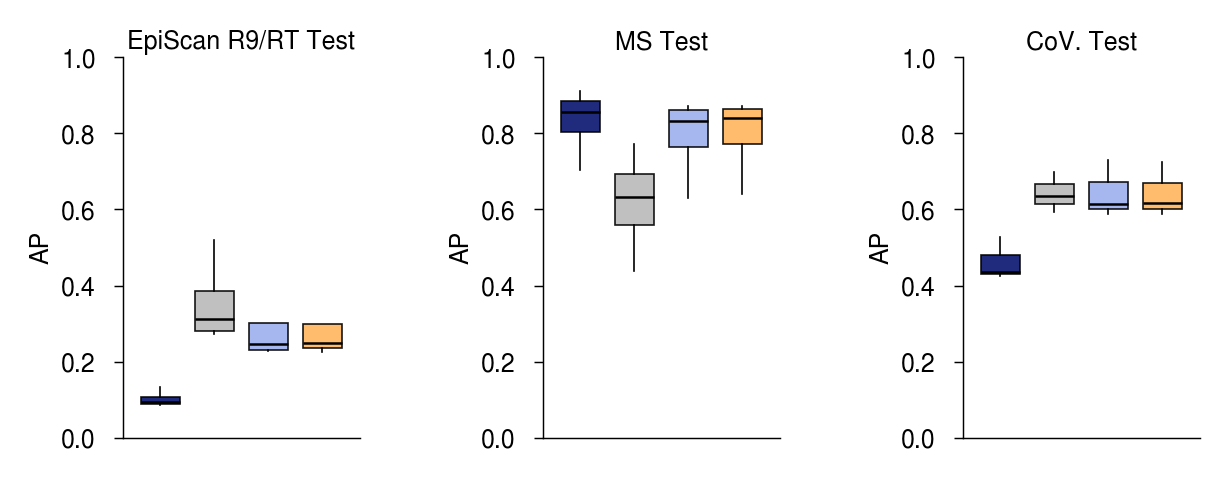

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'EpiScan R9/RT Test',
        'df': episcan_r9rt_ap_dfs_avg["assay_test_mixture"],
    },
    'ms': {
        'title': 'MS Test',
        'df': episcan_r9rt_ap_dfs_avg["ms_test_matched"],
    },
    'cov': {
        'title': 'CoV. Test',
        'df': episcan_r9rt_ap_dfs_avg["cov_test"],
    },

}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/episcan_r9rt_ms_cov_test_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


#### BA CON

In [ ]:
"""
Plotting parameters for boxplots.
"""
score_cols=["mhcprime", "ba_con_ft_steps_200_lr_2eN4", "ba_con_pepcl_r_dr_steps_300_lr_2eN4", "ba_con_pepcl_r_dr_steps_800_lr_2eN4"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["ba_con_ft_steps_200_lr_2eN4"],
    'PepCL Default': ["ba_con_pepcl_r_dr_steps_300_lr_2eN4"],
    'PepCL': ["ba_con_pepcl_r_dr_steps_800_lr_2eN4"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL Default': '#9bb0ed',
    # 'PepCL Default': "#334a90",
    'PepCL': "#ffb55c",
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    # 'figsize': (1.20, 1.65),
    'figsize': (1.40, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,
    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

{'MHCPrime': ['mhcprime'], 'FT': ['ba_con_ft_steps_200_lr_2eN4'], 'PepCL Default': ['ba_con_pepcl_r_dr_steps_300_lr_2eN4'], 'PepCL': ['ba_con_pepcl_r_dr_steps_800_lr_2eN4']}


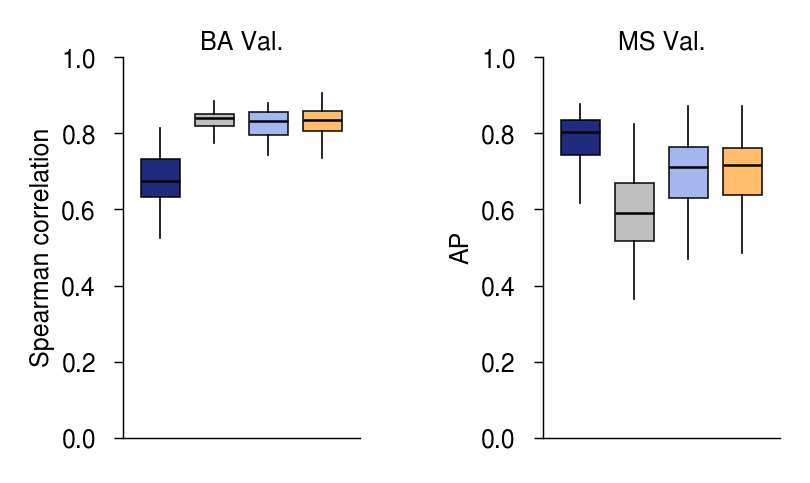

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'BA Val.',
        'df': ba_con_ap_dfs_avg["assay_val"],
        'plot_params': {
            'ylabel': 'Spearman correlation',
        },
    },
    'ms': {
        'title': 'MS Val.',
        'df': ba_con_ap_dfs_avg["ms_val_matched"],
        'plot_params': {
            'ylabel': 'AP',
        },
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/ba_con_ms_val_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)

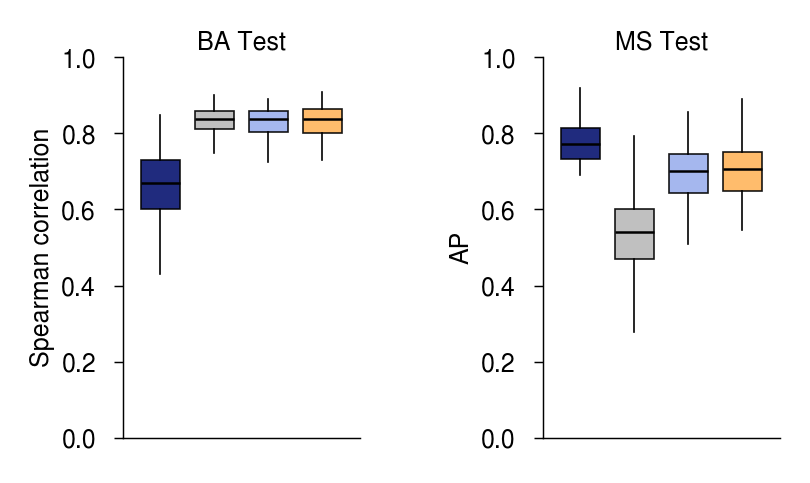

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'BA Test',
        'df': ba_con_ap_dfs_avg["assay_test"],
        'plot_params': {
            'ylabel': 'Spearman correlation',
        },
    },
    'ms': {
        'title': 'MS Test',
        'df': ba_con_ap_dfs_avg["ms_test_matched"],
        'plot_params': {
            'ylabel': 'AP',
        },
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/ba_con_ms_test_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


#### ESCAPE CON

In [ ]:
"""
Plotting parameters for boxplots.
"""
score_cols=["mhcprime", "escape_con_ft_steps_200_lr_2eN4", "escape_con_pepcl_r_dr_steps_300_lr_2eN4"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["escape_con_ft_steps_200_lr_2eN4"],
    'PepCL': ["escape_con_pepcl_r_dr_steps_300_lr_2eN4"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL': '#9bb0ed',
    # 'PepCL Default': '#9bb0ed',
    # 'PepCL Default': "#334a90",
    # 'PepCL': "#ffb55c",
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    # 'figsize': (1.20, 1.65),
    'figsize': (1.40, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,
    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

{'MHCPrime': ['mhcprime'], 'FT': ['escape_con_ft_steps_200_lr_2eN4'], 'PepCL': ['escape_con_pepcl_r_dr_steps_300_lr_2eN4']}


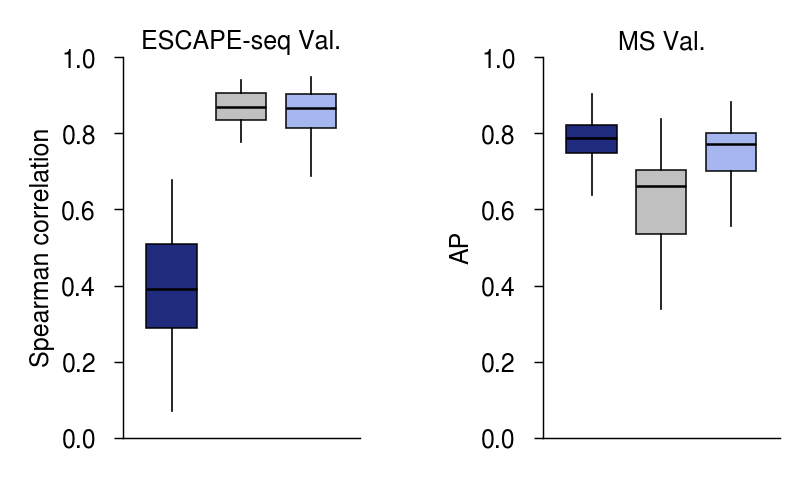

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'ESCAPE-seq Val.',
        'df': escape_con_ap_dfs_avg["assay_val"],
        'plot_params': {
            'ylabel': 'Spearman correlation',
        },
    },
    'ms': {
        'title': 'MS Val.',
        'df': escape_con_ap_dfs_avg["ms_val_matched"],
        'plot_params': {
            'ylabel': 'AP',
        },
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/escape_con_ms_val_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)

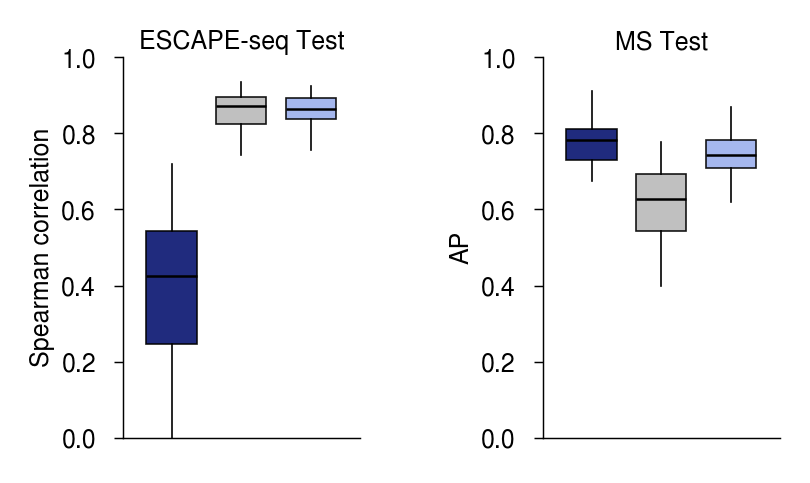

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'ESCAPE-seq Test',
        'df': escape_con_ap_dfs_avg["assay_test"],
        'plot_params': {
            'ylabel': 'Spearman correlation',
        },
    },
    'ms': {
        'title': 'MS Test',
        'df': escape_con_ap_dfs_avg["ms_test_matched"],
        'plot_params': {
            'ylabel': 'AP',
        },
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/escape_con_ms_test_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


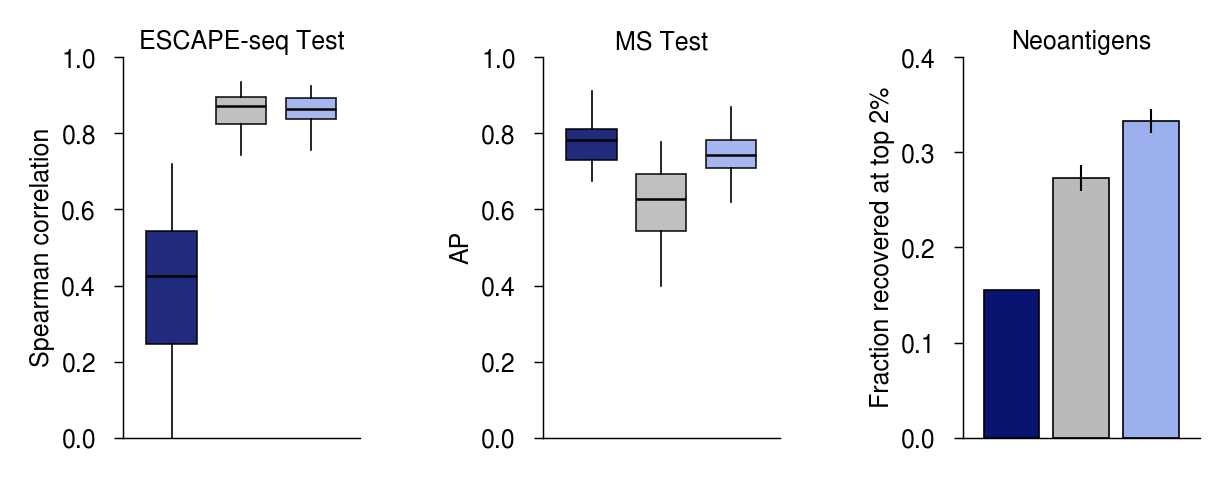

In [ ]:
# with reported neoantigens
# plot all together
plot_dict = {
    'assay': {
        'title': 'ESCAPE-seq Test',
        'df': escape_con_ap_dfs_avg["assay_test"],
        'plot_params': {
            'ylabel': 'Spearman correlation',
        },
    },
    'ms': {
        'title': 'MS Test',
        'df': escape_con_ap_dfs_avg["ms_test_matched"],
        'plot_params': {
            'ylabel': 'AP',
        },
    },
    'neoantigens': {
        'title': 'Neoantigens',
        'df': escapeseq_all_neoantigens_recovery_avg,
        'mode': 'bar',
        'interval_df': escapeseq_all_neoantigens_recovery_ci,
        'ylim': (0, 0.4),
        'interval_linewidth': 0.5,
        'interval_capsize': 0.0,
        'plot_params': {
            'ylabel': 'Fraction recovered at top 2%',
        },
    },
}

fig, axes = plot_model_performance_box_grid_v3(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/escape_con_ms_neoantigens_test_box_and_barplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)


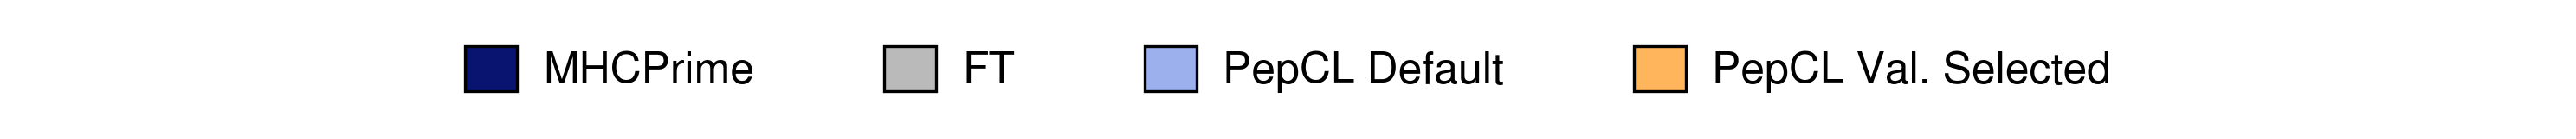

In [ ]:
# legend resized and formatted in illustrator (BA score median line added to legend in illustrator)
plot_horizontal_legend(
    legend_dict={
        'MHCPrime': '#081470',
        'FT': '#bababa',
        'PepCL Default': '#9bb0ed',
        'PepCL Val. Selected': '#ffb55c',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    # save_path=f"{lr_step_var_figures_dir}/pepcl_ft_val_test_plots_legend",
)


#### YD/MS test (version to use in main figures)

 - Plot NMP4.1 BA as a line (import the correct dataframe).

In [ ]:
# get sets with external benchmarking scores
holec_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "Holec_et_al_2025"
holec_test_set_with_benchmarking_model_scores  = pd.read_csv(f"{holec_datasets_dir}/holec_test_set_with_benchmarking_model_scores.csv", index_col=0)

datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data_with_benchmarking_model_scores=pd.read_csv(f"{datasets_dir}/ms_test_data_with_benchmarking_model_scores.csv", index_col=0)

In [ ]:
# get test dfs
holec_test_set=holec_dfs["assay_test"]
ms_test_data=holec_dfs["ms_test_matched"]

In [ ]:
# format
holec_test_set=full_process_data(holec_test_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
holec_test_set=create_seq_allele_column(holec_test_set)

holec_test_set_with_benchmarking_model_scores=full_process_data(holec_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
holec_test_set_with_benchmarking_model_scores=create_seq_allele_column(holec_test_set_with_benchmarking_model_scores)

ms_test_data=full_process_data(ms_test_data, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_test_data=create_seq_allele_column(ms_test_data)

ms_test_data_with_benchmarking_model_scores=full_process_data(ms_test_data_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_test_data_with_benchmarking_model_scores=create_seq_allele_column(ms_test_data_with_benchmarking_model_scores)

In [ ]:
# map scores
seq_allele_to_ba_score=dict(zip(ms_test_data_with_benchmarking_model_scores.seq_allele, ms_test_data_with_benchmarking_model_scores.BA_score))
ms_test_data["BA_score"]=ms_test_data.seq_allele.map(seq_allele_to_ba_score)

seq_allele_to_ba_score=dict(zip(holec_test_set_with_benchmarking_model_scores.seq_allele, holec_test_set_with_benchmarking_model_scores.BA_score))
holec_test_set["BA_score"]=holec_test_set.seq_allele.map(seq_allele_to_ba_score)

In [ ]:
# get ba
score_cols=["BA_score"]

# ms test set (matched allele-length distribution)
ms_test_data["seq_len"]=ms_test_data.seq.str.replace("$", "").apply(len)
ms_allele_ap_df=compute_ap_matrix_optimized(ms_test_data[ms_test_data.allele.isin(holec_test_set.allele.unique().tolist())].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

# holec test set
holec_allele_ap_df=compute_ap_matrix_optimized(holec_test_set, score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

In [ ]:
# ba holec
holec_ap_dfs_w_ba={"ms_test_matched": ms_allele_ap_df, "assay_test": holec_allele_ap_df}

holec_ap_dfs_avg=merge_two_dicts_by_keys(holec_ap_dfs_avg, holec_ap_dfs_w_ba, ["ms_test_matched", "assay_test"])

In [ ]:

"""
Plotting parameters for boxplots.
"""
score_cols=["mhcprime", "holec_ft_steps_300_lr_2eN4", "holec_pepcl_r_dr_steps_300_lr_2eN4"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["holec_ft_steps_300_lr_2eN4"],
    'PepCL': ["holec_pepcl_r_dr_steps_300_lr_2eN4"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL': '#9bb0ed',
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    'figsize': (1.20, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,
    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)

{'MHCPrime': ['mhcprime'], 'FT': ['holec_ft_steps_300_lr_2eN4'], 'PepCL': ['holec_pepcl_r_dr_steps_300_lr_2eN4']}


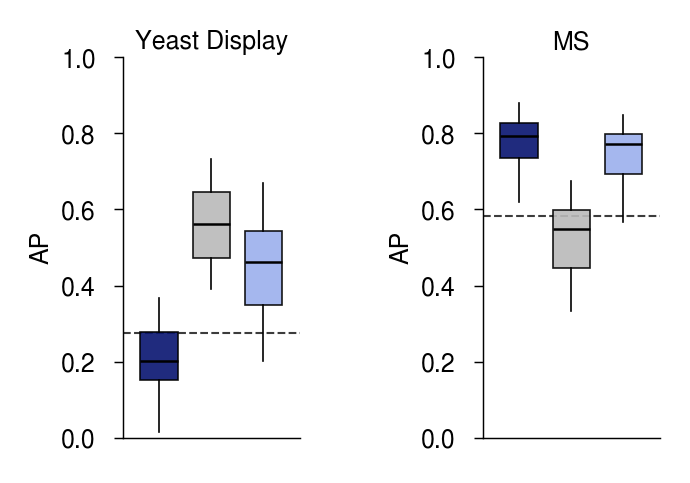

In [ ]:
# plot all together
plot_dict = {
    'yeast_display': {
        'title': 'Yeast Display',
        'df': holec_ap_dfs_avg["assay_test"],
    },
    'ms_for_yeast': {
        'title': 'MS',
        'df': holec_ap_dfs_avg["ms_test_matched"],
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/fig4_a_yd_ms_updating_per_allele_ap_boxplots_updated",
    panel_gap=0.00,
    grid_dpi=300,
    reference_hlines={
        'BA_score': {
            'color': "#3c3c3c", 'linestyle': '--', 'linewidth': 0.5,
            'label': 'BA score (100%)', 
            'agg': 'median',   
        }, # 'alpha': 0.8,
    },
    **plotting_parameters,
)


In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    # ap dfs
    ms_allele_ap_df.to_csv(f"{associated_data_dir}/ms_allele_ap_df.csv")
    holec_allele_ap_df.to_csv(f"{associated_data_dir}/holec_allele_ap_df.csv")

#### YD net benefit figure w/ intervals included (version to use for main figures)

In [ ]:
# get the net beenfits and cis
prefix_map={
    "ft_net_benefit": "holec_ft_steps_300_lr_2eN4",
    "pepcl_net_benefit": "holec_pepcl_r_dr_steps_300_lr_2eN4",
}

ft_pepcl_tradeoff_df, ft_pepcl_tradeoff_ci_df = compute_seeded_net_adaptation_benefit(
    ms_df=holec_ap_dfs["ms_test_matched"],
    assay_df=holec_ap_dfs["assay_test"],
    base_col="mhcprime",
    prefix_map=prefix_map,
    ci_level=0.95,
)

ft_pepcl_tradeoff_df.sort_values(
    by="pepcl_net_benefit",
    ascending=False,
    inplace=True,
)

ft_pepcl_tradeoff_ci_df=ft_pepcl_tradeoff_ci_df.loc[
    ft_pepcl_tradeoff_df.index
]

def format_allele_index(df):
    df=df.copy()
    df.index=df.index.map(lambda a:f"{a[0]}*{a[1:3]}:{a[3:]}")
    return df

ft_pepcl_tradeoff_df=format_allele_index(ft_pepcl_tradeoff_df)
ft_pepcl_tradeoff_ci_df=format_allele_index(ft_pepcl_tradeoff_ci_df)

ft_net_benefit: prefix='holec_ft_steps_300_lr_2eN4', replicates=[0, 1, 2, 3, 4, 5, 6, 7, 8], n=9
pepcl_net_benefit: prefix='holec_pepcl_r_dr_steps_200_lr_2eN4', replicates=[0, 1, 2, 3, 4, 5, 6, 7, 8], n=9


In [ ]:
# plot the net benefit plot
plot_bar_grouped_advanced_v2(
    ft_pepcl_tradeoff_df,
    ["pepcl_net_benefit", "ft_net_benefit"],
    interval_df=ft_pepcl_tradeoff_ci_df,
    figsize=(7.5, 6),
    dpi=300,
    default_font='Nimbus Sans',
    bar_width=0.8,
    bar_edgecolor='black',
    bar_edgewidth=0.8,
    alpha=1.0,
    group_spacing=0.5,
    colors=["#9bb0ed", "#bababa"],
    # horizontal=False,
    horizontal=True,
    xlabel='Holec/MS performance trade-off',
    ylabel="",
    xlabel_fontsize=10,
    ylabel_fontsize=10,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    title='',
    title_fontsize=12,
    title_bold=True,
    xtick_labelsize=8,
    ytick_labelsize=8,
    tick_length=8.0,
    tick_width=0.5,
    tick_direction='out',
    rotation=0,
    axis_linewidth=0.5,
    ylim=None,
    xlim=None,
    grid_alpha=0.0,
    legend_mode='none',
    # save_path=f"{lr_step_var_figures_dir}/fig4_b_yd_ms_trade_off_barplot_updated",
)


#### YD/MS net benefit individual scatterplots (for revisions)

In [ ]:
# get holec gain/ms loss (components for net benefit metric)
gain_loss_groups=compute_grouped_holec_gain_ms_loss(
    ms_df=holec_ap_dfs["ms_test_matched"],
    holec_df=holec_ap_dfs["assay_test"],
    base_col="mhcprime",
    prefix_groups={
        "holec_ft": "holec_ft_steps_300_lr_2eN4",
        "holec_pepcl": "holec_pepcl_r_dr_steps_300_lr_2eN4",
    },

    format_alleles=True,
    add_allele_col=True,
)

holec_ft: averaged 9 columns
  holec_ft_steps_300_lr_2eN4_seed_0
  holec_ft_steps_300_lr_2eN4_seed_1
  holec_ft_steps_300_lr_2eN4_seed_2
  holec_ft_steps_300_lr_2eN4_seed_3
  holec_ft_steps_300_lr_2eN4_seed_4
  holec_ft_steps_300_lr_2eN4_seed_5
  holec_ft_steps_300_lr_2eN4_seed_6
  holec_ft_steps_300_lr_2eN4_seed_7
  holec_ft_steps_300_lr_2eN4_seed_8
holec_pepcl: averaged 9 columns
  holec_pepcl_r_dr_steps_300_lr_2eN4_seed_0
  holec_pepcl_r_dr_steps_300_lr_2eN4_seed_1
  holec_pepcl_r_dr_steps_300_lr_2eN4_seed_2
  holec_pepcl_r_dr_steps_300_lr_2eN4_seed_3
  holec_pepcl_r_dr_steps_300_lr_2eN4_seed_4
  holec_pepcl_r_dr_steps_300_lr_2eN4_seed_5
  holec_pepcl_r_dr_steps_300_lr_2eN4_seed_6
  holec_pepcl_r_dr_steps_300_lr_2eN4_seed_7
  holec_pepcl_r_dr_steps_300_lr_2eN4_seed_8


In [ ]:
# color palette
allele_colors = {
    "A*01:01": "#081470",
    "A*02:01": "#657fae",
    "A*03:01": "#6D83FF",
    "A*11:01": "#5A4D98",
    "A*24:02": "#7DCBBB",
    "A*30:01": "#5F968D",
    "A*30:02": "#1F3C37",
    "B*35:02": "#FBE183",
    "B*35:03": "#ffdea4",
    "B*39:01": "#ffb55c",
    "B*55:02": "#ab7532",
    "B*58:01": "#ff8d03",
    "C*01:02": "#ffc7cc",
    "C*03:03": "#DA7C81",
    # "C*04:01": "#a4a4a4",
    # "C*12:02": "#2E8B8B",
    "C*04:01": "#d34a4d",
    "C*12:02": "#641A1E",
}

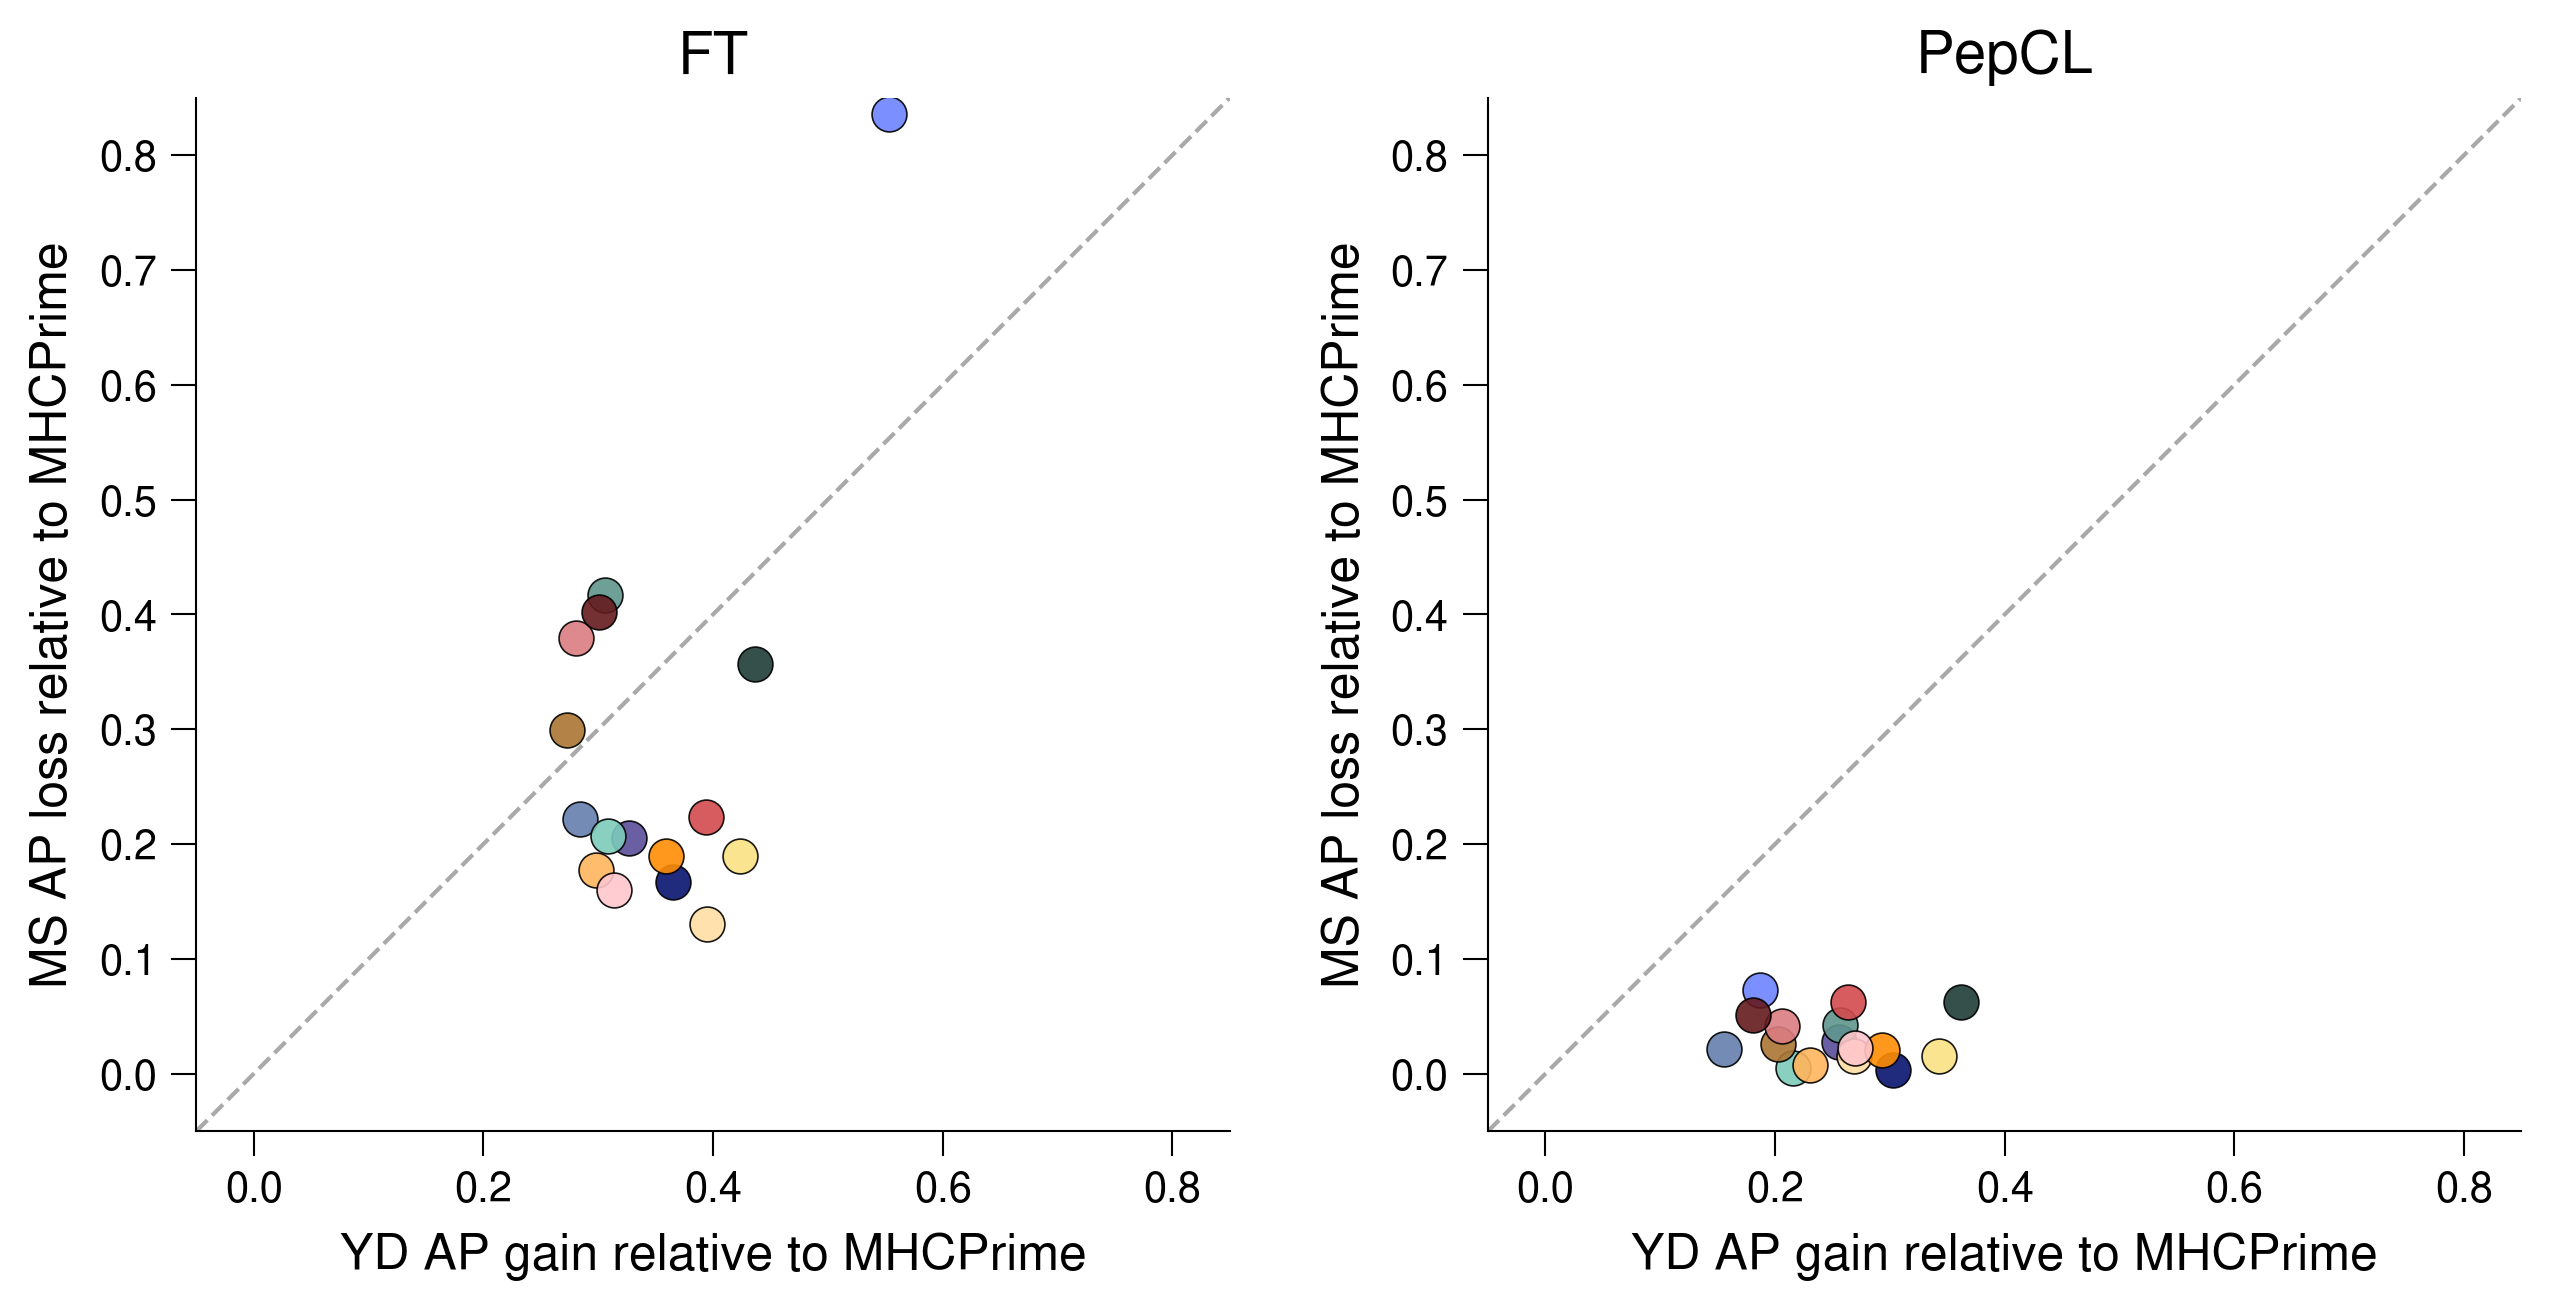

In [ ]:
# per allele ap comparison between MHCPrime and HLApollo
_=plot_dual_scatter(
    df1=gain_loss_groups["holec_ft"],
    df2=gain_loss_groups["holec_pepcl"],
    x_col='holec_gain',
    y_col='ms_loss',
    xlabel='YD AP gain relative to MHCPrime',
    ylabel='MS AP loss relative to MHCPrime',
    title1="FT",
    title2="PepCL",
    hue_col='allele',
    hue_colors=allele_colors,
    hue_order=list(allele_colors.keys()),
    point_size=70,
    point_alpha=0.9,
    point_edge_color='black',
    point_edge_width=0.4,
    show_xy_line=True,
    xy_line_color='darkgray',
    xy_line_style='--',
    xy_line_width=1,
    figsize=(10, 6),
    dpi=300,
    equal_aspect=True,
    remove_top_right_spines=True,
    spine_width=0.5,
    tick_length=6.0,
    xtick_labelsize=10,
    ytick_labelsize=10,
    xlabel_fontsize=12,
    ylabel_fontsize=12,
    xlabel_pad=5.0,
    ylabel_pad=5.0,
    default_font='Nimbus Sans',
    show_legend=False,
    xlim=(-0.05,0.85),
    ylim=(-0.05,0.85),
    # save_path=f"{lr_step_var_figures_dir}/ft_and_pepcl_holec_gain_ms_loss_scatterplots",
)

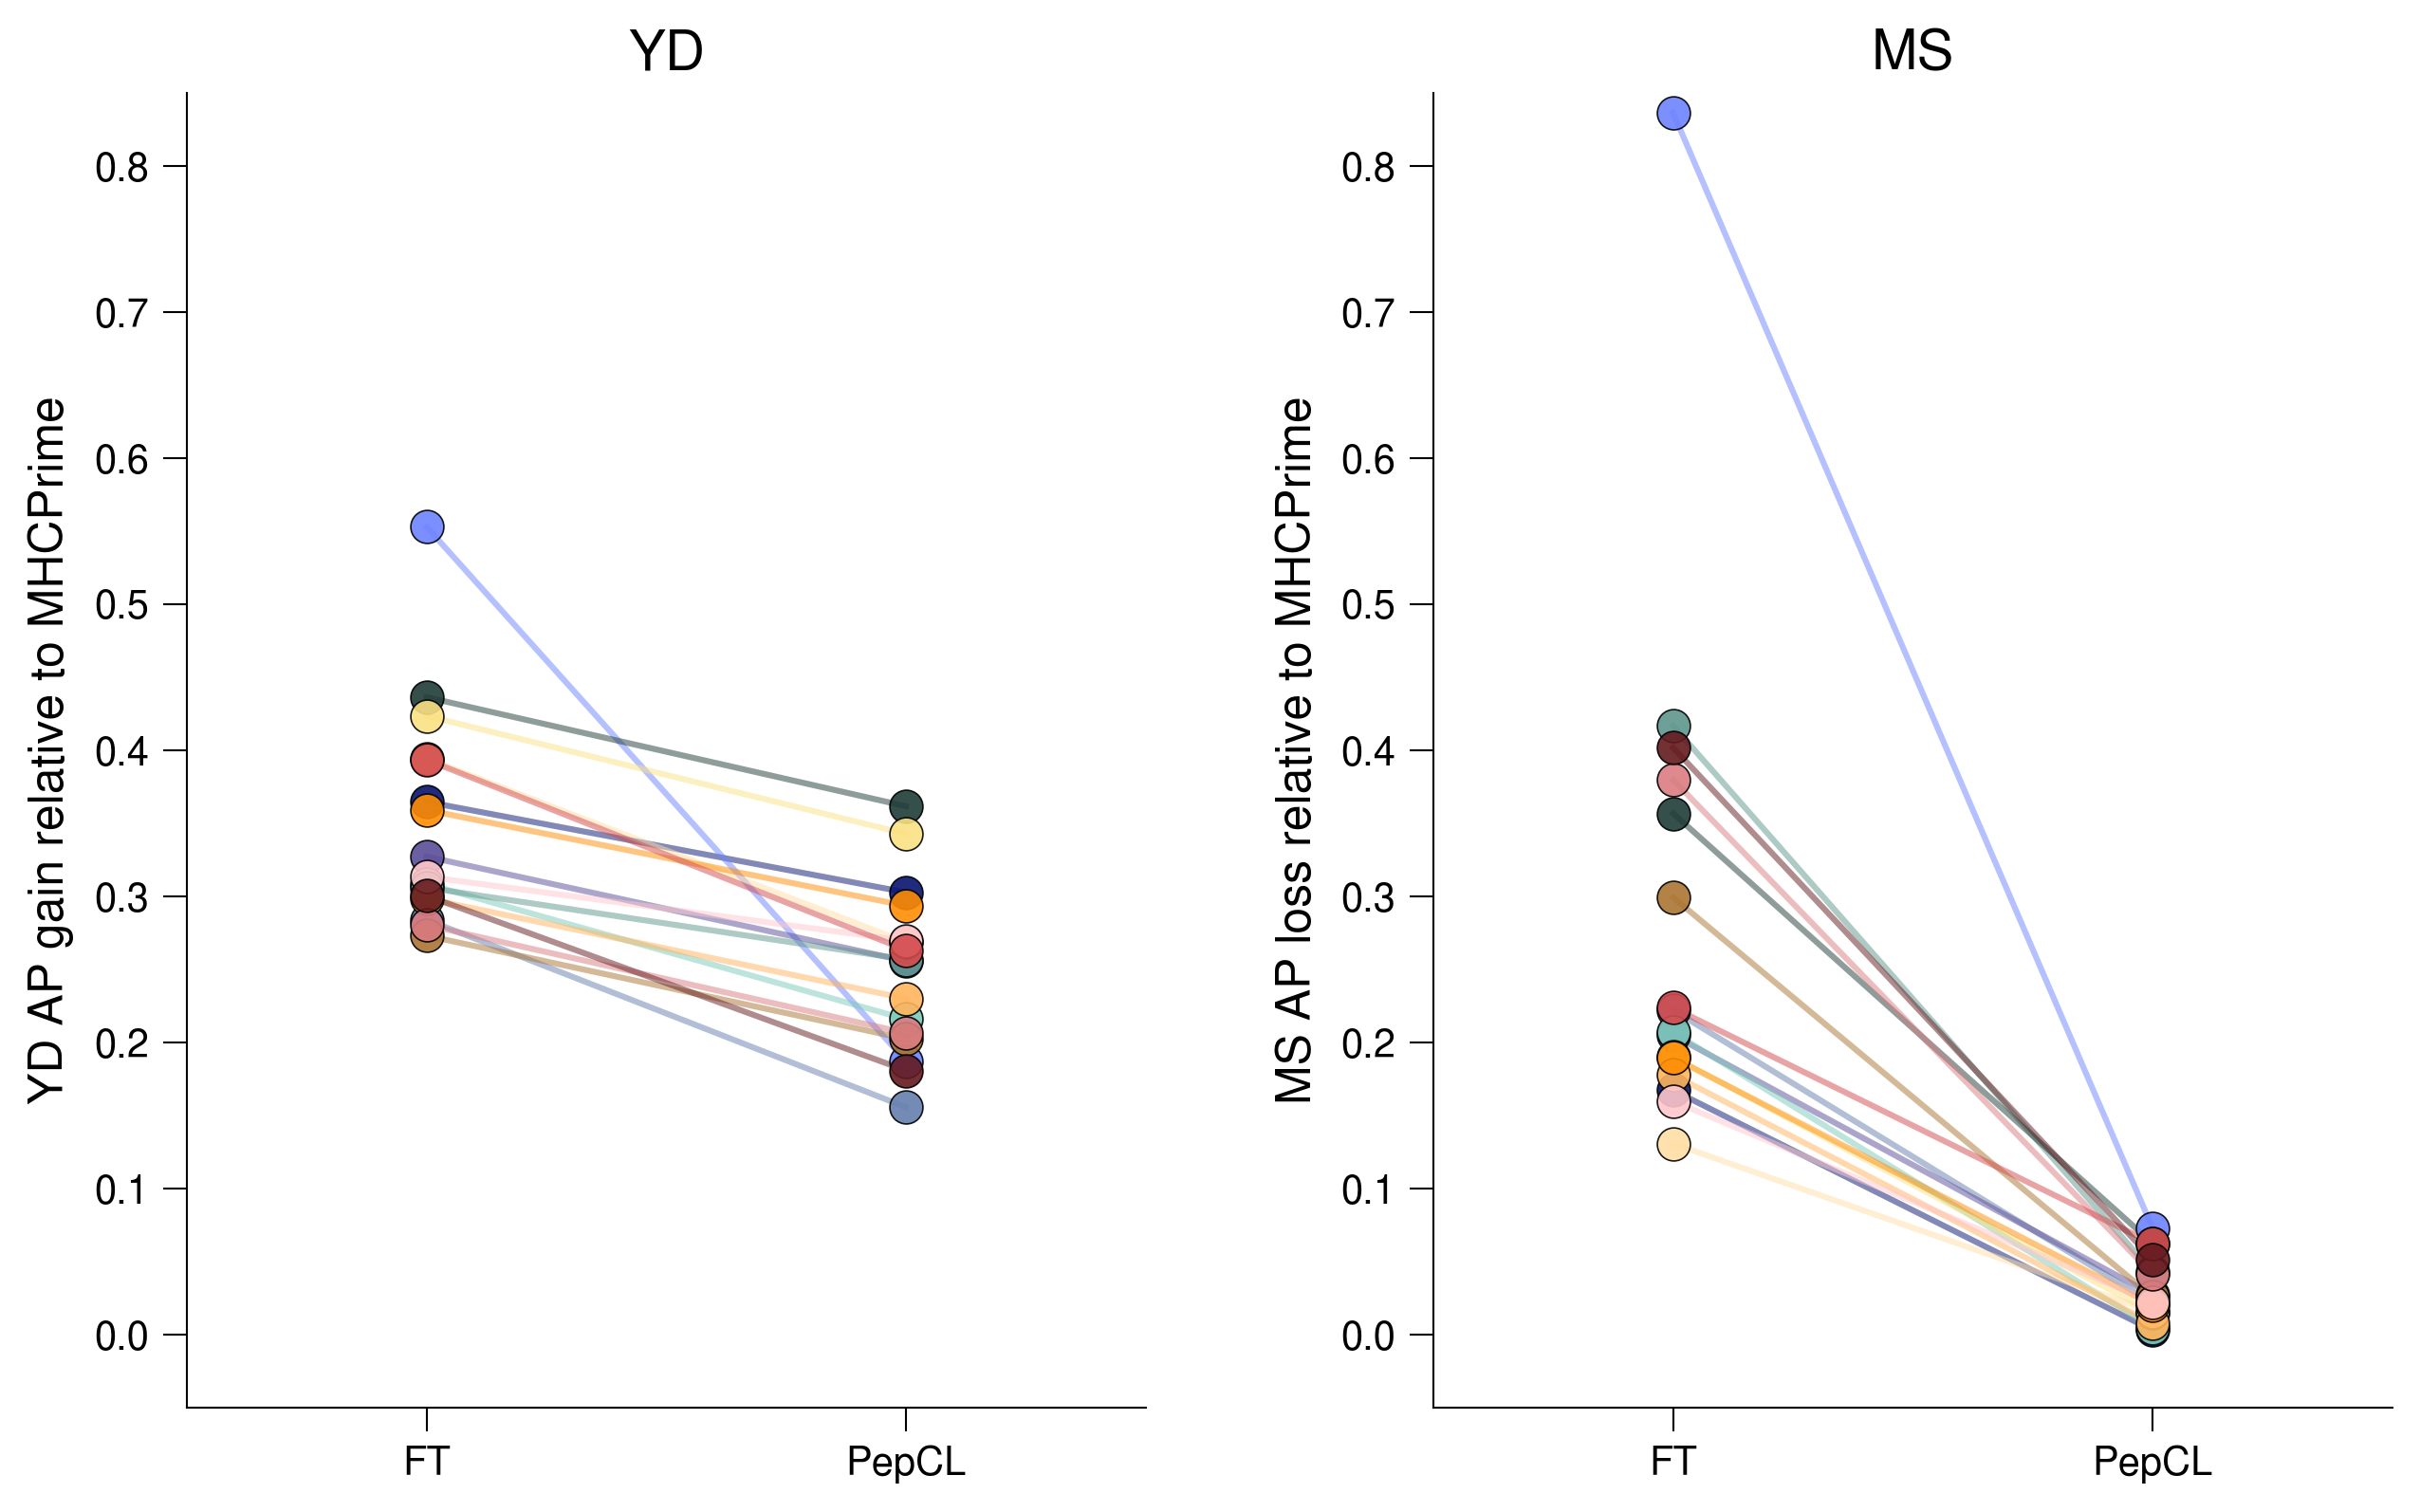

In [ ]:
# plot ladder plots comparing the holec gain or ms loss across ft and pepcl
_=plot_dual_ladder(
    df1=gain_loss_groups["holec_ft"],
    df2=gain_loss_groups["holec_pepcl"],
    value_cols=['holec_gain', 'ms_loss'],
    df1_label='FT',
    df2_label='PepCL',
    titles=['YD', 'MS'],
    ylabel=['YD AP gain relative to MHCPrime', 'MS AP loss relative to MHCPrime'],
    hue_col='allele',
    hue_colors=allele_colors,
    hue_order=list(allele_colors.keys()),
    point_size=70,
    point_alpha=0.9,
    point_edge_color='black',
    point_edge_width=0.4,
    connector_width=1.5,
    connector_alpha=0.5,
    figsize=(10, 6),
    dpi=300,
    remove_top_right_spines=True,
    spine_width=0.5,
    tick_length=6.0,
    xtick_labelsize=10,
    ytick_labelsize=10,
    ylabel_fontsize=12,
    ylabel_pad=5.0,
    x_jitter=0.0,
    default_font='Nimbus Sans',
    show_legend=False,
    ylim=(-0.05, 0.85),
    # save_path=f"{lr_step_var_figures_dir}/ft_and_pepcl_holec_gain_ms_loss_ladderplots",
)

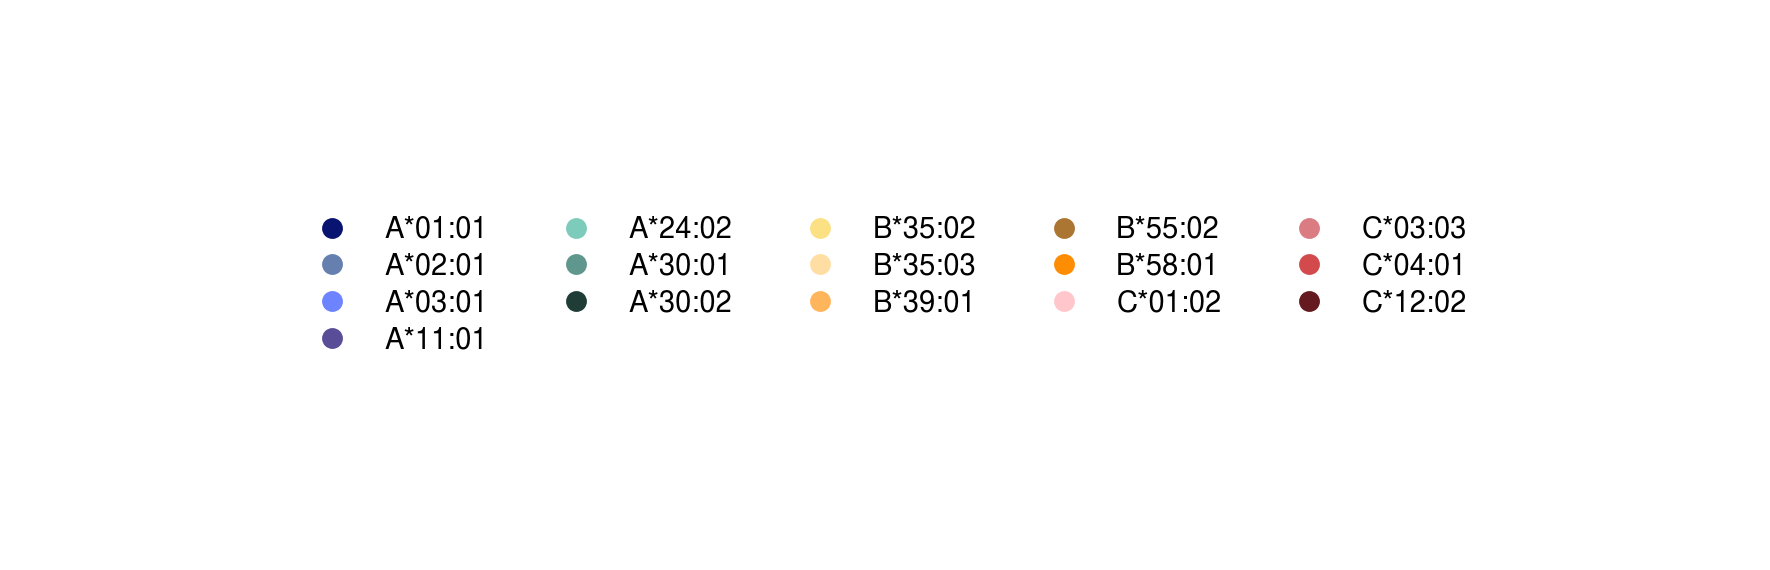

In [ ]:
# legend adjusted in illustrator
plot_legend(
    allele_colors,
    ncol=5, 
    figsize=(6, 2), # display size
    # figsize=(25, 6), # download size
    dpi=300, 
    fontsize=7, 
    marker='o', 
    marker_size=4,
    default_font='Nimbus Sans', 
    row_spacing=0.3,
    # save_path=f"{lr_step_var_figures_dir}/scatter_ladder_plots_legend",
)

#### YD/MS mixture results

In [ ]:
# merge test dfs
holec_dfs_ds_merged=merge_dfs_by_prefix(holec_dfs_ds, ["ms_test_matched", "assay_test"])

# create full ap df
holec_dfs_test=merge_two_dicts_by_keys(holec_dfs, holec_dfs_ds_merged, ["ms_test_matched", "assay_test"])

In [ ]:
%%time
# compute the mixture
delta_mean_df,delta_var_df,delta_ci_df = compute_mixed_ms_holec_ft_pepcl_delta_from_base(
    ms_df=holec_dfs_test["ms_test_matched"],
    holec_df=holec_dfs_test["assay_test"],
    base_col="mhcprime",
    ft_prefix="holec_ft_steps_300_lr_2eN4",
    pepcl_prefix="holec_pepcl_r_dr_steps_200_lr_2eN4",
    ft_output_col="holec_ft",
    pepcl_output_col="holec_pepcl",
    allele_col="allele",
    ms_label_col="label",
    holec_label_col="label",
    neg_per_pos_ratio=99,
    mix_step_pct=10,
    n_iterations=100,
    interval_pct=95,
    random_state=42,
    show_progress=True
)

FT prefix: holec_ft_steps_300_lr_2eN4
PepCL prefix: holec_pepcl_r_dr_steps_200_lr_2eN4
Replicates: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Mixture iterations: 100
Empirical interval: 95%
Usable alleles: 16 / 16


MS/YD mixtures: 100%|██████████| 11/11 [03:25<00:00, 18.65s/it]

Finished mixture analysis.
Each plotted point averages 100 independently sampled mixtures; each mixture value first averages 9 model replicates.
CPU times: user 3min 25s, sys: 981 ms, total: 3min 26s
Wall time: 3min 25s


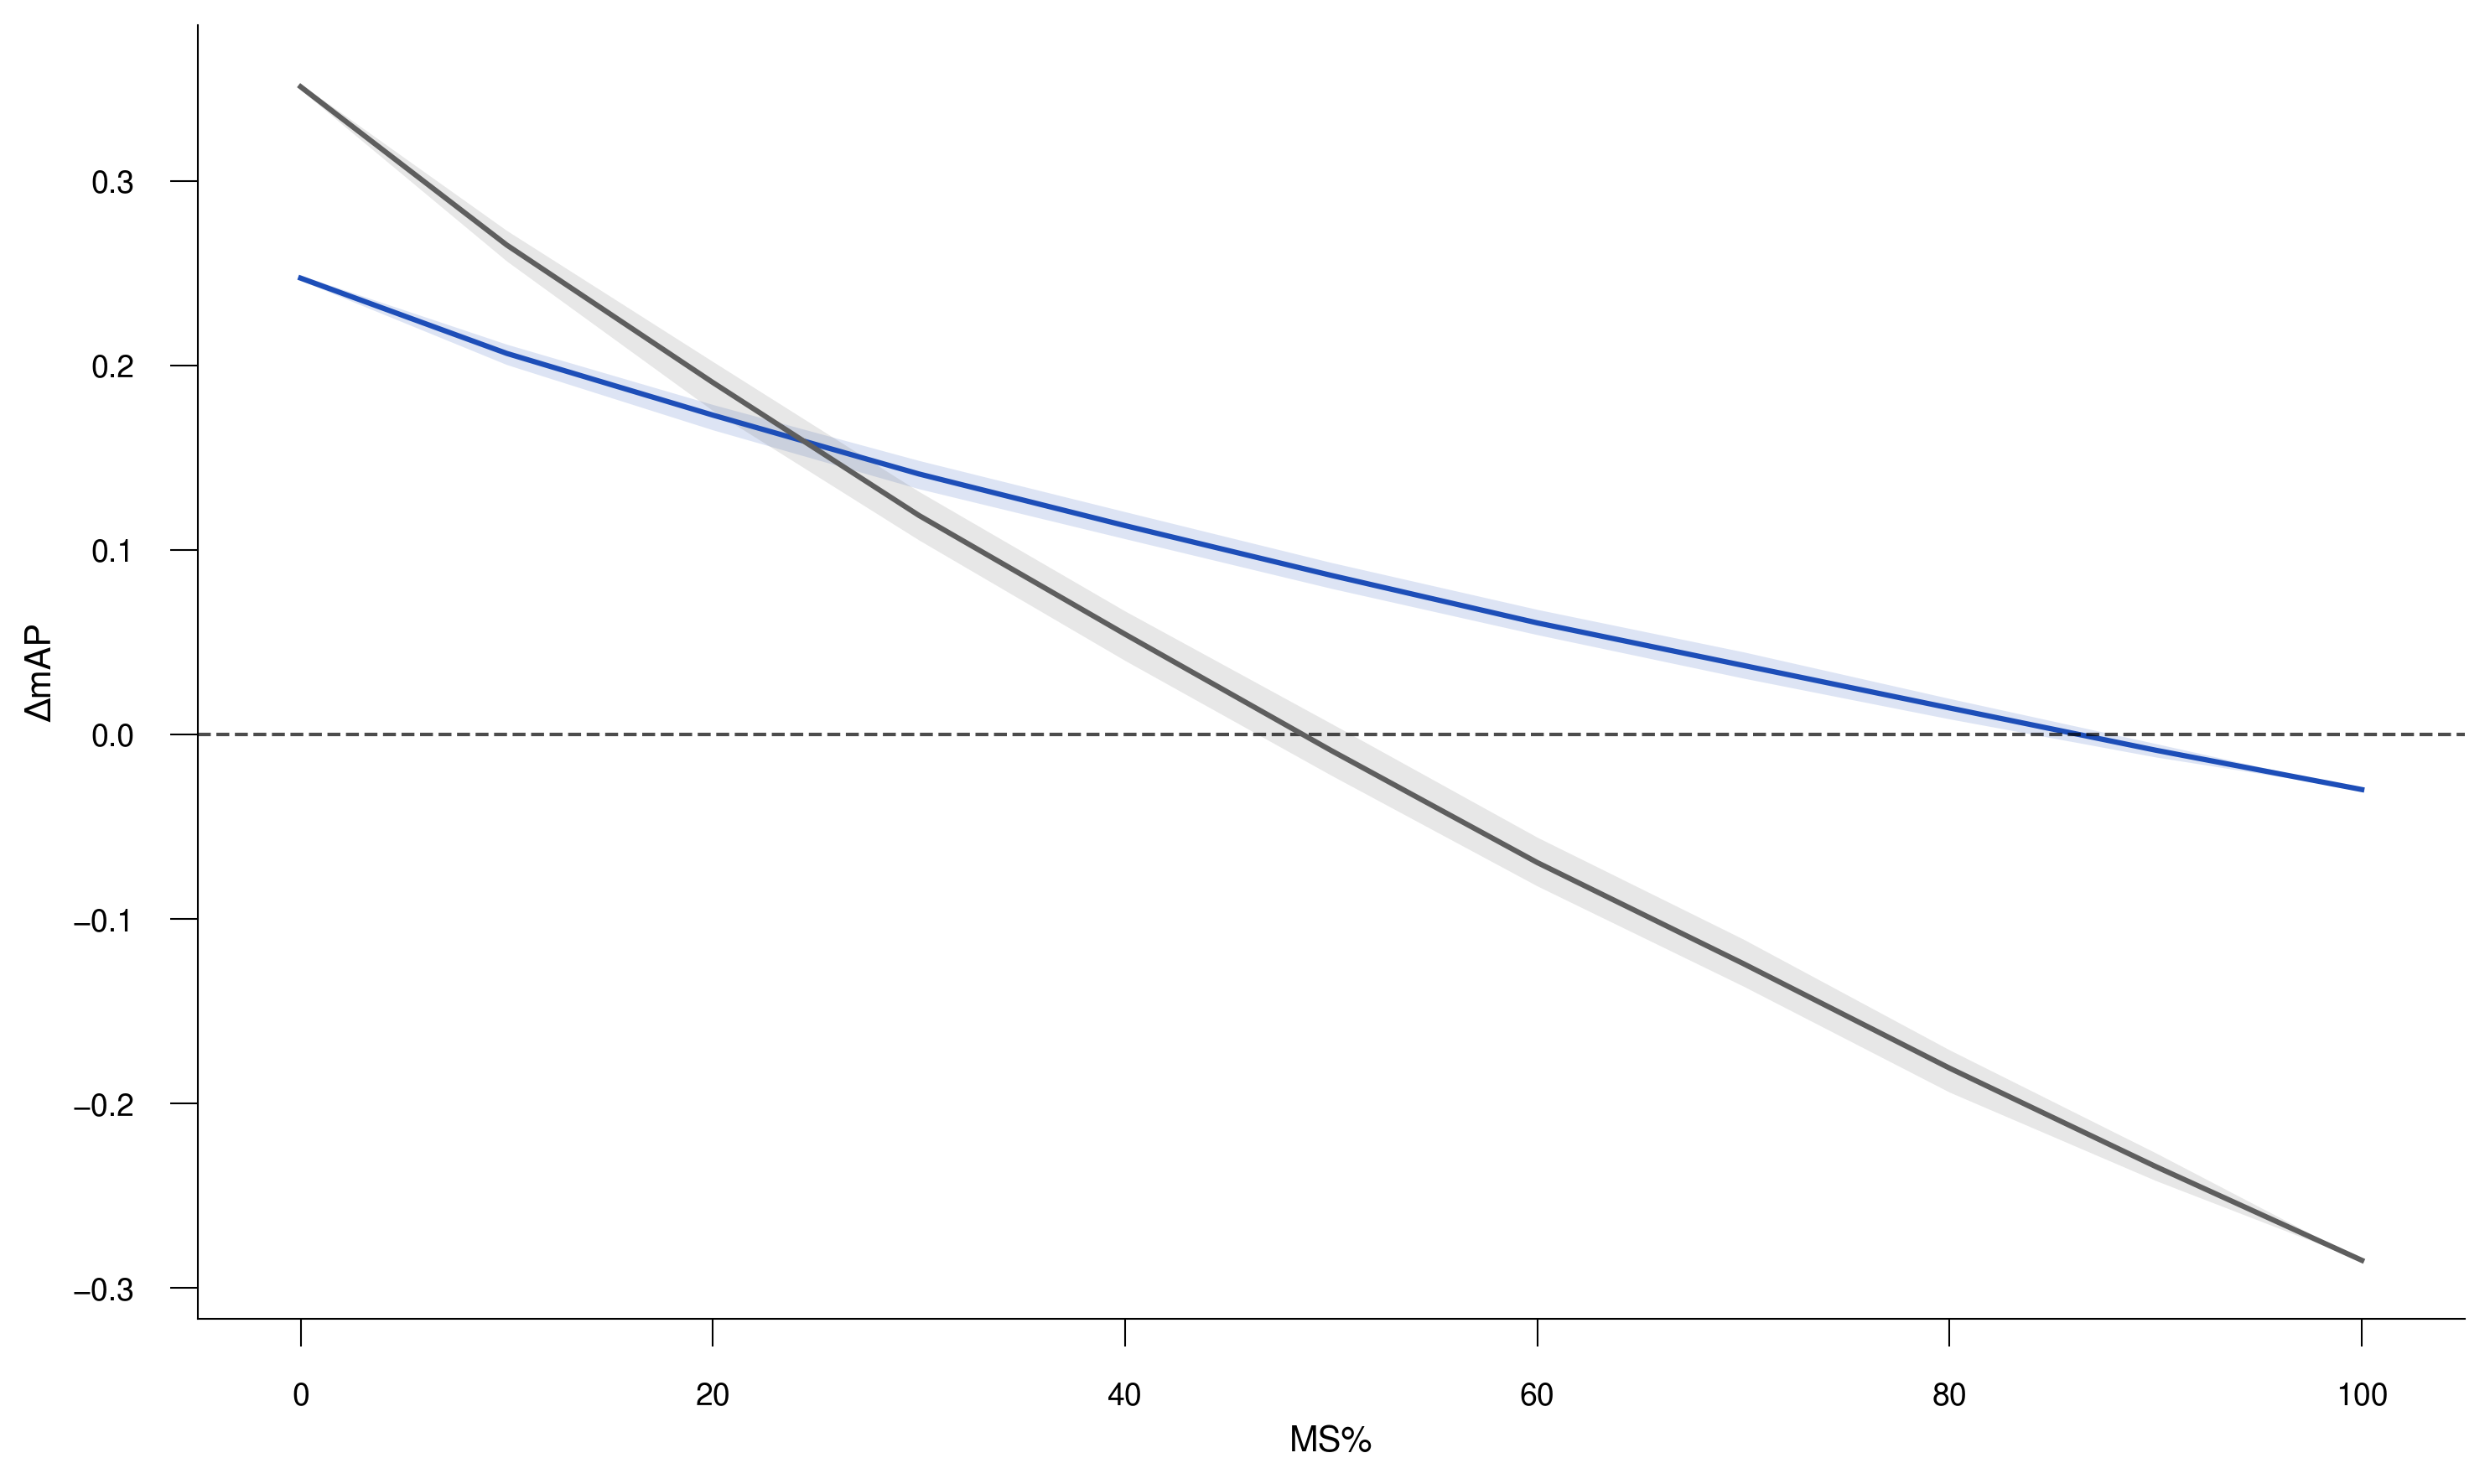

In [ ]:
# plot mixture analysis results

# NOTE (for revisions): colors were flipped, please correct, resave, and update in illustrator as well.

line_styles = {
    'holec_ft': {
        'color': '#5E5E5E', # post correction
        'linewidth': 1.5,
        'linestyle': '-',
        'marker': None,
        'alpha': 1.0,
        'zorder': 2,
        'ci_color': '#5E5E5E', # post correction
        'ci_alpha': 0.15,
    },
    'holec_pepcl': {
        'color': "#1D4EB8", # post correction
        'linewidth': 1.5,
        'linestyle': '-',
        'marker': None,
        'alpha': 1.0,
        'zorder': 1,
        'ci_color': '#1D4EB8', # post correction
        'ci_alpha': 0.15,
    },
}

plot_lines(
    delta_mean_df.reset_index(),
    x_col="ms_percentage",
    y_cols=["holec_ft", "holec_pepcl"],
    line_styles=line_styles,
    ci_df=delta_ci_df.reset_index(),
    figsize=(10, 6),
    dpi=300,
    default_font='Nimbus Sans',
    xlabel='MS%',
    ylabel='ΔmAP',
    xlabel_fontsize=10,
    ylabel_fontsize=10,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    title='',
    title_fontsize=12,
    title_bold=True,
    xtick_labelsize=9,
    ytick_labelsize=9,
    tick_length=8.0,
    tick_width=0.5,
    tick_direction='out',
    xtick_rotation=0,
    axis_linewidth=0.5,
    xlim=None,
    ylim=None,
    grid_alpha=0.0,
    legend_mode=None,
    legend_loc='upper right',
    legend_bbox=None,
    legend_ncol=1,
    legend_fontsize=9,
    legend_handle_size=1.0,
    hline_y=0.0,
    hline_color='black',
    hline_width=1.0,
    hline_style='--',
    hline_alpha=0.7,
    # save_path=f"{lr_step_var_figures_dir}/fig4_c_yd_ms_mixture_lineplots_updated",
)

#### EpiScan scatterplots (version to use in the main figures)

In [ ]:
# ms and episcan test sets

# ms
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)
ms_test_data_with_benchmarking_model_scores=pd.read_csv(f"{datasets_dir}/ms_test_data_with_benchmarking_model_scores.csv", index_col=0)

# episcan
episcan_train_test_dir = DATA_DIR / "Training_Datasets" / "Processed" / "EpiScan"
episcan_r9_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_test_set.csv", index_col=0)
episcan_rt_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_test_set.csv", index_col=0)
sd3_formatted=pd.read_csv(f"{episcan_train_test_dir}/sd3_formatted.csv", index_col=0)

episcan_r9_test_set_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_test_set_with_benchmarking_model_scores.csv", index_col=0)
episcan_rt_test_set_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_test_set_with_benchmarking_model_scores.csv", index_col=0)
sd3_formatted_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/sd3_formatted_with_benchmarking_model_scores.csv", index_col=0)

In [ ]:
# process
ms_test_data=full_process_data(ms_test_data, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_test_data=create_seq_allele_column(ms_test_data)

ms_test_data_with_benchmarking_model_scores=full_process_data(ms_test_data_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_test_data_with_benchmarking_model_scores=create_seq_allele_column(ms_test_data_with_benchmarking_model_scores)

episcan_r9_test_set=full_process_data(episcan_r9_test_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_r9_test_set=create_seq_allele_column(episcan_r9_test_set)

episcan_rt_test_set=full_process_data(episcan_rt_test_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_rt_test_set=create_seq_allele_column(episcan_rt_test_set)

sd3_formatted=full_process_data(sd3_formatted, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
sd3_formatted=create_seq_allele_column(sd3_formatted)

episcan_r9_test_set_with_benchmarking_model_scores=full_process_data(episcan_r9_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_r9_test_set_with_benchmarking_model_scores=create_seq_allele_column(episcan_r9_test_set_with_benchmarking_model_scores)

episcan_rt_test_set_with_benchmarking_model_scores=full_process_data(episcan_rt_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_rt_test_set_with_benchmarking_model_scores=create_seq_allele_column(episcan_rt_test_set_with_benchmarking_model_scores)

sd3_formatted_with_benchmarking_model_scores=full_process_data(sd3_formatted_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
sd3_formatted_with_benchmarking_model_scores=create_seq_allele_column(sd3_formatted_with_benchmarking_model_scores)

In [ ]:
# merge external model score cols
external_model_score_cols=['seq_allele', 'mhc_pred_0', 'munis', 'bigmhc', 'score', 'presentation_score', 'capsnetmhc_anthem', 'EL_score', 'Neo_score_nmp42',  'BA_score', 'Pathogen_score_nmp42', 'transphla', "capsnetmhc_iedb", 'deepattentionpan'] # add seq allele for merging

ms_test_data = pd.merge(ms_test_data, ms_test_data_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')
episcan_r9_test_set = pd.merge(episcan_r9_test_set, episcan_r9_test_set_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')
episcan_rt_test_set = pd.merge(episcan_rt_test_set, episcan_rt_test_set_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')
sd3_formatted = pd.merge(sd3_formatted, sd3_formatted_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')

In [ ]:
# merge episcan across mixtures (and covid data)
episcan_r9_ds_merged=merge_dfs_by_prefix(episcan_r9_dfs_ds, ["ms_test_matched", "assay_test", "cov_test"])
episcan_r9rt_ds_merged=merge_dfs_by_prefix(episcan_r9rt_dfs_ds, ["ms_test_matched", "assay_test", "cov_test"])

# merge the r9 and r9rt models
episcan_r9_r9rt_ds_merged=merge_two_dicts_by_keys(episcan_r9_ds_merged, episcan_r9rt_ds_merged, ["ms_test_matched", "assay_test", "cov_test"])

# create full ap df
episcan_r9_r9rt_dfs_test=merge_two_dicts_by_keys(episcan_r9_dfs, episcan_r9rt_dfs, ["ms_test_matched", "assay_test", "cov_test"])

# merge again
episcan_r9_r9rt_dfs_test_full=merge_two_dicts_by_keys(episcan_r9_r9rt_dfs_test, episcan_r9_r9rt_ds_merged, ["ms_test_matched", "assay_test", "cov_test"])

In [ ]:
# final dfs
ms_test_data_final=episcan_r9_r9rt_dfs_test_full["ms_test_matched"]
episcan_r9_rt_test_set_final=episcan_r9_r9rt_dfs_test_full["assay_test"]
episcan_r9_test_set_final=episcan_r9_rt_test_set_final.query("dataset_source == 'r9'")
episcan_rt_test_set_final=episcan_r9_rt_test_set_final.query("dataset_source == 'rt'")
sd3_formatted_final=episcan_r9_r9rt_dfs_test_full["cov_test"]

In [ ]:
# merge w/ external sets
ms_test_data_final = pd.merge(ms_test_data_final, ms_test_data_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')
episcan_r9_test_set_final = pd.merge(episcan_r9_test_set_final, episcan_r9_test_set_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')
episcan_rt_test_set_final = pd.merge(episcan_rt_test_set_final, episcan_rt_test_set_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')
sd3_formatted_final = pd.merge(sd3_formatted_final, sd3_formatted_with_benchmarking_model_scores[external_model_score_cols], on='seq_allele', how='inner')

In [ ]:
# get the model base names
pepcl_seeds=[0,1,2,3,4,5,6,7,8]
episcan_r9_ft="episcan_r9_ft_steps_300_lr_2eN4"
episcan_r9_pepcl="episcan_r9_pepcl_r_dr_steps_300_lr_2eN4"
episcan_r9rt_ft="episcan_r9rt_ft_steps_400_lr_2eN4"
episcan_r9rt_pepcl="episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4"

base_model_names=[episcan_r9_ft, episcan_r9_pepcl, episcan_r9rt_ft, episcan_r9rt_pepcl]

updated_models=[
    f"{base}_seed_{seed}"
    for base in base_model_names
    for seed in pepcl_seeds
]

In [ ]:
# get score cols
score_cols=["mhcprime", "mhc_pred_0", "score", "presentation_score", "EL_score", "BA_score", "munis", "transphla", "bigmhc", "deepattentionpan","Pathogen_score_nmp42", "Neo_score_nmp42", "capsnetmhc_anthem", "capsnetmhc_iedb"] # "ms_log_odds", 
# updated_models=["episcan_r9_ft", "episcan_r9_pepcl", "episcan_r9rt_ft", "episcan_r9rt_pepcl"]
score_cols+=updated_models

print(len(score_cols), score_cols)

50 ['mhcprime', 'mhc_pred_0', 'score', 'presentation_score', 'EL_score', 'BA_score', 'munis', 'transphla', 'bigmhc', 'deepattentionpan', 'Pathogen_score_nmp42', 'Neo_score_nmp42', 'capsnetmhc_anthem', 'capsnetmhc_iedb', 'episcan_r9_ft_steps_300_lr_2eN4_seed_0', 'episcan_r9_ft_steps_300_lr_2eN4_seed_1', 'episcan_r9_ft_steps_300_lr_2eN4_seed_2', 'episcan_r9_ft_steps_300_lr_2eN4_seed_3', 'episcan_r9_ft_steps_300_lr_2eN4_seed_4', 'episcan_r9_ft_steps_300_lr_2eN4_seed_5', 'episcan_r9_ft_steps_300_lr_2eN4_seed_6', 'episcan_r9_ft_steps_300_lr_2eN4_seed_7', 'episcan_r9_ft_steps_300_lr_2eN4_seed_8', 'episcan_r9_pepcl_r_dr_steps_300_lr_2eN4_seed_0', 'episcan_r9_pepcl_r_dr_steps_300_lr_2eN4_seed_1', 'episcan_r9_pepcl_r_dr_steps_300_lr_2eN4_seed_2', 'episcan_r9_pepcl_r_dr_steps_300_lr_2eN4_seed_3', 'episcan_r9_pepcl_r_dr_steps_300_lr_2eN4_seed_4', 'episcan_r9_pepcl_r_dr_steps_300_lr_2eN4_seed_5', 'episcan_r9_pepcl_r_dr_steps_300_lr_2eN4_seed_6', 'episcan_r9_pepcl_r_dr_steps_300_lr_2eN4_seed_7', 'e

In [ ]:
# match allele and length to episcan r9/rt data (4 alleles, all 9-mers)
ms_test_data_final["seq_len"]=ms_test_data_final.seq.str.replace("$", "").apply(len)
ms_allele_ap_matrix_for_episcan_r9rt=compute_ap_matrix_optimized(ms_test_data_final[ms_test_data_final.allele.isin(['B5701', 'A0301', 'B0801', 'A0201'])].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', disable_tqdm=False)
print(ms_allele_ap_matrix_for_episcan_r9rt.mean())

100%|██████████| 4/4 [00:00<00:00, 11.06it/s]

mhcprime                                            0.832537
mhc_pred_0                                          0.812257
score                                               0.721180
presentation_score                                  0.671745
EL_score                                            0.756250
BA_score                                            0.686634
munis                                               0.783419
transphla                                           0.469861
bigmhc                                              0.762047
deepattentionpan                                    0.627173
Pathogen_score_nmp42                                0.284694
Neo_score_nmp42                                     0.693413
capsnetmhc_anthem                                   0.719925
capsnetmhc_iedb                                     0.628991
episcan_r9_ft_steps_300_lr_2eN4_seed_0              0.641659
episcan_r9_ft_steps_300_lr_2eN4_seed_1              0.620181
episcan_r9_ft_steps_300_

In [ ]:
# get mixed map for the r9 easy set
allele_pos_counts={"A0201": 100, "A0301": 100, "B0801": 100, "B5701": 100}
r9rt_pos_r9_neg_mixed_map_df, r9rt_pos_r9_neg_split_df, r9rt_pos_r9_neg_pval_matrix, _=mixed_df_map_pos_focused_nan_agnostic_fast(episcan_r9_test_set_final, episcan_rt_test_set_final.query("label == 1"), score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

Iterations: 100%|██████████| 100/100 [00:46<00:00,  2.15it/s]


In [ ]:
# get mixed map for the r9rt hard set
allele_pos_counts={"A0201": 100, "A0301": 100, "B0801": 100, "B5701": 100}
r9rt_pos_r9rt_neg_mixed_map_df, r9rt_pos_r9rt_neg_split_df, r9rt_pos_r9rt_neg_pval_matrix,_=mixed_df_map_both_nan_agnostic_fast(episcan_r9_test_set_final, episcan_rt_test_set_final, score_cols, allele_pos_counts, label_col1='label', label_col2='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

Iterations: 100%|██████████| 100/100 [00:48<00:00,  2.04it/s]


In [ ]:
# covid set benchmarking (3 alleles, all 9-mers)

# covid set matched alleles and lengths
sd3_formatted_final["seq_len"]=sd3_formatted_final.seq.str.replace("$", "").apply(len)
sd3_formatted_final_allele_iso=sd3_formatted_final[sd3_formatted_final.allele.isin(["A0201", "A0301", "B0801"])].query("seq_len == 9")

# for covid, get the 3 alleles
ms_test_data_final["seq_len"]=ms_test_data_final.seq.str.replace("$", "").apply(len)
ms_cov_matched_allele_length=ms_test_data_final[ms_test_data_final.allele.isin(["A0201", "A0301", "B0801"])].query("seq_len == 9")

ms_allele_ap_matrix_for_episcan_cov=compute_ap_matrix_optimized(ms_test_data_final[ms_test_data_final.allele.isin(['A0301', 'B0801', 'A0201'])].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', disable_tqdm=False)
print(ms_allele_ap_matrix_for_episcan_cov.mean())

sd3_mixed_map_df, sd3_pval_matrix=iterative_neg_subsample_map_nan_agnostic(sd3_formatted_final_allele_iso, score_cols, label_col='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

100%|██████████| 3/3 [00:00<00:00, 11.06it/s]


mhcprime                                            0.830485
mhc_pred_0                                          0.808715
score                                               0.706435
presentation_score                                  0.676620
EL_score                                            0.753453
BA_score                                            0.672995
munis                                               0.778525
transphla                                           0.446132
bigmhc                                              0.756702
deepattentionpan                                    0.605043
Pathogen_score_nmp42                                0.192897
Neo_score_nmp42                                     0.677088
capsnetmhc_anthem                                   0.703346
capsnetmhc_iedb                                     0.611494
episcan_r9_ft_steps_300_lr_2eN4_seed_0              0.648596
episcan_r9_ft_steps_300_lr_2eN4_seed_1              0.610191
episcan_r9_ft_steps_300_

Iterations: 100%|██████████| 100/100 [00:38<00:00,  2.62it/s]


In [ ]:
# for each df, merge the seeds into their column names so we get average over mAP
# get average across seeds
def average_index_by_prefix(df, prefix_map):
    matched_mask=pd.Series(False,index=df.index)
    averaged_rows=[]

    for final_name,prefix in prefix_map.items():
        mask=df.index.astype(str).str.startswith(prefix)

        if mask.any():
            row=df.loc[mask].mean(axis=0,numeric_only=True)
            row.name=final_name
            averaged_rows.append(row)
            matched_mask|=mask

    # Preserve all rows that were not part of any prefix group
    leftover=df.loc[~matched_mask].copy()

    # Add the averaged grouped rows
    averaged=pd.DataFrame(averaged_rows)

    return pd.concat([leftover,averaged],axis=0)

episcan_prefix_map=dict(
    episcan_r9_ft="episcan_r9_ft_steps_300_lr_2eN4",
    episcan_r9_pepcl="episcan_r9_pepcl_r_dr_steps_300_lr_2eN4",
    episcan_r9rt_ft="episcan_r9rt_ft_steps_400_lr_2eN4",
    episcan_r9rt_pepcl="episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4",
)

r9rt_pos_r9_neg_mixed_map_df_avg=average_index_by_prefix(r9rt_pos_r9_neg_mixed_map_df, episcan_prefix_map)
r9rt_pos_r9rt_neg_mixed_map_df_avg=average_index_by_prefix(r9rt_pos_r9rt_neg_mixed_map_df, episcan_prefix_map)
sd3_mixed_map_df_avg=average_index_by_prefix(sd3_mixed_map_df, episcan_prefix_map)

In [ ]:
# get map df
def allele_matrix_to_map_df(df, map_col="mAP"):
    """
    Convert an allele x score-column matrix into a score-column x mAP dataframe.

    Rows in input:
        alleles

    Columns in input:
        score/model columns

    Output:
        index = score/model column
        column = mAP
    """
    out=df.apply(pd.to_numeric, errors="coerce").mean(axis=0).to_frame(map_col)
    out.index.name="score_col"
    return out

ms_allele_ap_matrix_for_episcan_r9rt_map=allele_matrix_to_map_df(ms_allele_ap_matrix_for_episcan_r9rt)
ms_allele_ap_matrix_for_episcan_cov_map=allele_matrix_to_map_df(ms_allele_ap_matrix_for_episcan_cov)

ms_allele_ap_matrix_for_episcan_r9rt_map_avg=average_index_by_prefix(ms_allele_ap_matrix_for_episcan_r9rt_map, episcan_prefix_map)
ms_allele_ap_matrix_for_episcan_cov_map_avg=average_index_by_prefix(ms_allele_ap_matrix_for_episcan_cov_map, episcan_prefix_map)

In [ ]:
# align model marker colors from fig. 2e
legend_labels_dict={
    "mhcprime": "MHCPrime",
    "mhc_pred_0": "HLApollo",
    "deepattentionpan": "DeepAttentionPan", 
    "transphla": "TransPHLA",
    "bigmhc": "BigMHC", 
    "munis": "MUNIS",
    "capsnetmhc_iedb": "CapsNet-MHC IEDB", 
    "capsnetmhc_anthem": "CapsNet-MHC Anthem", 
    "score":"MixMHCpred3.0", 
    "presentation_score":"MHCFlurry2.0", 
    "EL_score": "NetMHCpan4.1 EL",
    "BA_score": "NetMHCpan4.1 BA",
    "Neo_score_nmp42":"NetMHCpan4.2 NS", 
    "Pathogen_score_nmp42":"NetMHCpan4.2 PS", 
    # "ms_log_odds": "MS+ LO",
    "episcan_r9_ft": "NR (R9)",
    "episcan_r9_pepcl": "RKD (R9)",
    "episcan_r9rt_ft": "NR (R9/RT)",
    "episcan_r9rt_pepcl": "RKD (R9/RT)",

}    

colors_dict={
    "mhcprime": "#081470",
    "mhc_pred_0": "#657fae",
    "deepattentionpan": "#FBE183", 
    "transphla": "#5A4D98",
    "bigmhc": "#7DCBBB", 
    "munis": "#6D83FF",
    "capsnetmhc_iedb": "#641A1E", 
    "capsnetmhc_anthem": "#DA7C81", 
    "score":"#1F3C37", 
    "presentation_score":"#5F968D", 
    "EL_score": "#ffb55c",
    "BA_score": "#ffdea4",
    "Neo_score_nmp42":"#d34a4d", 
    "Pathogen_score_nmp42":"#ffc7cc", 
    # "MS+ LO": "#a4a4a4",
    "episcan_r9_ft": "#cfd0d1",
    "episcan_r9_pepcl": "#a1b5e5",
    "episcan_r9rt_ft": "#555656",
    "episcan_r9rt_pepcl": "#2947a1",

}    

bar_colors=list(colors_dict.values())
legend_labels=list(legend_labels_dict.values())
score_cols_for_metrics=list(legend_labels_dict.keys())
curve_groups=None

In [ ]:
# base plotting params
plotting_params=dict(
    score_cols=score_cols_for_metrics,
    label_col1="label",
    y_col="mAP",
    metric='ap',
    threshold=0.5,
    prior_col=None,
    show_reference_lines=True,
    title="",
    xlabel="MS mAP",
    ylabel="EpiScan mAP",
    xlabel_suffix="",
    ylabel_suffix="",
    figsize=(4,4),
    dpi=300,
    title_fontsize=14,
    axis_label_fontsize=13,
    tick_fontsize=13,
    legend_fontsize=13,
    legend_ncol=3,
    point_size=80,
    point_colors=bar_colors,
    point_labels=legend_labels,
    highlight_cols=score_cols_for_metrics,
    highlight_colors=bar_colors,
    highlight_labels=legend_labels,
    default_color='lightgrey',
    grid_alpha=0.0,
    reference_line_color='red',
    reference_line_style='--',
    reference_line_width=1,
    reference_line_labels=None,
    xlim=(0, 1),
    ylim=(0, 1),
    legend_to_plot_space=-0.2,
    point_markers=None,
    curve_groups=None,
    curve_smooth_radius=0.005,
    tick_length=6,
    tick_width=0.5,
    tick_pad=5,
    axis_margin=0.03,
    spine_width=0.5,
    n_ticks=3, 
    use_map=True,
    map_column="allele",
    map_axis='x',
    y_ci_low_col=None,
    y_ci_high_col=None,
    ci_line_width=1.0,
    ci_color="#444444",
    ci_cap_style='line',
    ci_cap_width=4.0,
    hide_legend=True,
    square_aspect=True,
    crosshair_col="mhcprime",
    crosshair_linewidth=1.0,
    crosshair_style='--',
)

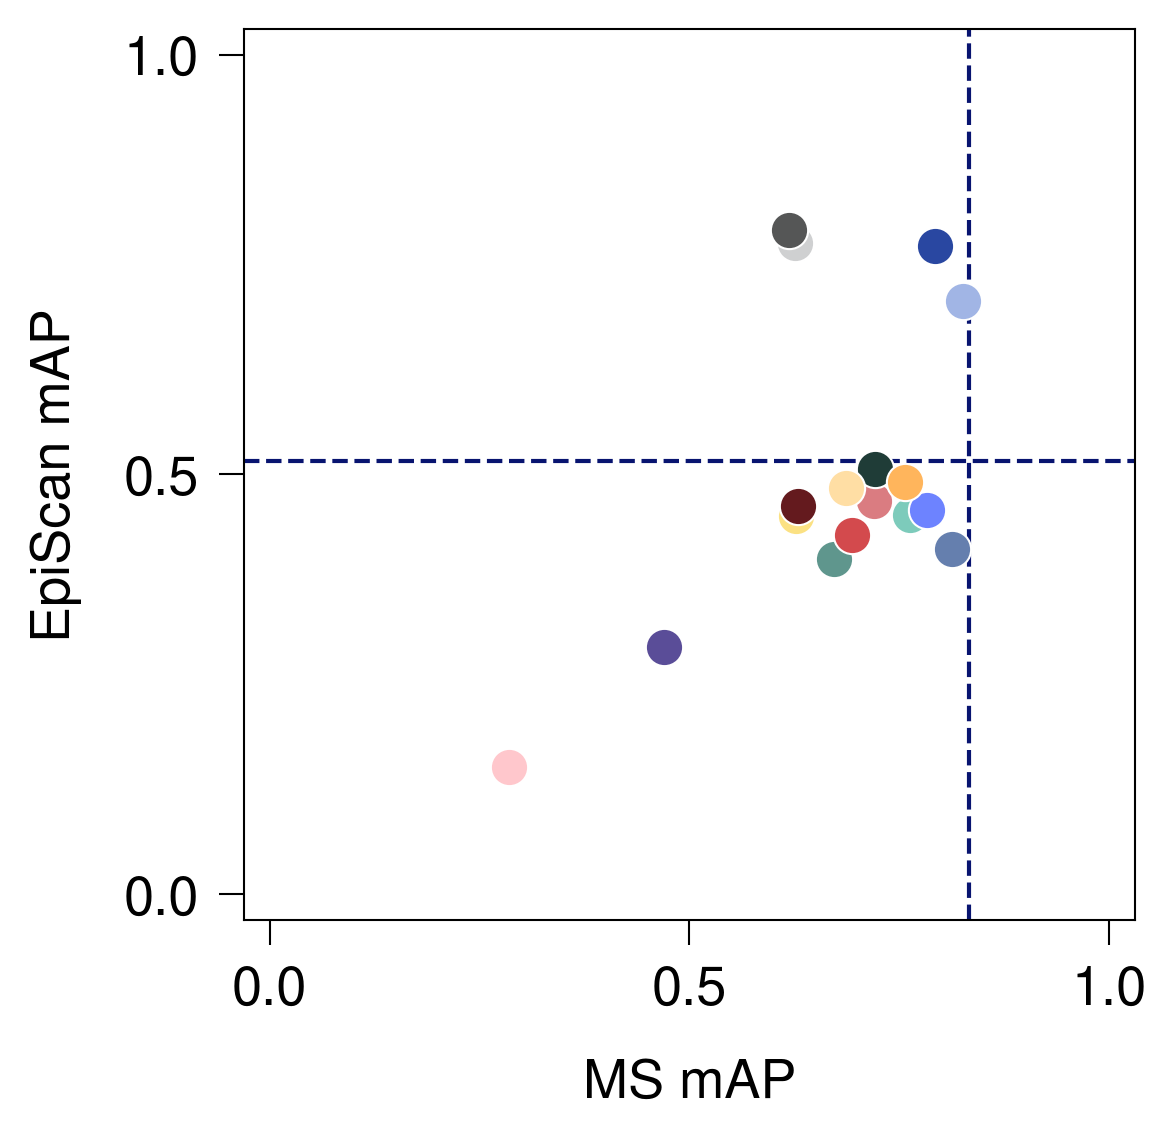

In [ ]:
# r9/rt pos versus r9 neg (easy background)
_=plot_single_metric_comparison_precomputed_y_v2(
    ms_allele_ap_matrix_for_episcan_r9rt_map_avg,
    r9rt_pos_r9_neg_mixed_map_df_avg,
    x_precomputed=True,
    x_col="mAP",
    x_model_col=None,
    # save_path=f"{lr_step_var_figures_dir}/fig4_e_epi_cl_r9rt_pos_r9_neg_mixed_map_vs_ms_map_scatterplot_updated",
    **plotting_params,
)

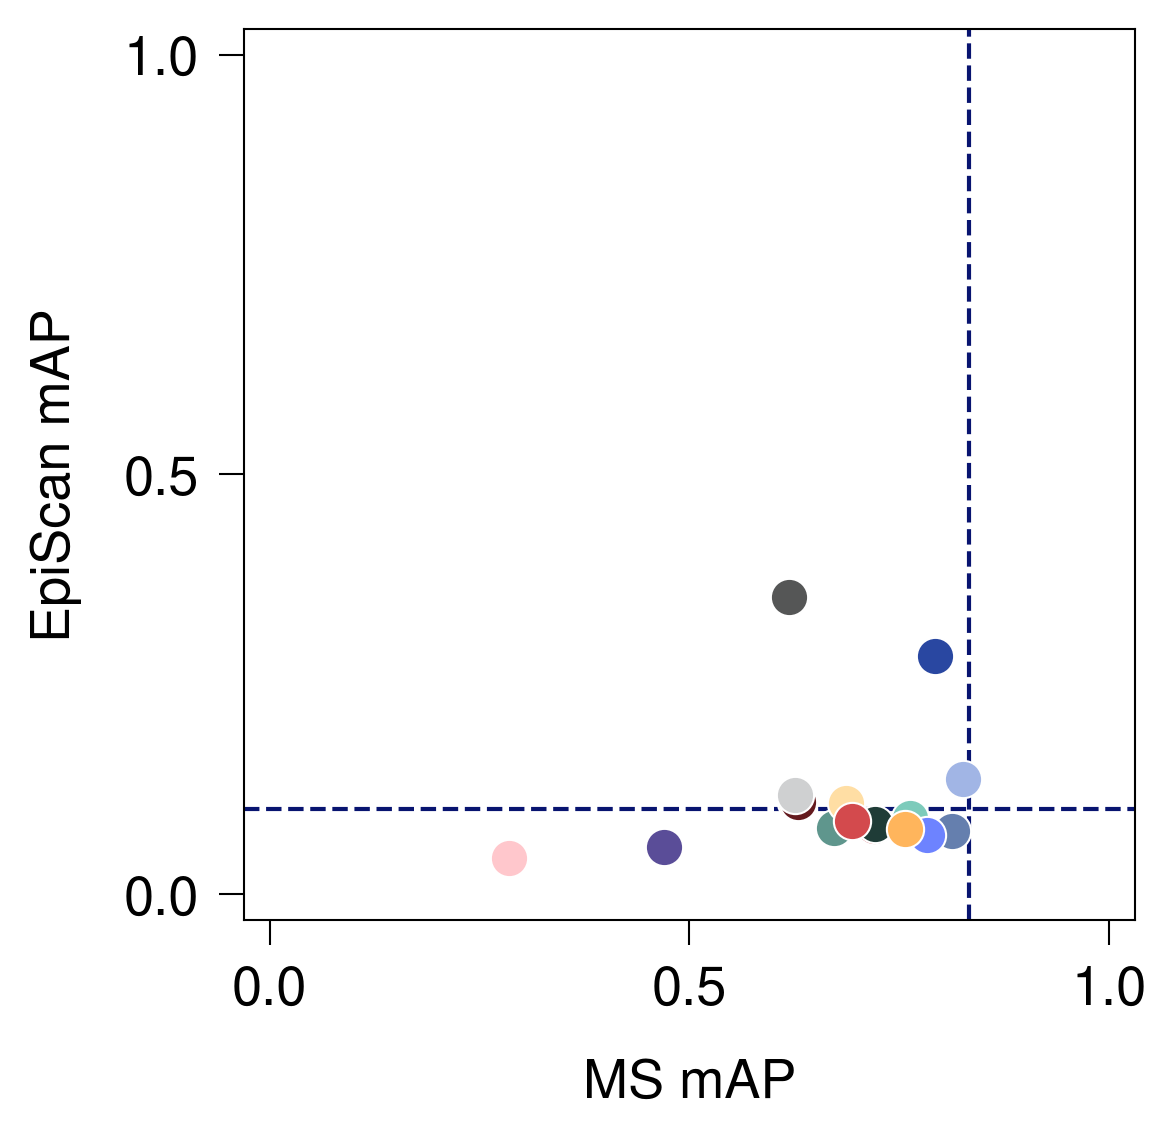

In [ ]:
# r9/rt pos versus r9/rt neg (hard background)
_=plot_single_metric_comparison_precomputed_y_v2(
    ms_allele_ap_matrix_for_episcan_r9rt_map_avg,
    r9rt_pos_r9rt_neg_mixed_map_df_avg,
    x_precomputed=True,
    x_col="mAP",
    x_model_col=None,
    # save_path=f"{lr_step_var_figures_dir}/fig4_e_epi_cl_r9rt_pos_r9rt_neg_mixed_map_vs_ms_map_scatterplot_updated",
    **plotting_params,
)

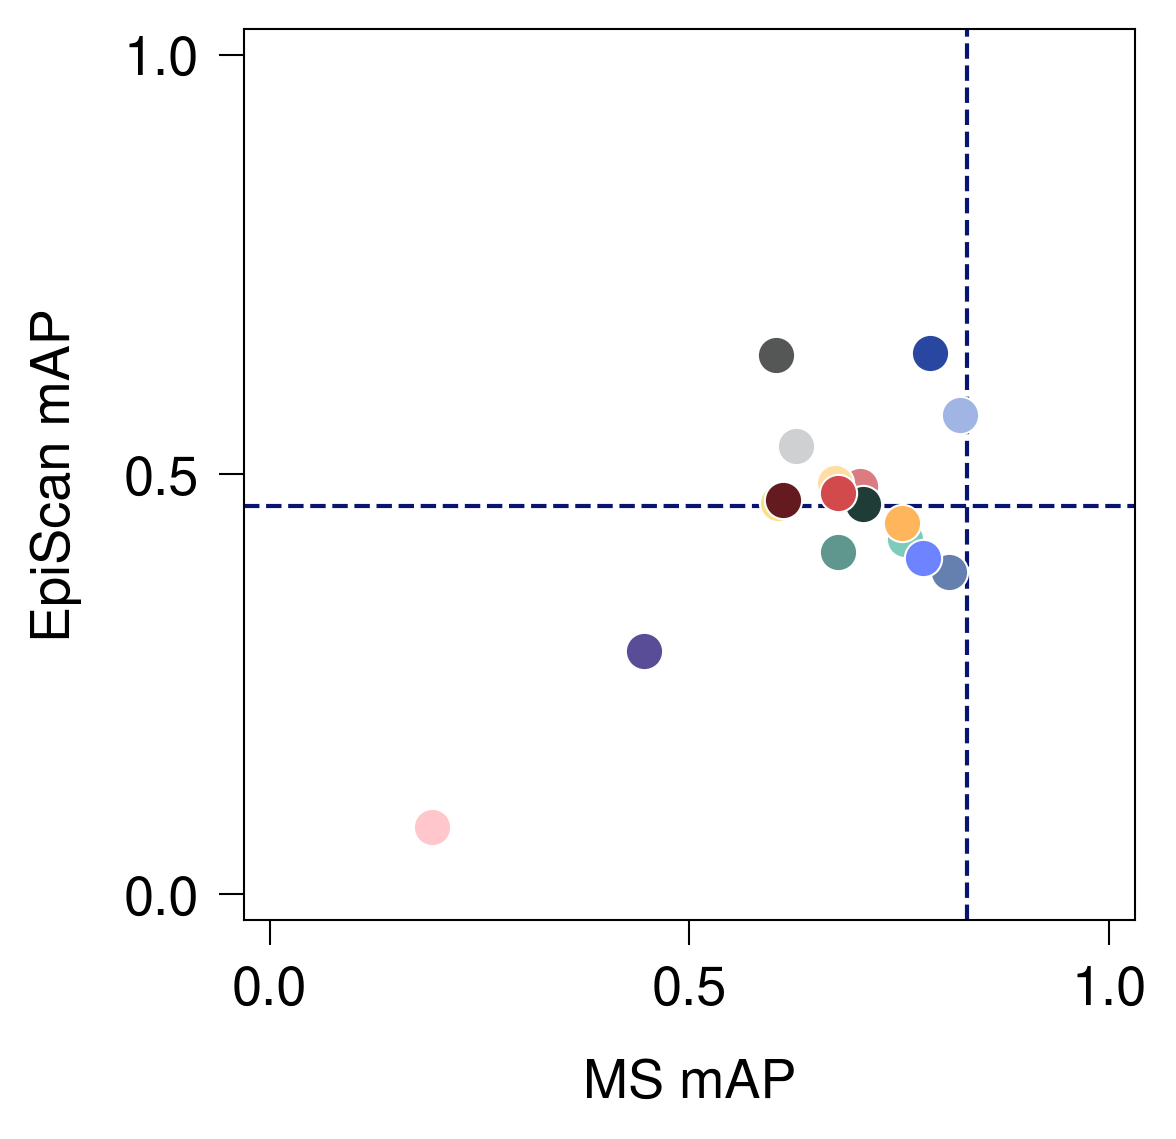

In [ ]:
# episcan sars-cov-2 set
_=plot_single_metric_comparison_precomputed_y_v2(
    ms_allele_ap_matrix_for_episcan_cov_map_avg,
    sd3_mixed_map_df_avg,
    x_precomputed=True,
    x_col="mAP",
    x_model_col=None,
    # save_path=f"{lr_step_var_figures_dir}/fig4_e_epi_cl_sd3_cov_matched_allele_mixed_map_vs_ms_map_scatterplot_updated",
    **plotting_params,
)

In [ ]:
# save for plotting in main figs file
episcan_final_results={
    "ms_allele_ap_matrix_for_episcan_r9rt_map_avg": ms_allele_ap_matrix_for_episcan_r9rt_map_avg,
    "r9rt_pos_r9_neg_mixed_map_df_avg": r9rt_pos_r9_neg_mixed_map_df_avg,
    "r9rt_pos_r9rt_neg_mixed_map_df_avg": r9rt_pos_r9rt_neg_mixed_map_df_avg,
    "ms_allele_ap_matrix_for_episcan_cov_map_avg": ms_allele_ap_matrix_for_episcan_cov_map_avg,
    "sd3_mixed_map_df_avg": sd3_mixed_map_df_avg,
}

# save_dict_pickle(episcan_final_results, f"{DATA_DIR}/Revisions_Data/assay_specific_learning_rate_and_step_variations_episcan_final_results.pkl")

#### BA/MS test (version to use in main figures)

 - Plot 3 boxes not 4.

In [ ]:
"""
Plotting parameters for boxplots.
"""
score_cols=["mhcprime", "ba_con_ft_steps_200_lr_2eN4", "ba_con_pepcl_r_dr_steps_300_lr_2eN4"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["ba_con_ft_steps_200_lr_2eN4"],
    'PepCL': ["ba_con_pepcl_r_dr_steps_300_lr_2eN4"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL': '#9bb0ed',
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,
    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    'figsize': (1.20, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,

    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)


{'MHCPrime': ['mhcprime'], 'FT': ['ba_con_ft_steps_200_lr_2eN4'], 'PepCL': ['ba_con_pepcl_r_dr_steps_300_lr_2eN4']}


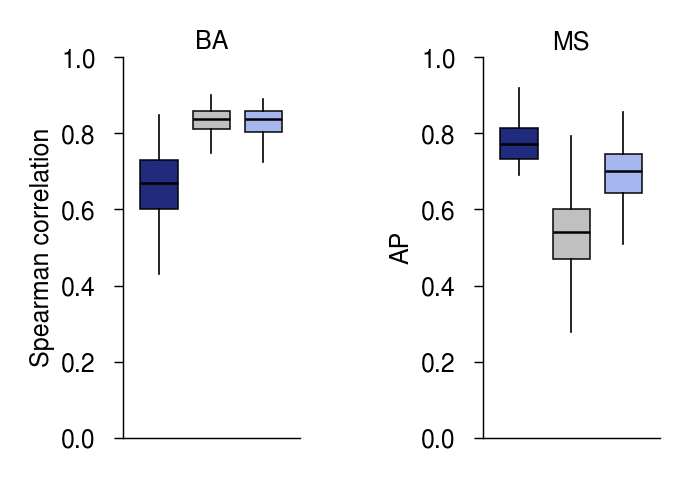

In [ ]:
# plot all together
plot_dict = {
    'assay': {
        'title': 'BA',
        'df': ba_con_ap_dfs_avg["assay_test"],
        'plot_params': {
            'ylabel': 'Spearman correlation',
        },
    },
    'ms': {
        'title': 'MS',
        'df': ba_con_ap_dfs_avg["ms_test_matched"],
        'plot_params': {
            'ylabel': 'AP',
        },
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    # save_path=f"{lr_step_var_figures_dir}/fig4_f_ba_con_ms_test_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)

In [ ]:
"""
NOTE: plot legend separately for all plots.
"""

### Training and validation loss tracking for final runs

#### YD experiments

In [ ]:
%%time
# get yd losses for training and val
yd_log_dirs=[f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_5_Seeds/logs"] + [f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_CV_Datasplit_{ds}/logs" for ds in datasplits]

yd_configs={
    "FT":{
        "prefix":"holec_ft_steps_300_lr_2eN4",
        "method":"ft",
        "dr_lambda":0.0,
    },
    "PepCL":{
        "base_title":"PepCL",
        "prefix":"holec_pepcl_r_dr_steps_200_lr_2eN4",
        "method":"pepcl",
        "dr_lambda":1e-5,
    },
    "PepCL Default":{
        "base_title":"PepCL default",
        "prefix":"holec_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "dr_lambda":1e-5,
    },
}

yd_loss_dfs = build_loss_trajectory_tables(
    log_dirs=yd_log_dirs,
    configs=yd_configs,
    seed_val_dfs={
        "assay": holec_dfs["assay_val"],
        "ms": holec_dfs["ms_val_matched"],
    },
    cv_val_dfs={
        1:{"assay": holec_dfs_ds["assay_val_1"], "ms": holec_dfs_ds["ms_val_matched_1"]},
        2:{"assay": holec_dfs_ds["assay_val_2"], "ms": holec_dfs_ds["ms_val_matched_2"]},
        3:{"assay": holec_dfs_ds["assay_val_3"], "ms": holec_dfs_ds["ms_val_matched_3"]},
        4:{"assay": holec_dfs_ds["assay_val_4"], "ms": holec_dfs_ds["ms_val_matched_4"]},
    },
    assay_loss_type="logsmoothap",
    continuous_target_col=None,
    assay_alpha=10.0,
    ms_alpha=10.0,
    device="cuda",
)


Searching training logs for: FT
  replicate 0: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_5_Seeds/logs/holec_ft_steps_300_lr_2eN4_seed_0.pkl
  replicate 1: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_5_Seeds/logs/holec_ft_steps_300_lr_2eN4_seed_1.pkl
  replicate 2: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_5_Seeds/logs/holec_ft_steps_300_lr_2eN4_seed_2.pkl
  replicate 3: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_5_Seeds/logs/holec_ft_steps_300_lr_2eN4_seed_3.pkl
  replicate 4: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_5_Seeds/logs/holec_ft_steps_300_lr_2eN4_seed_4.pkl
  replicate 5: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/YD_Validation_Selected_Final_CV_Datasplit_1/logs/holec_ft_steps

Validation losses: PepCL Default: 100%|██████████| 9/9 [00:00<00:00, 38.81it/s]


Training: 9 replicates, 27,900 rows
Validation: 9 replicates, 927 rows
Validation sampling summary:
        n_sampled               n_pos             n_neg            
              min  median   max   min median  max   min median  max
dataset                                                            
assay        1446  1446.0  1446   723  723.0  723   723  723.0  723
ms           1600  1600.0  1600   800  800.0  800   800  800.0  800
CPU times: user 4.66 s, sys: 160 ms, total: 4.82 s
Wall time: 4.8 s


In [ ]:
# set loss and performance styles
loss_styles={
    "FT loss":{
        # "color":"#456be8",
        # "val_color":"#456be8",
        "color":"#8f8f8f",
        "val_color":"#8f8f8f",

        "train_linestyle":"-",
        "val_linestyle":"--",

        "linewidth":1.0,
        "val_linewidth":1.0,

        "alpha":1.0,
        "val_alpha":1.0,

        "val_marker":None,
        "val_markersize":3,

        # legend
        "label":"FT loss (LogSmoothAP)",
        # "legend_color":"#456be8",
        "legend_color":"#8f8f8f",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
    },

    "MS replay loss":{
        # "color":"#ffb55c",
        # "val_color":"#ffb55c",
        "color":"#DA7C81",
        "val_color":"#DA7C81",

        "train_linestyle":"-",
        "val_linestyle":"--",

        "linewidth":1.0,
        "val_linewidth":1.0,

        "alpha":1.0,
        "val_alpha":1.0,

        "val_marker":None,
        "val_markersize":3,

        # legend
        "label":"MS replay loss (LogSmoothAP)",
        # "legend_color":"#ffb55c",
        "legend_color":"#DA7C81",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
    },

    "Weighted DR loss":{
        # "color":"#D34A4D",
        # "val_color":"#D34A4D",
        "color":"#6D83FF",
        "val_color":"#6D83FF",

        "train_linestyle":"-",
        "val_linestyle":"--",

        "linewidth":1.0,
        "val_linewidth":1.0,

        "alpha":1.0,
        "val_alpha":1.0,

        "val_marker":None,
        "val_markersize":3,

        # legend
        "label":"λDR loss (MSE)",
        # "legend_color":"#D34A4D",
        "legend_color":"#6D83FF",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
    },

    "Total loss":{
        # "color":"#9b72cf",
        # "val_color":"#9b72cf",
        "color":"#ffb55c",
        "val_color":"#ffb55c",

        "train_linestyle":"-",
        "val_linestyle":"--",

        "linewidth":1.0,
        "val_linewidth":1.0,

        "alpha":1.0,
        "val_alpha":1.0,

        "val_marker":None,
        "val_markersize":3,

        # legend
        "label":"Total loss",
        # "legend_color":"#9b72cf",
        "legend_color":"#ffb55c",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
    },
}

performance_styles={
    "Assay val":{
        # "color":"#456be8",
        "color":"#4d4d4d",

        "linestyle":"-",
        "linewidth":1.0,

        "alpha":1.0,

        "marker":None,
        "markersize":3,

        # SD shading
        "sd_alpha":0.18,

        # legend
        "label":"Assay val. (mAP)",
        # "legend_color":"#456be8",
        "legend_color":"#4d4d4d",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
        "legend_marker":None,
    },

    "MS val":{
        "color":"#223e8f",

        "linestyle":"-",
        "linewidth":1.0,

        "alpha":1.0,

        "marker":None,
        "markersize":3,

        # SD shading
        "sd_alpha":0.18,

        # legend
        "label":"MS val. (mAP)",
        "legend_color":"#223e8f",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
        "legend_marker":None,
    },
}

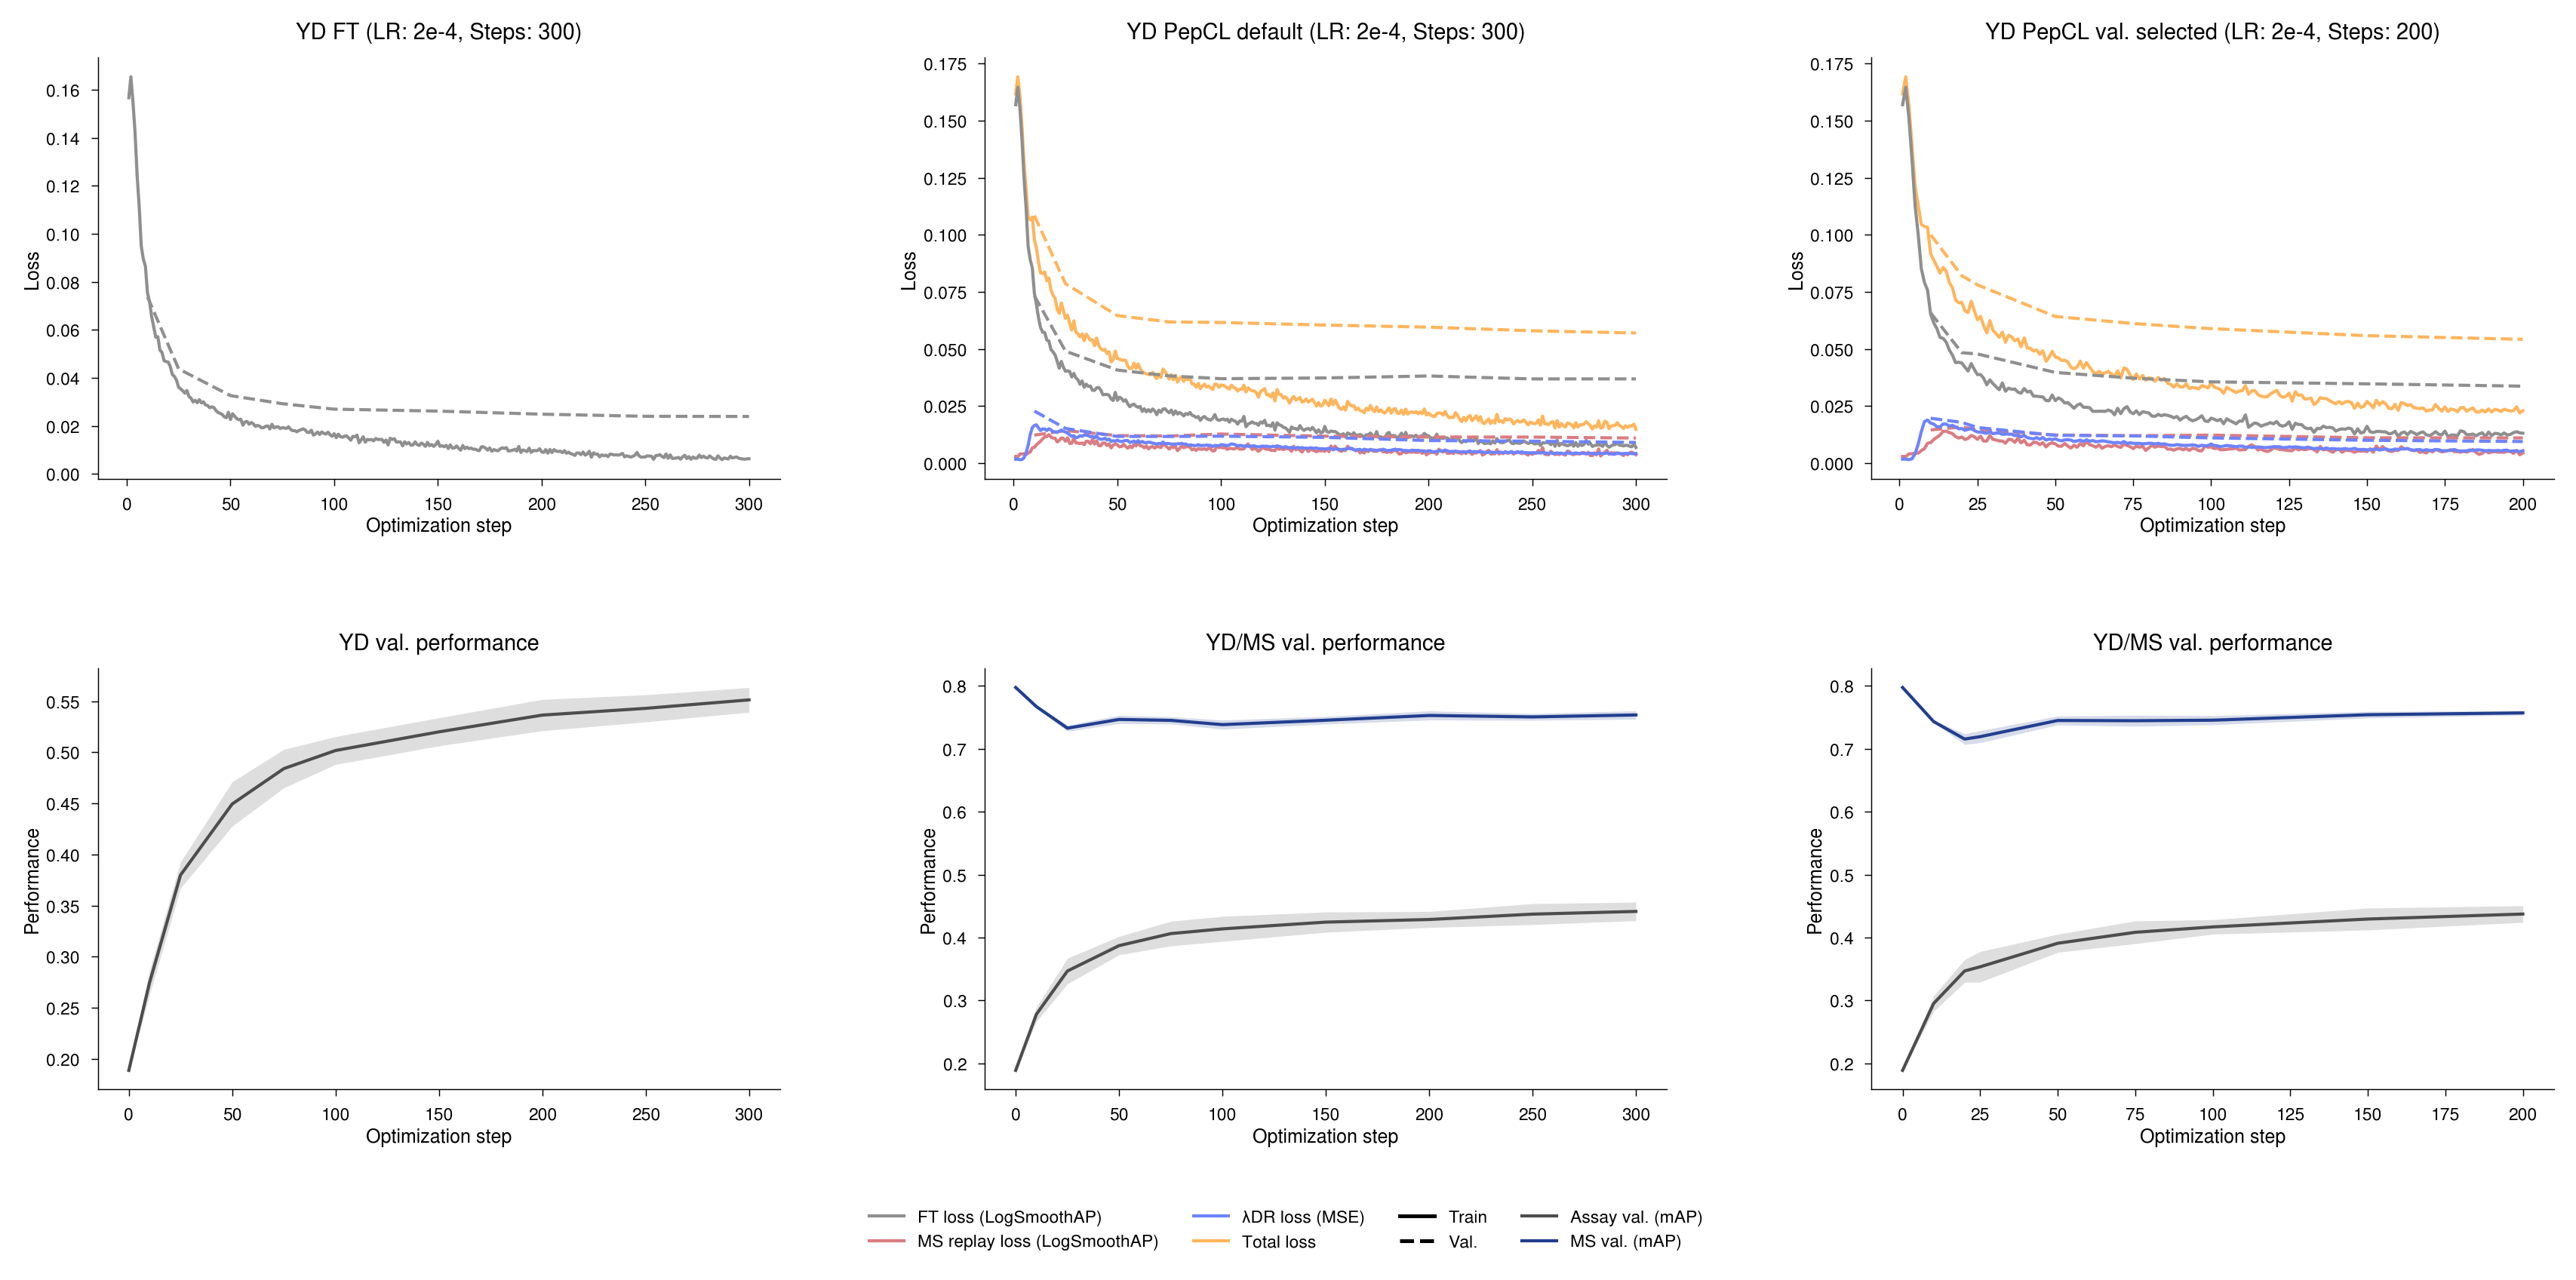

In [ ]:
yd_plot_configs={
    "FT":{
        "base_title":"FT",
        "loss_title":"YD FT",
        "performance_title":"YD val. performance",
        "prefix":"holec_ft_steps_300_lr_2eN4",
        "method":"ft",
        "lr":"2e-4",
        "steps":300,
    },
    "PepCL Default":{
        "base_title":"PepCL default",
        "loss_title":"YD PepCL default",
        "performance_title":"YD/MS val. performance",
        "prefix":"holec_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":300,
    },
    "PepCL":{
        "base_title":"PepCL",
        "loss_title":"YD PepCL val. selected",
        "performance_title":"YD/MS val. performance",
        "prefix":"holec_pepcl_r_dr_steps_200_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":200,
    },
}
fig,axes,perf_df=plot_loss_and_validation_performance_grid(
    loss_dfs=yd_loss_dfs,
    assay_perf_df=holec_ap_dfs["assay_val"],
    ms_perf_df=holec_ap_dfs["ms_val_matched"],
    configs=yd_plot_configs,
    loss_styles=loss_styles,
    performance_styles=performance_styles,
    title_decorate="loss",
    # figsize=(7, 6),
    figsize=(14, 6),
    dpi=300,
    title_prefix=None,
    include_mhcprime_step0=True,
    landscape=True,
    # save_path=f"{lr_step_var_figures_dir}/yd_train_val_loss_performance_curves",
)

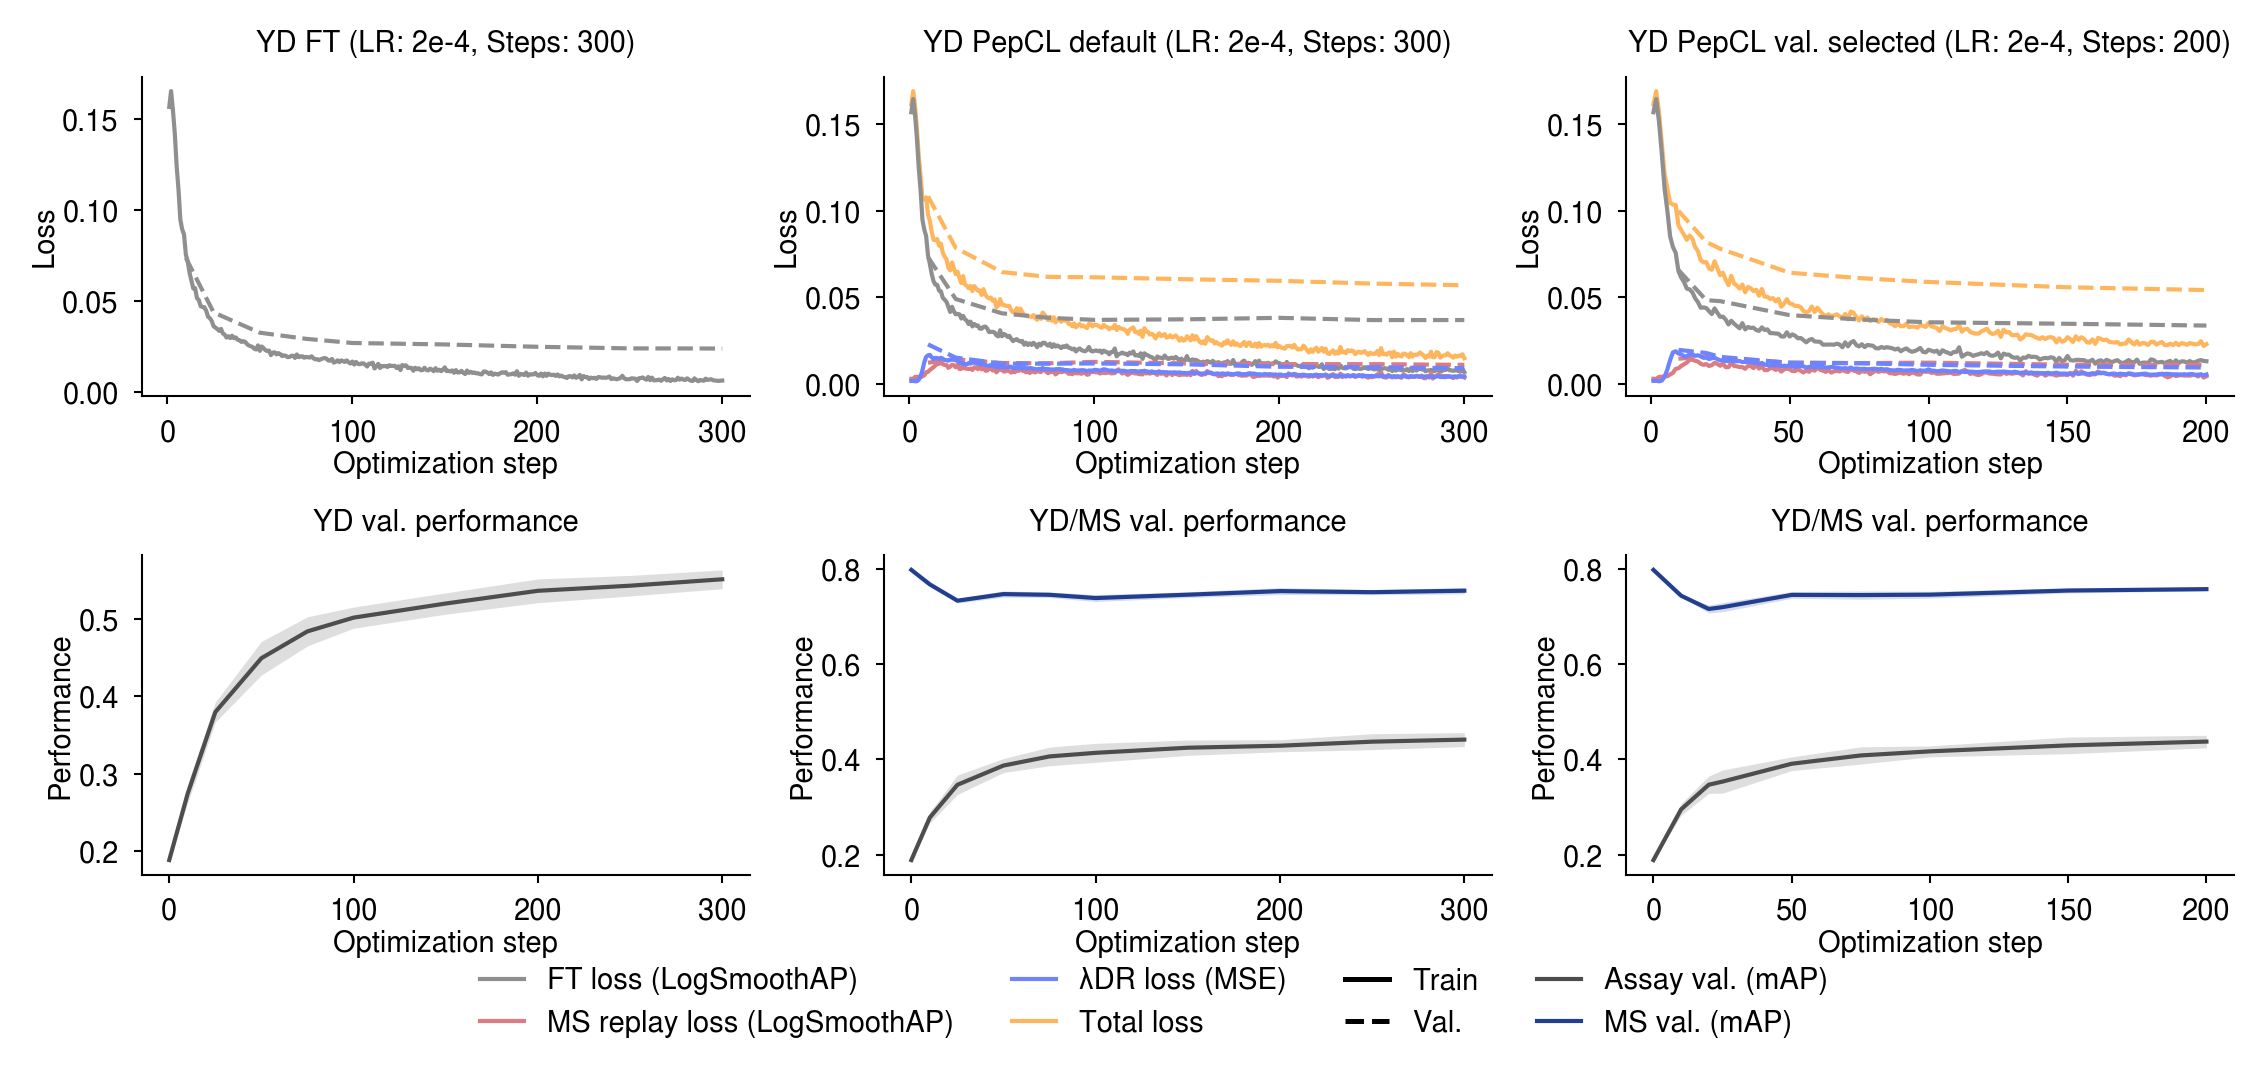

In [ ]:
# better sizing
fig,axes,perf_df=plot_loss_and_validation_performance_grid(
    loss_dfs=yd_loss_dfs,
    assay_perf_df=holec_ap_dfs["assay_val"],
    ms_perf_df=holec_ap_dfs["ms_val_matched"],
    configs=yd_plot_configs,
    loss_styles=loss_styles,
    performance_styles=performance_styles,

    title_decorate="loss",
    title_prefix=None,
    include_mhcprime_step0=True,
    landscape=True,

    # Design at approximately final Illustrator size
    figsize=(9, 3.5),
    dpi=300,

    # Keep all text at final 7 pt size
    title_fontsize=7,
    label_fontsize=7,
    tick_fontsize=7,
    legend_fontsize=7,

    # Tighten layout so axes occupy more of fixed canvas
    panel_wspace=0.22,
    panel_hspace=0.5,

    # Fine publication-scale strokes
    axis_linewidth=0.5,
    tick_width=0.5,
    tick_length=2.0,

    xlabel_pad=1.0,
    ylabel_pad=1.0,

    # Existing legend controls only
    legend_ncol=4,
    legend_loc="lower center",
    legend_bbox=(0.5,-0.06),
    legend_frame=False,
    legend_handlelength=1.5,

    # save_path=f"{lr_step_var_figures_dir}/yd_train_val_loss_performance_curves",
)

#### EpiScan experiments

##### R9

In [ ]:
# need to get r9/rt+ v. r9- assay val for raw df
assay_val=episcan_r9_dfs["assay_val"]
assay_val_r9=assay_val.query("dataset_source == 'r9'")
assay_val_rt=assay_val.query("dataset_source == 'rt'")
assay_val_r9rt_pos_r9_neg=pd.concat([assay_val_r9, assay_val_rt.query("label == 1")])

episcan_r9_dfs["assay_val_r9rt_pos_r9_neg"]=assay_val_r9rt_pos_r9_neg

# repeat for datasplits
datasplits=[1,2,3,4]
for ds in datasplits:
    assay_val=episcan_r9_dfs_ds[f"assay_val_{ds}"]
    assay_val_r9=assay_val.query("dataset_source == 'r9'")
    assay_val_rt=assay_val.query("dataset_source == 'rt'")
    assay_val_r9rt_pos_r9_neg_ds=pd.concat([assay_val_r9, assay_val_rt.query("label == 1")])
    episcan_r9_dfs_ds[f"assay_val_r9rt_pos_r9_neg_{ds}"]=assay_val_r9rt_pos_r9_neg_ds

In [ ]:
%%time
# episcan r9
episcan_r9_log_dirs_1=[f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds/logs"] + [
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_CV_Datasplit_{ds}/logs" for ds in datasplits
]

episcan_r9_log_dirs_2=[f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds_Updated/logs"] + [f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_CV_Datasplit_Updated_{ds}/logs" for ds in datasplits]

episcan_r9_log_dirs=[episcan_r9_log_dirs_1, episcan_r9_log_dirs_2]

episcan_r9_configs={
    "FT":{
        "prefix":"episcan_r9_ft_steps_300_lr_2eN4",
        "method":"ft",
        "dr_lambda":0.0,
    },
    "PepCL":{
        "base_title":"PepCL",
        "prefix":"episcan_r9_pepcl_r_dr_steps_800_lr_2eN4",
        "method":"pepcl",
        "dr_lambda":1e-5,
    },
    "PepCL Default":{
        "base_title":"PepCL default",
        "prefix":"episcan_r9_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "dr_lambda":1e-5,
    },
}

episcan_r9_loss_dfs=build_loss_trajectory_tables(
    log_dirs=episcan_r9_log_dirs,
    configs=episcan_r9_configs,
    seed_val_dfs={
        "assay":episcan_r9_dfs["assay_val_r9rt_pos_r9_neg"],
        "ms":episcan_r9_dfs["ms_val_matched"],
    },
    cv_val_dfs={
        ds:{
            "assay":episcan_r9_dfs_ds[f"assay_val_r9rt_pos_r9_neg_{ds}"],
            "ms":episcan_r9_dfs_ds[f"ms_val_matched_{ds}"],
        } for ds in datasplits
    },
    assay_loss_type="logsmoothap",
    continuous_target_col=None,
    assay_alpha=10.0,
    ms_alpha=10.0,
    device="cuda",
)


Searching training logs for: FT
  replicate 0: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9_ft_steps_300_lr_2eN4_seed_0.pkl
  replicate 1: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9_ft_steps_300_lr_2eN4_seed_1.pkl
  replicate 2: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9_ft_steps_300_lr_2eN4_seed_2.pkl
  replicate 3: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9_ft_steps_300_lr_2eN4_seed_3.pkl
  replicate 4: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9_ft_steps_300_lr_2eN4_seed_4.pkl
  replicate 5: /home/pchati/PepCL_Manuscri

Validation losses: PepCL Default: 100%|██████████| 9/9 [00:00<00:00, 36.01it/s]



Training: 9 replicates, 54,900 rows
Validation: 9 replicates, 1,377 rows
Validation sampling summary:
        n_sampled             n_pos             n_neg            
              min median  max   min median  max   min median  max
dataset                                                          
assay         676  676.0  676   338  338.0  338   338  338.0  338
ms            400  400.0  400   200  200.0  200   200  200.0  200
CPU times: user 3.69 s, sys: 24.1 ms, total: 3.71 s
Wall time: 3.7 s


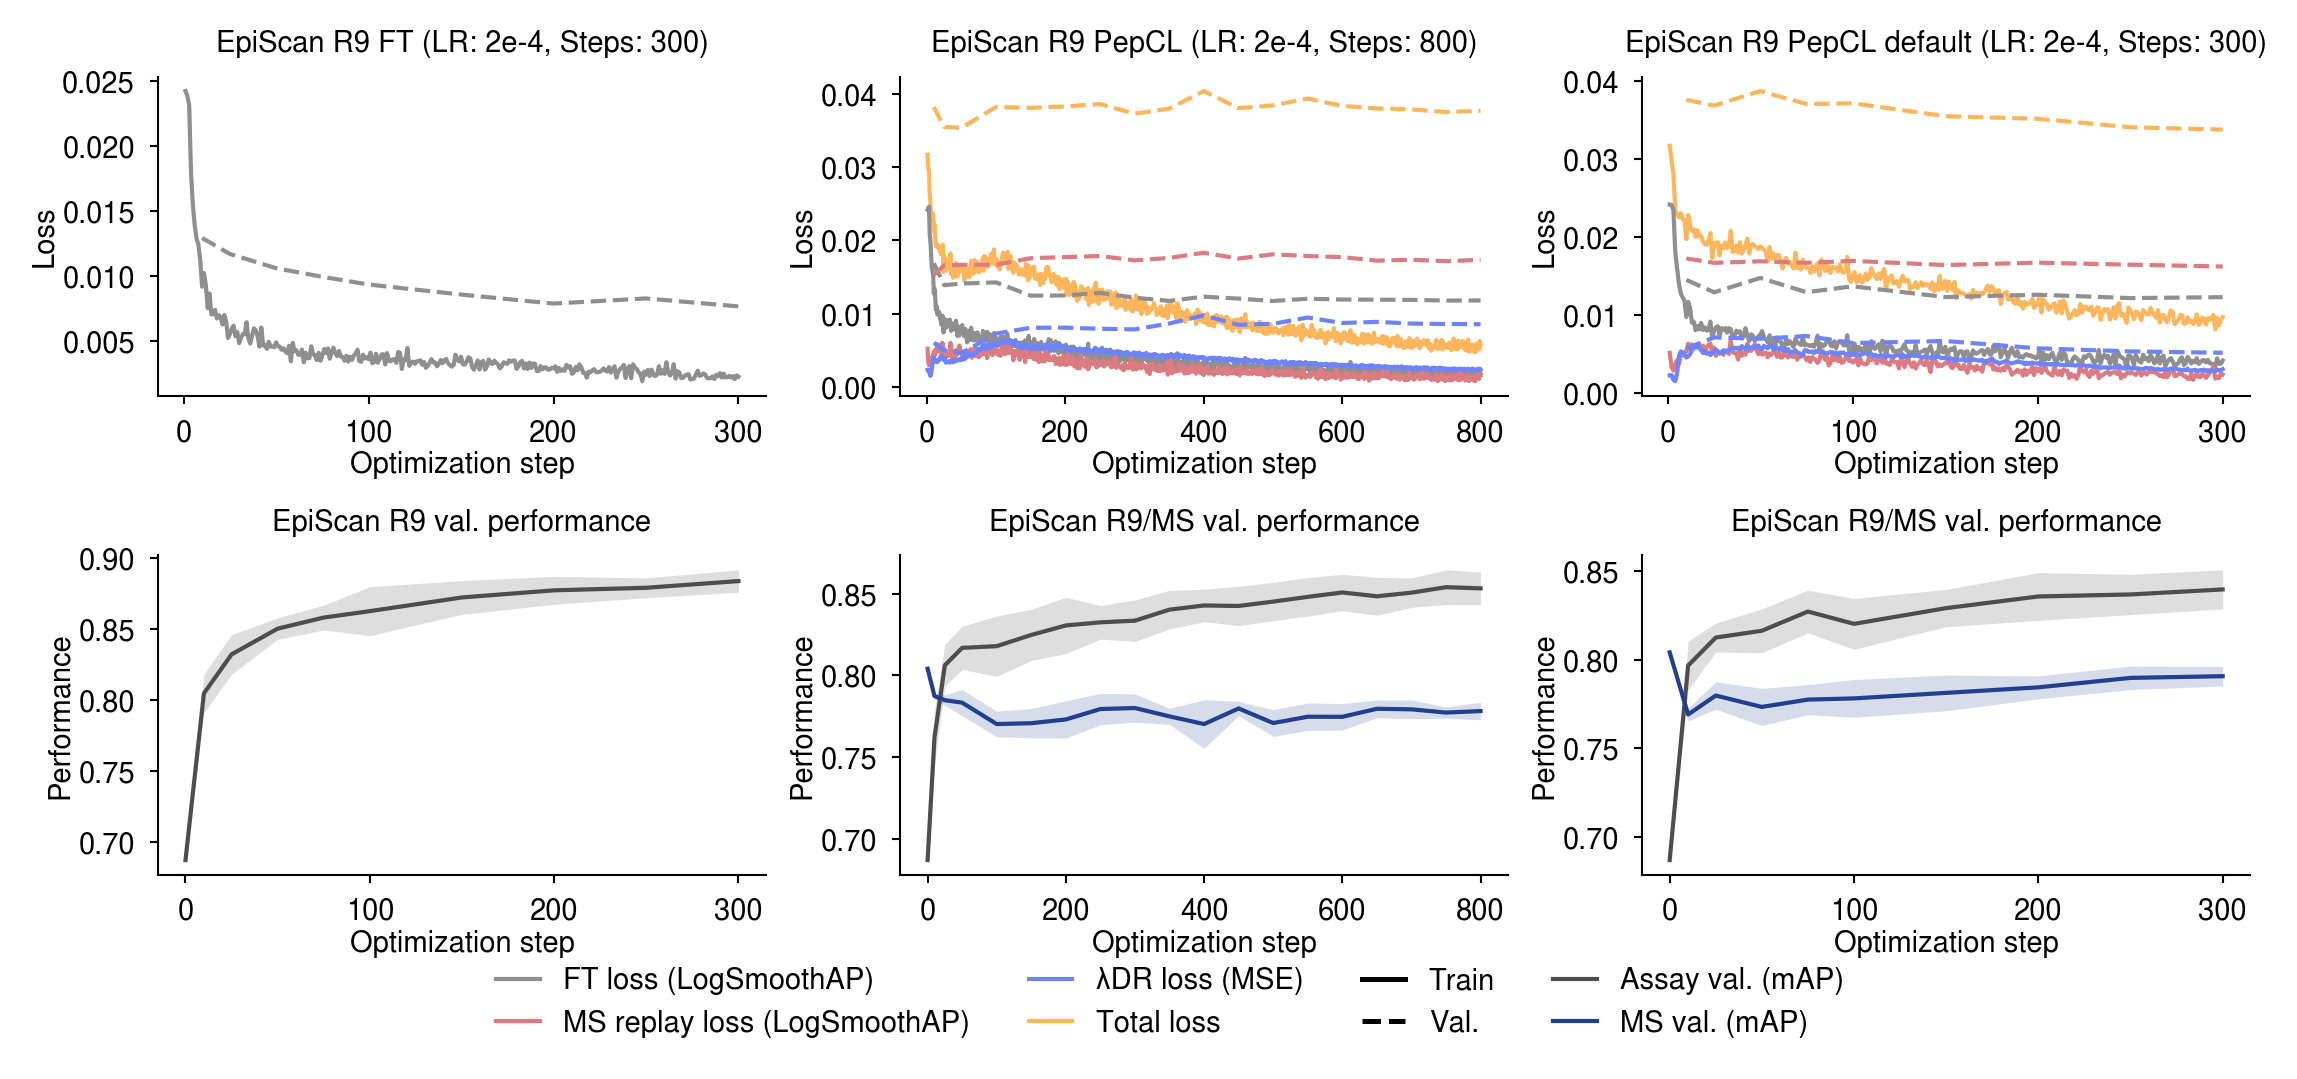

In [ ]:
# plot loss and val aps
episcan_r9_plot_configs={
    "FT":{
        "base_title":"FT",
        "loss_title":"EpiScan R9 FT",
        "performance_title":"EpiScan R9 val. performance",
        "prefix":"episcan_r9_ft_steps_300_lr_2eN4",
        "method":"ft",
        "lr":"2e-4",
        "steps":300,
    },
    "PepCL":{
        "base_title":"PepCL",
        "loss_title":"EpiScan R9 PepCL",
        "performance_title":"EpiScan R9/MS val. performance",
        "prefix":"episcan_r9_pepcl_r_dr_steps_800_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":800,
    },
    "PepCL Default":{
        "base_title":"PepCL default",
        "loss_title":"EpiScan R9 PepCL default",
        "performance_title":"EpiScan R9/MS val. performance",
        "prefix":"episcan_r9_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":300,
    },
}

# better sizing
fig,axes,perf_df=plot_loss_and_validation_performance_grid(
    loss_dfs=episcan_r9_loss_dfs,
    assay_perf_df=episcan_r9_ap_dfs["assay_val_mixture"],
    ms_perf_df=episcan_r9_ap_dfs["ms_val_matched"],
    configs=episcan_r9_plot_configs,
    loss_styles=loss_styles,
    performance_styles=performance_styles,

    title_decorate="loss",
    title_prefix=None,
    include_mhcprime_step0=True,
    landscape=True,

    # Design at approximately final Illustrator size
    figsize=(9, 3.5),
    dpi=300,

    # Keep all text at final 7 pt size
    title_fontsize=7,
    label_fontsize=7,
    tick_fontsize=7,
    legend_fontsize=7,

    # Tighten layout so axes occupy more of fixed canvas
    panel_wspace=0.22,
    panel_hspace=0.5,

    # Fine publication-scale strokes
    axis_linewidth=0.5,
    tick_width=0.5,
    tick_length=2.0,

    xlabel_pad=1.0,
    ylabel_pad=1.0,

    # Existing legend controls only
    legend_ncol=4,
    legend_loc="lower center",
    legend_bbox=(0.5,-0.06),
    legend_frame=False,
    legend_handlelength=1.5,

    # save_path=f"{lr_step_var_figures_dir}/episcan_r9_train_val_loss_performance_curves",
)

##### R9/RT

In [ ]:
%%time
# episcan r9/rt
episcan_r9rt_log_dirs_1=[f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds/logs"] + [
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_CV_Datasplit_{ds}/logs" for ds in datasplits
]


episcan_r9rt_log_dirs_2=[f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds_Updated/logs"] + [f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_CV_Datasplit_Updated_{ds}/logs" for ds in datasplits]


episcan_r9rt_log_dirs=[episcan_r9rt_log_dirs_1, episcan_r9rt_log_dirs_2]

episcan_r9rt_configs={
    "FT":{
        "prefix":"episcan_r9rt_ft_steps_400_lr_2eN4",
        "method":"ft",
        "dr_lambda":0.0,
    },
    "PepCL":{
        "base_title":"PepCL",
        "prefix":"episcan_r9rt_pepcl_r_dr_steps_400_lr_2eN4",
        "method":"pepcl",
        "dr_lambda":1e-5,
    },
    "PepCL Default":{
        "base_title":"PepCL default",
        "prefix":"episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "dr_lambda":1e-5,
    },


}

episcan_r9rt_loss_dfs=build_loss_trajectory_tables(
    log_dirs=episcan_r9rt_log_dirs,
    configs=episcan_r9rt_configs,
    seed_val_dfs={
        "assay":episcan_r9rt_dfs["assay_val"],
        "ms":episcan_r9rt_dfs["ms_val_matched"],
    },
    cv_val_dfs={
        ds:{
            "assay":episcan_r9rt_dfs_ds[f"assay_val_{ds}"],
            "ms":episcan_r9rt_dfs_ds[f"ms_val_matched_{ds}"],
        } for ds in datasplits
    },
    assay_loss_type="logsmoothap",
    continuous_target_col=None,
    assay_alpha=10.0,
    ms_alpha=10.0,
    device="cuda",
)


Searching training logs for: FT
  replicate 0: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9rt_ft_steps_400_lr_2eN4_seed_0.pkl
  replicate 1: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9rt_ft_steps_400_lr_2eN4_seed_1.pkl
  replicate 2: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9rt_ft_steps_400_lr_2eN4_seed_2.pkl
  replicate 3: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9rt_ft_steps_400_lr_2eN4_seed_3.pkl
  replicate 4: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/EpiScan_R9_RT_Validation_Selected_Final_5_Seeds_Updated/logs/episcan_r9rt_ft_steps_400_lr_2eN4_seed_4.pkl
  replicate 5: /h

Validation losses: PepCL Default: 100%|██████████| 9/9 [00:00<00:00, 36.61it/s]


Training: 9 replicates, 38,700 rows
Validation: 9 replicates, 1,035 rows
Validation sampling summary:
        n_sampled             n_pos             n_neg            
              min median  max   min median  max   min median  max
dataset                                                          
assay         676  676.0  676   338  338.0  338   338  338.0  338
ms            400  400.0  400   200  200.0  200   200  200.0  200
CPU times: user 3.04 s, sys: 43.7 ms, total: 3.08 s
Wall time: 3.07 s


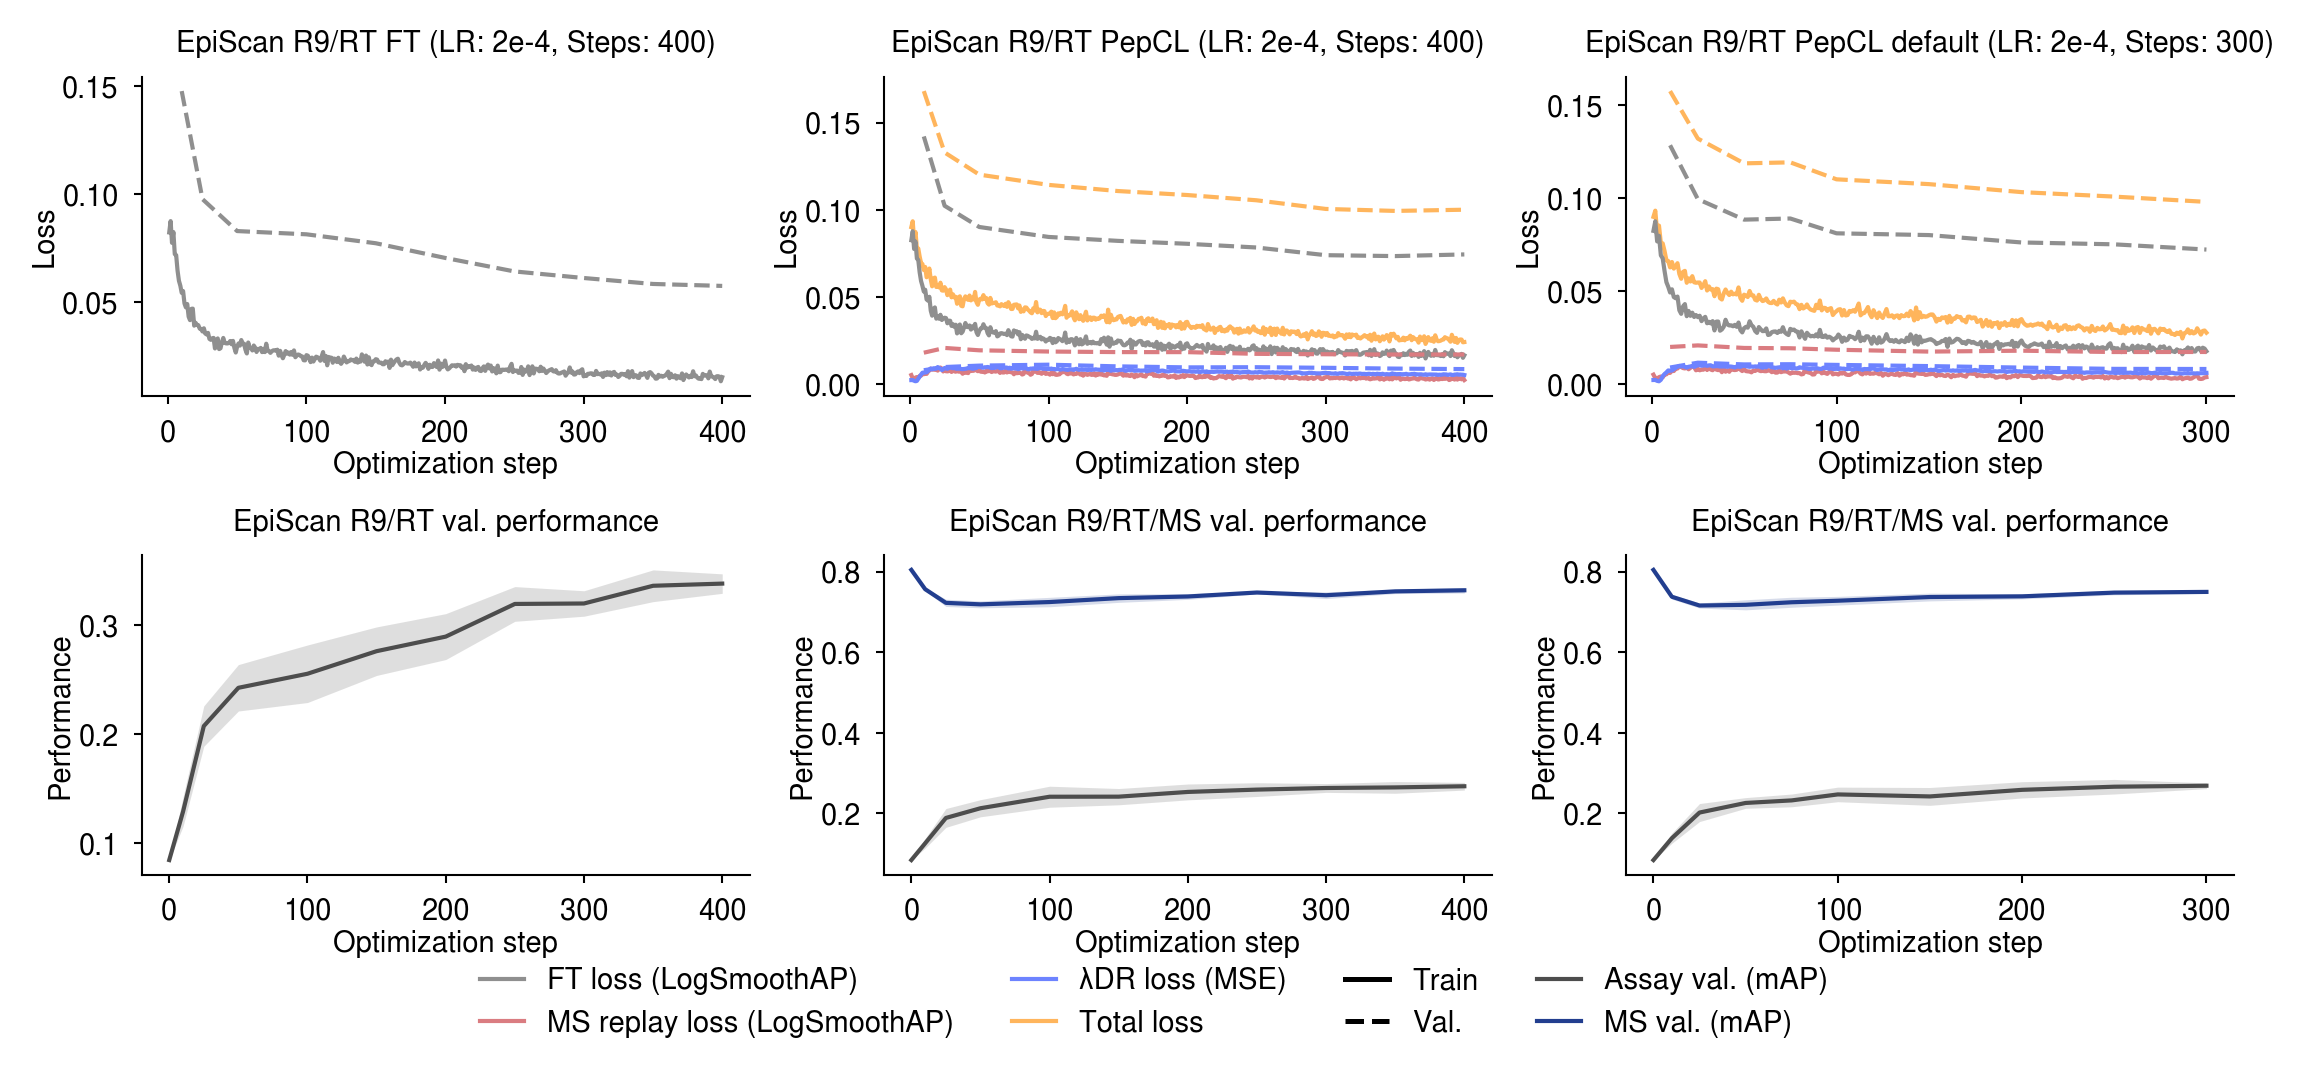

In [ ]:
# plot loss and val aps
episcan_r9rt_plot_configs={
    "FT":{
        "base_title":"FT",
        "loss_title":"EpiScan R9/RT FT",
        "performance_title":"EpiScan R9/RT val. performance",
        "prefix":"episcan_r9rt_ft_steps_400_lr_2eN4",
        "method":"ft",
        "lr":"2e-4",
        "steps":400,
    },
    "PepCL":{
        "base_title":"PepCL",
        "loss_title":"EpiScan R9/RT PepCL",
        "performance_title":"EpiScan R9/RT/MS val. performance",
        "prefix":"episcan_r9rt_pepcl_r_dr_steps_400_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":400,
    },
    "PepCL Default":{
        "base_title":"PepCL default",
        "loss_title":"EpiScan R9/RT PepCL default",
        "performance_title":"EpiScan R9/RT/MS val. performance",
        "prefix":"episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":300,
    },
}

# better sizing
fig,axes,perf_df=plot_loss_and_validation_performance_grid(
    loss_dfs=episcan_r9rt_loss_dfs,
    assay_perf_df=episcan_r9rt_ap_dfs["assay_val_mixture"],
    ms_perf_df=episcan_r9rt_ap_dfs["ms_val_matched"],
    configs=episcan_r9rt_plot_configs,
    loss_styles=loss_styles,
    performance_styles=performance_styles,

    title_decorate="loss",
    title_prefix=None,
    include_mhcprime_step0=True,
    landscape=True,

    # Design at approximately final Illustrator size
    figsize=(9, 3.5),
    dpi=300,

    # Keep all text at final 7 pt size
    title_fontsize=7,
    label_fontsize=7,
    tick_fontsize=7,
    legend_fontsize=7,

    # Tighten layout so axes occupy more of fixed canvas
    panel_wspace=0.22,
    panel_hspace=0.5,

    # Fine publication-scale strokes
    axis_linewidth=0.5,
    tick_width=0.5,
    tick_length=2.0,

    xlabel_pad=1.0,
    ylabel_pad=1.0,

    # Existing legend controls only
    legend_ncol=4,
    legend_loc="lower center",
    legend_bbox=(0.5,-0.06),
    legend_frame=False,
    legend_handlelength=1.5,

    # save_path=f"{lr_step_var_figures_dir}/episcan_r9rt_train_val_loss_performance_curves",
)

#### BA CON

In [ ]:
%%time
# ba con
ba_con_log_dirs=[f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_5_Seeds/logs"] + [
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_CV_Datasplit_{ds}/logs" for ds in datasplits
]

ba_con_configs={
    "FT":{
        "prefix":"ba_con_ft_steps_200_lr_2eN4",
        "method":"ft",
        "dr_lambda":0.0,
    },
    "PepCL":{
        "base_title":"PepCL",
        "prefix":"ba_con_pepcl_r_dr_steps_800_lr_2eN4",
        "method":"pepcl",
        "dr_lambda":1e-5,
    },
    "PepCL Default":{
        "base_title":"PepCL default",
        "prefix":"ba_con_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "dr_lambda":1e-5,
    },
}

ba_con_loss_dfs=build_loss_trajectory_tables(
    log_dirs=ba_con_log_dirs,
    configs=ba_con_configs,
    seed_val_dfs={
        "assay":ba_con_dfs["assay_val"],
        "ms":ba_con_dfs["ms_val_matched"],
    },
    cv_val_dfs={
        ds:{
            "assay":ba_con_dfs_ds[f"assay_val_{ds}"],
            "ms":ba_con_dfs_ds[f"ms_val_matched_{ds}"],
        } for ds in datasplits
    },
    assay_loss_type="spearman",
    continuous_target_col="ba_value",
    assay_alpha=0.01,
    ms_alpha=10.0,
    device="cuda",
)


Searching training logs for: FT
  replicate 0: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_5_Seeds/logs/ba_con_ft_steps_200_lr_2eN4_seed_0.pkl
  replicate 1: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_5_Seeds/logs/ba_con_ft_steps_200_lr_2eN4_seed_1.pkl
  replicate 2: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_5_Seeds/logs/ba_con_ft_steps_200_lr_2eN4_seed_2.pkl
  replicate 3: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_5_Seeds/logs/ba_con_ft_steps_200_lr_2eN4_seed_3.pkl
  replicate 4: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_5_Seeds/logs/ba_con_ft_steps_200_lr_2eN4_seed_4.pkl
  replicate 5: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/BA_CON_Validation_Selected_Final_CV_Da

Validation losses: PepCL Default: 100%|██████████| 9/9 [00:00<00:00, 24.42it/s]



Training: 9 replicates, 53,100 rows
Validation: 9 replicates, 1,359 rows
Validation sampling summary:
        n_sampled               n_pos               n_neg              
              min  median   max   min  median   max   min  median   max
dataset                                                                
assay        3052  3052.0  3052  1526  1526.0  1526  1526  1526.0  1526
ms           3072  3072.0  3072  1536  1536.0  1536  1536  1536.0  1536
CPU times: user 10.5 s, sys: 139 ms, total: 10.7 s
Wall time: 10.7 s


In [ ]:
# set loss and performance styles
loss_styles={
    "FT loss":{
        # "color":"#456be8",
        # "val_color":"#456be8",
        "color":"#8f8f8f",
        "val_color":"#8f8f8f",

        "train_linestyle":"-",
        "val_linestyle":"--",

        "linewidth":1.0,
        "val_linewidth":1.0,

        "alpha":1.0,
        "val_alpha":1.0,

        "val_marker":None,
        "val_markersize":3,

        # legend
        "label":"FT loss (Continuous)",
        # "legend_color":"#456be8",
        "legend_color":"#8f8f8f",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
    },

    "MS replay loss":{
        # "color":"#ffb55c",
        # "val_color":"#ffb55c",
        "color":"#DA7C81",
        "val_color":"#DA7C81",

        "train_linestyle":"-",
        "val_linestyle":"--",

        "linewidth":1.0,
        "val_linewidth":1.0,

        "alpha":1.0,
        "val_alpha":1.0,

        "val_marker":None,
        "val_markersize":3,

        # legend
        "label":"MS replay loss (LogSmoothAP)",
        # "legend_color":"#ffb55c",
        "legend_color":"#DA7C81",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
    },

    "Weighted DR loss":{
        # "color":"#D34A4D",
        # "val_color":"#D34A4D",
        "color":"#6D83FF",
        "val_color":"#6D83FF",

        "train_linestyle":"-",
        "val_linestyle":"--",

        "linewidth":1.0,
        "val_linewidth":1.0,

        "alpha":1.0,
        "val_alpha":1.0,

        "val_marker":None,
        "val_markersize":3,

        # legend
        "label":"λDR loss (MSE)",
        # "legend_color":"#D34A4D",
        "legend_color":"#6D83FF",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
    },

    "Total loss":{
        # "color":"#9b72cf",
        # "val_color":"#9b72cf",
        "color":"#ffb55c",
        "val_color":"#ffb55c",

        "train_linestyle":"-",
        "val_linestyle":"--",

        "linewidth":1.0,
        "val_linewidth":1.0,

        "alpha":1.0,
        "val_alpha":1.0,

        "val_marker":None,
        "val_markersize":3,

        # legend
        "label":"Total loss",
        # "legend_color":"#9b72cf",
        "legend_color":"#ffb55c",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
    },
}

performance_styles={
    "Assay val":{
        # "color":"#456be8",
        "color":"#4d4d4d",

        "linestyle":"-",
        "linewidth":1.0,

        "alpha":1.0,

        "marker":None,
        "markersize":3,

        # SD shading
        "sd_alpha":0.18,

        # legend
        "label":"Assay val. (Spearman)",
        # "legend_color":"#456be8",
        "legend_color":"#4d4d4d",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
        "legend_marker":None,
    },

    "MS val":{
        "color":"#223e8f",

        "linestyle":"-",
        "linewidth":1.0,

        "alpha":1.0,

        "marker":None,
        "markersize":3,

        # SD shading
        "sd_alpha":0.18,

        # legend
        "label":"MS val. (mAP)",
        "legend_color":"#223e8f",
        "legend_linestyle":"-",
        "legend_linewidth":1.2,
        "legend_marker":None,
    },
}

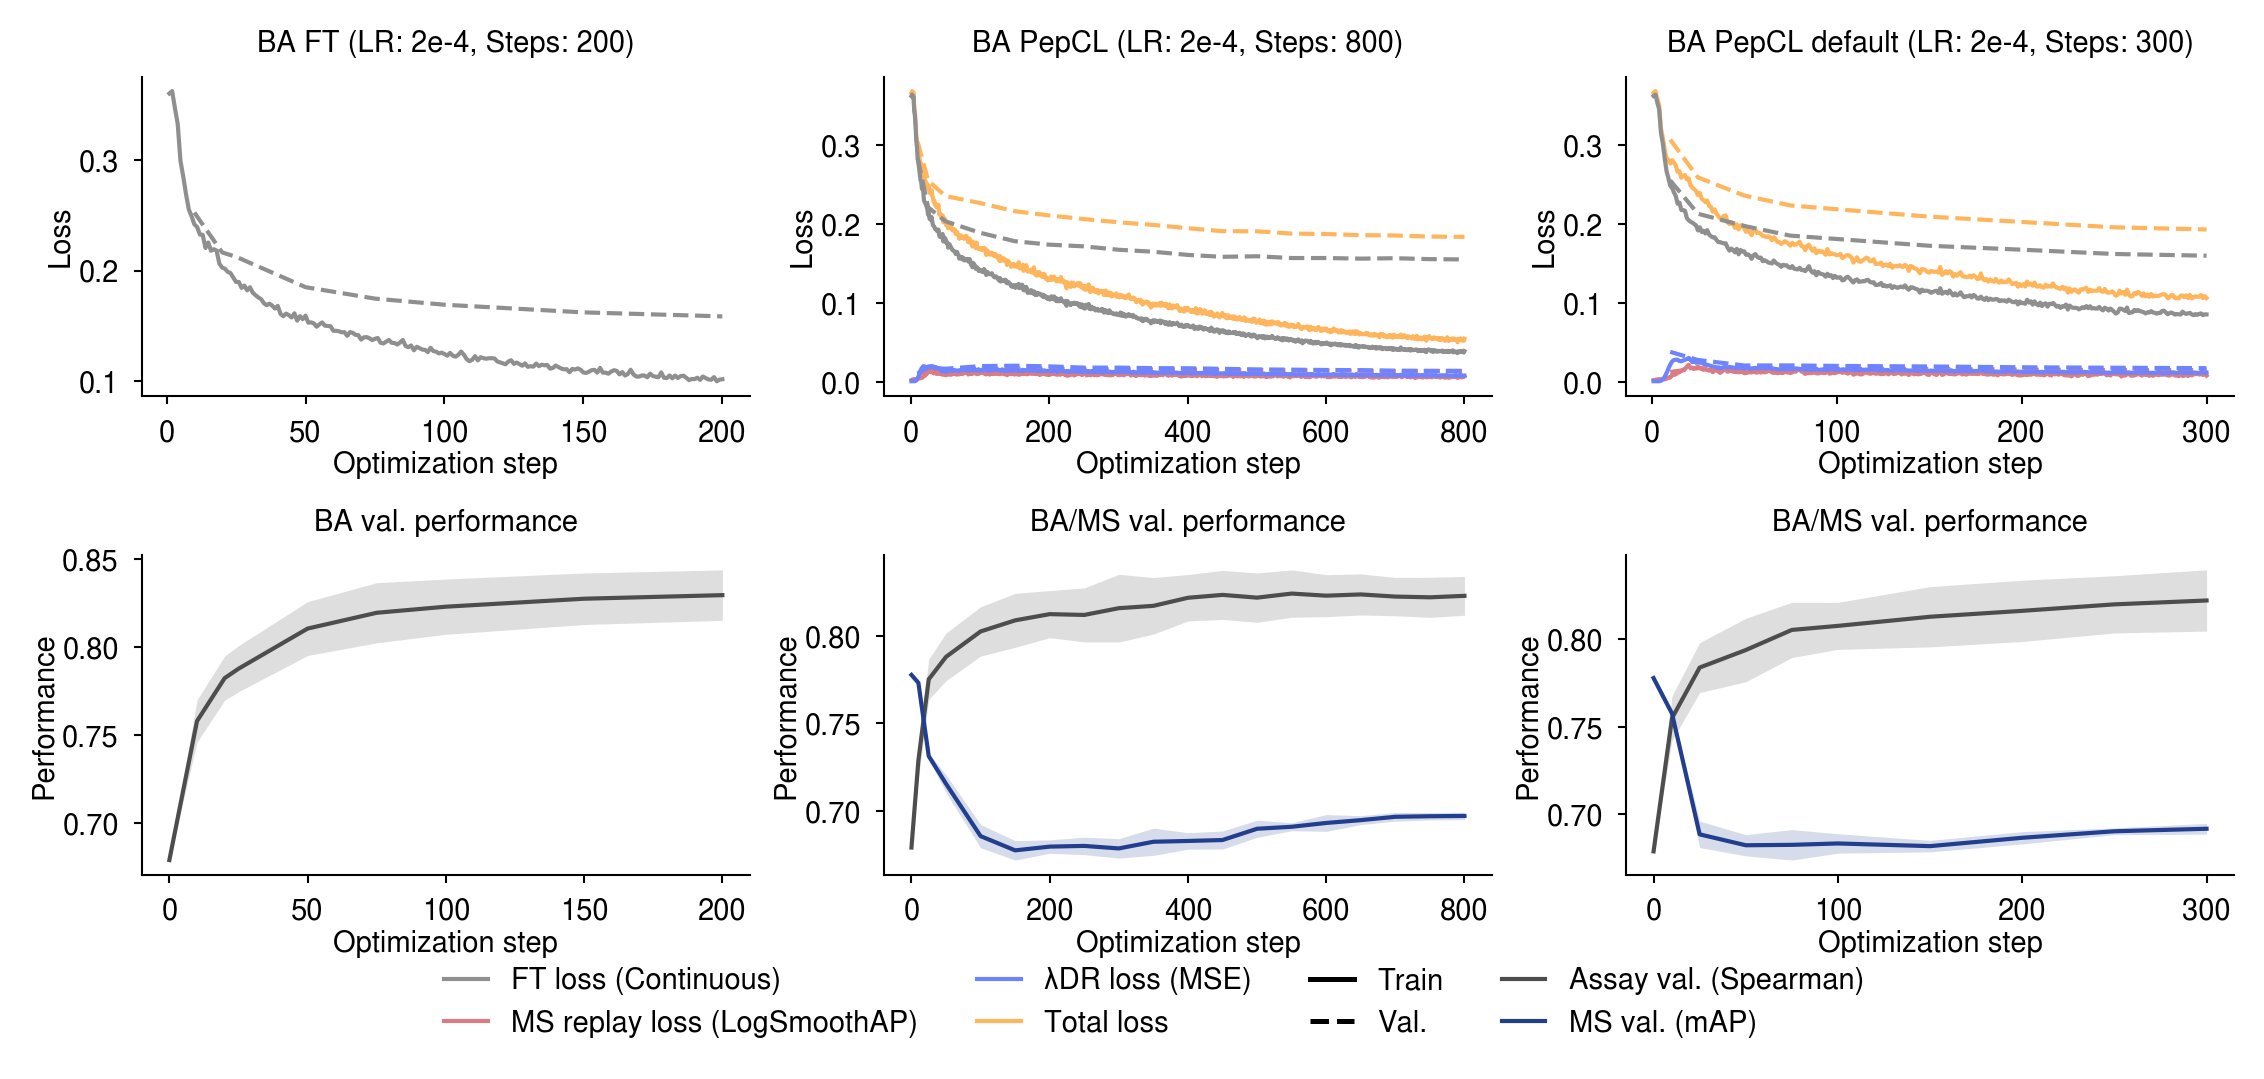

In [ ]:
# plot loss and val aps
ba_con_plot_configs={
    "FT":{
        "base_title":"FT",
        "loss_title":"BA FT",
        "performance_title":"BA val. performance",
        "prefix":"ba_con_ft_steps_200_lr_2eN4",
        "method":"ft",
        "lr":"2e-4",
        "steps":200,
    },
    "PepCL":{
        "base_title":"PepCL",
        "loss_title":"BA PepCL",
        "performance_title":"BA/MS val. performance",
        "prefix":"ba_con_pepcl_r_dr_steps_800_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":800,
    },
    "PepCL Default":{
        "base_title":"PepCL default",
        "loss_title":"BA PepCL default",
        "performance_title":"BA/MS val. performance",
        "prefix":"ba_con_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":300,
    },
}

# better sizing
fig,axes,perf_df=plot_loss_and_validation_performance_grid(
    loss_dfs=ba_con_loss_dfs,
    assay_perf_df=ba_con_ap_dfs["assay_val"],
    ms_perf_df=ba_con_ap_dfs["ms_val_matched"],
    configs=ba_con_plot_configs,
    loss_styles=loss_styles,
    performance_styles=performance_styles,
    title_decorate="loss",
    title_prefix=None,
    include_mhcprime_step0=True,
    landscape=True,
    figsize=(9, 3.5),
    dpi=300,
    title_fontsize=7,
    label_fontsize=7,
    tick_fontsize=7,
    legend_fontsize=7,
    panel_wspace=0.22,
    panel_hspace=0.5,
    axis_linewidth=0.5,
    tick_width=0.5,
    tick_length=2.0,
    xlabel_pad=1.0,
    ylabel_pad=1.0,
    legend_ncol=4,
    legend_loc="lower center",
    legend_bbox=(0.5,-0.06),
    legend_frame=False,
    legend_handlelength=1.5,
)

#### ESCAPE CON

In [ ]:
%%time
# escape con

escape_con_log_dirs=[f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_5_Seeds_Cleaned/logs"] + [
    f"{DATA_DIR}/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_CV_Datasplit_Cleaned_{ds}/logs" for ds in datasplits
]

escape_con_configs={
    "FT":{
        "prefix":"escape_con_ft_steps_200_lr_2eN4",
        "method":"ft",
        "dr_lambda":0.0,
    },
    "PepCL":{
        "base_title":"PepCL",
        "prefix":"escape_con_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "dr_lambda":1e-5,
    },
}

escape_con_loss_dfs=build_loss_trajectory_tables(
    log_dirs=escape_con_log_dirs,
    configs=escape_con_configs,
    seed_val_dfs={
        "assay":escape_con_dfs["assay_val"],
        "ms":escape_con_dfs["ms_val_matched"],
    },
    cv_val_dfs={
        ds:{
            "assay":escape_con_dfs_ds[f"assay_val_{ds}"],
            "ms":escape_con_dfs_ds[f"ms_val_matched_{ds}"],
        } for ds in datasplits
    },
    assay_loss_type="spearman",
    continuous_target_col="escore",
    assay_alpha=0.01,
    ms_alpha=10.0,
    device="cuda",
)


Searching training logs for: FT
  replicate 0: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_5_Seeds_Cleaned/logs/escape_con_ft_steps_200_lr_2eN4_seed_0.pkl
  replicate 1: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_5_Seeds_Cleaned/logs/escape_con_ft_steps_200_lr_2eN4_seed_1.pkl
  replicate 2: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_5_Seeds_Cleaned/logs/escape_con_ft_steps_200_lr_2eN4_seed_2.pkl
  replicate 3: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_5_Seeds_Cleaned/logs/escape_con_ft_steps_200_lr_2eN4_seed_3.pkl
  replicate 4: /home/pchati/PepCL_Manuscript/Data/LR_Step_Variations_Results_w_Test/ESCAPE_seq_CON_Validation_Selected_Final_5_Seeds_Cleaned/logs/escape_con_ft_steps_200_lr_2eN4_seed_4.pkl
  replicate 5: /home/p

Validation losses: PepCL: 100%|██████████| 9/9 [00:00<00:00, 35.22it/s]


Training: 9 replicates, 17,100 rows
Validation: 9 replicates, 549 rows
Validation sampling summary:
        n_sampled               n_pos               n_neg              
              min  median   max   min  median   max   min  median   max
dataset                                                                
assay        1304  1304.0  1311   654   657.0   657   647   647.0   654
ms           3072  3072.0  3072  1536  1536.0  1536  1536  1536.0  1536
CPU times: user 4.08 s, sys: 95.5 ms, total: 4.17 s
Wall time: 4.16 s


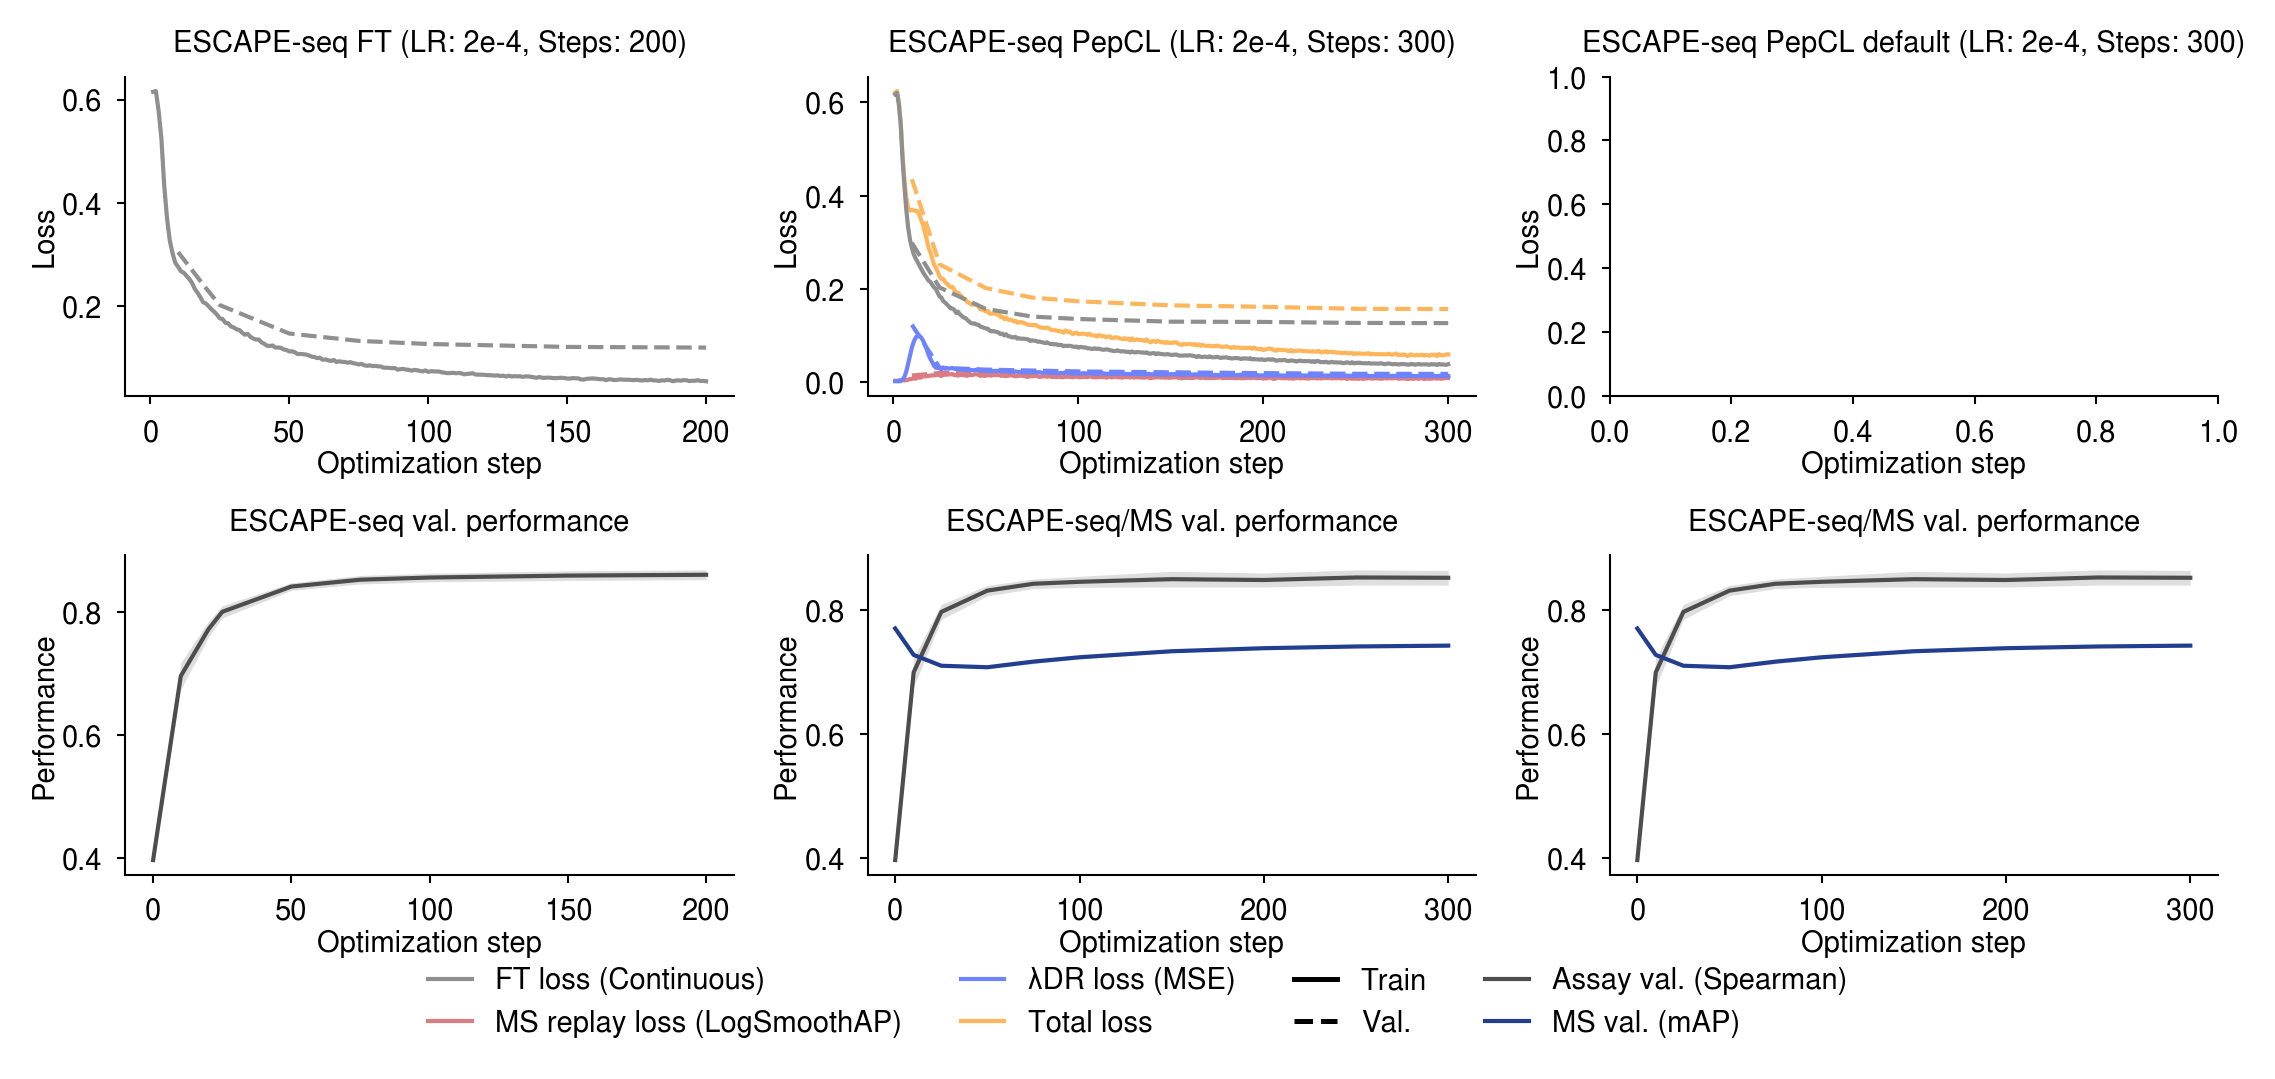

In [ ]:
# plot loss and val aps
escape_con_plot_configs={
    "FT":{
        "base_title":"FT",
        "loss_title":"ESCAPE-seq FT",
        "performance_title":"ESCAPE-seq val. performance",
        "prefix":"escape_con_ft_steps_200_lr_2eN4",
        "method":"ft",
        "lr":"2e-4",
        "steps":200,
    },
    "PepCL":{
        "base_title":"PepCL",
        "loss_title":"ESCAPE-seq PepCL",
        "performance_title":"ESCAPE-seq/MS val. performance",
        "prefix":"escape_con_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":300,
    },
    "PepCL Default":{
        "base_title":"PepCL default",
        "loss_title":"ESCAPE-seq PepCL default",
        "performance_title":"ESCAPE-seq/MS val. performance",
        "prefix":"escape_con_pepcl_r_dr_steps_300_lr_2eN4",
        "method":"pepcl",
        "lr":"2e-4",
        "steps":300,
    },
}

# better sizing
fig,axes,perf_df=plot_loss_and_validation_performance_grid(
    loss_dfs=escape_con_loss_dfs,
    assay_perf_df=escape_con_ap_dfs["assay_val"],
    ms_perf_df=escape_con_ap_dfs["ms_val_matched"],
    configs=escape_con_plot_configs,
    loss_styles=loss_styles,
    performance_styles=performance_styles,

    title_decorate="loss",
    title_prefix=None,
    include_mhcprime_step0=True,
    landscape=True,

    # Design at approximately final Illustrator size
    figsize=(9, 3.5),
    dpi=300,

    # Keep all text at final 7 pt size
    title_fontsize=7,
    label_fontsize=7,
    tick_fontsize=7,
    legend_fontsize=7,

    # Tighten layout so axes occupy more of fixed canvas
    panel_wspace=0.22,
    panel_hspace=0.5,

    # Fine publication-scale strokes
    axis_linewidth=0.5,
    tick_width=0.5,
    tick_length=2.0,

    xlabel_pad=1.0,
    ylabel_pad=1.0,

    # Existing legend controls only
    legend_ncol=4,
    legend_loc="lower center",
    legend_bbox=(0.5,-0.06),
    legend_frame=False,
    legend_handlelength=1.5,

    # save_path=f"{lr_step_var_figures_dir}/escape_con_train_val_loss_performance_curves",
)

#### Save data for plotting

In [ ]:
lr_step_loss_plot_data={
    "yd":{
        "loss_dfs":yd_loss_dfs,
        "assay_perf_df":holec_ap_dfs["assay_val"],
        "ms_perf_df":holec_ap_dfs["ms_val_matched"],
        "plot_configs":yd_plot_configs,
    },

    "episcan_r9":{
        "loss_dfs":episcan_r9_loss_dfs,
        "assay_perf_df":episcan_r9_ap_dfs["assay_val_mixture"],
        "ms_perf_df":episcan_r9_ap_dfs["ms_val_matched"],
        "plot_configs":episcan_r9_plot_configs,
    },

    "episcan_r9rt":{
        "loss_dfs":episcan_r9rt_loss_dfs,
        "assay_perf_df":episcan_r9rt_ap_dfs["assay_val_mixture"],
        "ms_perf_df":episcan_r9rt_ap_dfs["ms_val_matched"],
        "plot_configs":episcan_r9rt_plot_configs,
    },

    "ba_con":{
        "loss_dfs":ba_con_loss_dfs,
        "assay_perf_df":ba_con_ap_dfs["assay_val"],
        "ms_perf_df":ba_con_ap_dfs["ms_val_matched"],
        "plot_configs":ba_con_plot_configs,
    },

    "escape_con":{
        "loss_dfs":escape_con_loss_dfs,
        "assay_perf_df":escape_con_ap_dfs["assay_val"],
        "ms_perf_df":escape_con_ap_dfs["ms_val_matched"],
        "plot_configs":escape_con_plot_configs,
    },
}

save_dict_pickle(lr_step_loss_plot_data, f"{DATA_DIR}/Revisions_Data/assay_specific_learning_rate_and_step_variations_w_early_stopping_final_models_train_val_loss_and_performances.pkl")

### Compute requirements for PepCL and FT

#### Load and process training data

In [ ]:
# load ms train, validation, and test sets
print("Loading MS data...")
ms_train_test_dir=f"{DATA_DIR}/Training_Datasets/Processed/MS_Train_Test_Sets"
ms_train_data=pd.read_csv(f"{ms_train_test_dir}/ms_train_data_remaining_minimal.csv", index_col=0)

# load yd train, validation, and test sets
print("Loading YD data...")
holec_train_test_dir=f"{DATA_DIR}/Training_Datasets/Processed/Holec_et_al_2025"
holec_train_set_remaining=pd.read_csv(f"{holec_train_test_dir}/holec_train_set_remaining.csv", index_col=0)

print("Merging MS/YD data...")
ms_train_data["domain_id"]=0 
holec_train_set_remaining["domain_id"]=1

ms_holec_train_set=pd.concat([ms_train_data, holec_train_set_remaining])
ms_holec_train_set.reset_index(inplace=True, drop=True)
print_data_stats(ms_holec_train_set)

# match allele and length distribution between domains in train
ms_holec_train_set["seq_len"]=ms_holec_train_set.seq.str.replace("$", "").apply(len) # seq.str.replace("$", "") check for padding
ms_holec_train_set_matched_allele_length=ms_holec_train_set[ms_holec_train_set.allele.isin(holec_train_set_remaining.allele.unique().tolist())].query("seq_len == 9")
ms_holec_train_set_matched_allele_length.reset_index(inplace=True, drop=True)
print_data_stats(ms_holec_train_set_matched_allele_length)

Loading MS data...
Loading YD data...
Merging MS/YD data...
Total: 37,232,971
Pos: 750,280 | 2.02%
Neg: 36,482,691 | 97.98%
N alleles: 192
Total: 6,231,985
Pos: 123,247 | 1.98%
Neg: 6,108,738 | 98.02%
N alleles: 16


In [ ]:
# create minimal df and provide mhc_seq_dict now for ext.
ms_holec_train_set_matched_allele_length_minimal=ms_holec_train_set_matched_allele_length[["seq", "allele", "label", "domain_id"]].copy()

# remove seq padding
ms_holec_train_set_matched_allele_length_minimal.seq=ms_holec_train_set_matched_allele_length_minimal.seq.str.replace("$", "")

ms_holec_train_set_matched_allele_length_minimal_ft_only=ms_holec_train_set_matched_allele_length_minimal.query("domain_id == 1")

#### Load MHCPrime

In [ ]:
# setup tokenizer
tokenizer = AminoAcidTokenizer()

In [ ]:
# set base model params
base_model_params={
        'vocab_size': tokenizer.vocab_size,
        'embed_dim': 480,
        'fc_hidden_dims': [240, 120], 
        'fc_dropout': 0.1,
        'n_heads': 16,
        'max_peptide_len': 34,
        'max_mhc_len': 34,
        "n_peptide_layers": 2,
        "n_mhc_layers": 1,
        'n_concat_layers': 3,
        'add_pos_enc': True,
        'use_segment_embedder': True,
        'dim_feedforward_multiplier': 1,
        'debugging': False,
        'fc_output_dim': 1,
        'pooling': 'cls', # cls, mean, min, max, attn, for sequence ffnn head
        "ffnn_use_layernorm": False, 
        'use_feature_table': True,
        "feature_table": processed_feature_table,
        "sequence_embedder_feature_names": feature_names,
        'sequence_embedder_feature_mode': "concat",  # replace or concat
        'sequence_embedder_tokenizer': tokenizer,
        "peptide_start_pos": 1, 
        "mhc_start_pos": 35, 
        "pos_enc_type": "sincos", 
        "seed": 42,

        # peptide conformer
        "add_peptide_conformer": True, 
        "peptide_conformer_num_layers": 2,
        "peptide_conformer_n_heads": 16,
        "peptide_conformer_conv_kernel": 5,
        "peptide_conformer_dropout": 0.0,

        # mhc conformer
        "add_mhc_conformer": False, 
        "mhc_conformer_num_layers": 2,
        "mhc_conformer_n_heads": 16,
        "mhc_conformer_conv_kernel": 5,
        "mhc_conformer_dropout": 0.0,

        # fusion conformer parameters
        "add_fusion_conformer": True, 
        "fusion_conformer_num_layers": 1,
        "fusion_conformer_n_heads": 16,
        "fusion_conformer_conv_kernel": 7,
        "fusion_conformer_dropout": 0.0,
        "fusion_conformer_mask_bos": True,
        "ff_pre_post_swiglu": False,

        # legacy init
        "legacy_init_compat": True,
}

In [ ]:
%%time
# load base model (optionally, can load model_params directly)
# run_name = "MHCPrime_Base"
# run_dir = MODEL_CHECKPOINTS_DIR / run_name
# model_dir = run_dir / "Checkpoints"

# mhcprime=init_model(base_model_params, print_check=False, print_params=True)
# mhcprime.load_state_dict(torch.load(f"{model_dir}/model_final.pt"))
# mhcprime.eval()
# print("Model loaded from checkpoint...")
# clear_all_gpu_memory()

base_model_dir = MODEL_CHECKPOINTS_DIR / "MHCPrime_Base_for_Ablations" / "Checkpoints"
ckpt_path = base_model_dir / "model_final.pt"

device = torch.device(f"cuda:{GPU_ID}" if torch.cuda.is_available() else "cpu")

clear_all_gpu_memory()

mhcprime = init_model(
    base_model_params,
    print_check=False,
    print_params=True,
)

state_dict = torch.load(
    ckpt_path,
    map_location="cpu",
)

mhcprime.load_state_dict(state_dict, strict=True)
mhcprime.to(device)
mhcprime.eval()

print("Model loaded from checkpoint...")
print(f"Checkpoint: {ckpt_path}")
print(f"Model device: {next(mhcprime.parameters()).device}")

print(end="\n")


All GPU memory has been cleared.
Current GPU memory allocated: 0.00 GB
Current GPU memory reserved: 0.00 GB
[FeatureProjectionEncoder] Warning: no features found for tokens: ['$', '*', '<BOS>']
Number of trainable modules: 202
Number of trainable parameters: 25751991
Model loaded successfully...
Model loaded from checkpoint...
Checkpoint: /home/pchati/PepCL_Manuscript/Model_Checkpoints/MHCPrime_Base_for_Ablations/Checkpoints/model_final.pt
Model device: cuda:2

CPU times: user 497 ms, sys: 89.4 ms, total: 586 ms
Wall time: 601 ms


#### Run FT and PepCL

In [ ]:
pepcl_base_params=dict(
            tokenizer=tokenizer,
            device="cuda",

            # steps
            steps = 300,
            
            output_dir = None,
            # save_every_n_steps = 2000,
            seed = 42,
            num_workers = 16,
            collate_fn = collate_fn,

            # sampling
            num_ms_pos = 2000,
            num_nonms_pos = 2000,
            ms_neg_ratio = 1.0,
            nonms_neg_ratio = 1.0,

            auto_calibrate = True,
            calibration_steps = 1,

            ms_batch_size = 3072,
            nonms_batch_size = 3072,

            # optimization
            encoder_lr = 2e-4,
            decoder_lr = 2e-4,
            weight_decay = 0.01,
            warmup_ratio = 0.1,
            update_domain_embeddings = False,

            # continual learning parameters
            primary_task_id = 1,
            sequential_backprop = True,

            # losses
            ms_loss_type = "logsmoothap",
            ms_loss_alpha = 10.0,
            ms_lambda = 1.0,
            nonms_loss_type = "logsmoothap",
            nonms_loss_alpha = 10.0,
            ft_lambda = 1.0,

            # drift regularization
            dr_lambda = 1e-5,
            dr_loss_type = "mse"
)

In [ ]:
# set steps
steps = 300
learning_rate = 2e-4
num_workers=2
pepcl_base_params["save_every_n_steps"] = None
pepcl_base_params["num_workers"] = num_workers

In [ ]:
%%time
# first run base ft version
holec_ft = copy.deepcopy(mhcprime)

pepcl_base_params["dr_lambda"]=0

# run updated pepcl function
pepcl=PepCL_Logging_Ext(
            model=holec_ft,
            train_df=ms_holec_train_set_matched_allele_length_minimal_ft_only,
            use_replay = False,
            mhc_seq_dict=mhc_seq_dict,
            enable_logging=True,
            **pepcl_base_params,
)
training_stats=pepcl.train()
ft_logs=pepcl.get_logs(as_dataframes=True)
clear_all_gpu_memory()

[PepCL_Logging_Ext] Auto-calibrated sampling:
  FT: alleles=16, A_eff=12.29, balance=0.768, target_pos/cycle=1536, q_pos median=93.5 [79, 121], reuse median=0.0644, reuse max=0.1946, neg_ratio=1.0



PepCL_Logging_Ext: 100%|██████████| 300/300 [01:43<00:00,  2.90it/s, MS=0.000000, FT=0.007154, DR=0.000000]


All GPU memory has been cleared.
Current GPU memory allocated: 0.38 GB
Current GPU memory reserved: 2.23 GB
CPU times: user 1min 44s, sys: 4.22 s, total: 1min 49s
Wall time: 1min 46s


In [ ]:
%%time
# first run base pepcl version
holec_pepcl = copy.deepcopy(mhcprime)

pepcl_base_params["dr_lambda"]=1e-5

# run updated pepcl function
pepcl=PepCL_Logging_Ext(
            model=holec_pepcl,
            train_df=ms_holec_train_set_matched_allele_length_minimal, # contains both domain ids
            use_replay = True,
            mhc_seq_dict=mhc_seq_dict,
            enable_logging=True,
            **pepcl_base_params,
)
training_stats=pepcl.train()
pepcl_logs=pepcl.get_logs(as_dataframes=True)
clear_all_gpu_memory()

[PepCL_Logging_Ext] Auto-calibrated sampling:
  MS: alleles=16, A_eff=6.50, balance=0.406, target_pos/cycle=1536, q_pos median=73.5 [46, 348], reuse median=0.0200, reuse max=0.0651, neg_ratio=1.0
  FT: alleles=16, A_eff=12.29, balance=0.768, target_pos/cycle=1536, q_pos median=93.5 [79, 121], reuse median=0.0644, reuse max=0.1946, neg_ratio=1.0



PepCL_Logging_Ext: 100%|██████████| 300/300 [03:52<00:00,  1.29it/s, MS=0.008846, FT=0.009872, DR=0.003978]


All GPU memory has been cleared.
Current GPU memory allocated: 0.69 GB
Current GPU memory reserved: 4.39 GB
CPU times: user 3min 49s, sys: 18.3 s, total: 4min 7s
Wall time: 4min


In [ ]:
log_dict={
    "FT":ft_logs,
    "PepCL":pepcl_logs,
}

resource_results=summarize_pepcl_compute_logs(
    log_dict,
    plot=False,
)

# save
resource_results=format_pepcl_compute_summary_df(resource_results)
resource_results=format_numeric_columns_two_decimals(resource_results)
resource_results.to_csv(f"{DATA_DIR}/Revisions_Data/compute_resource_table.csv")

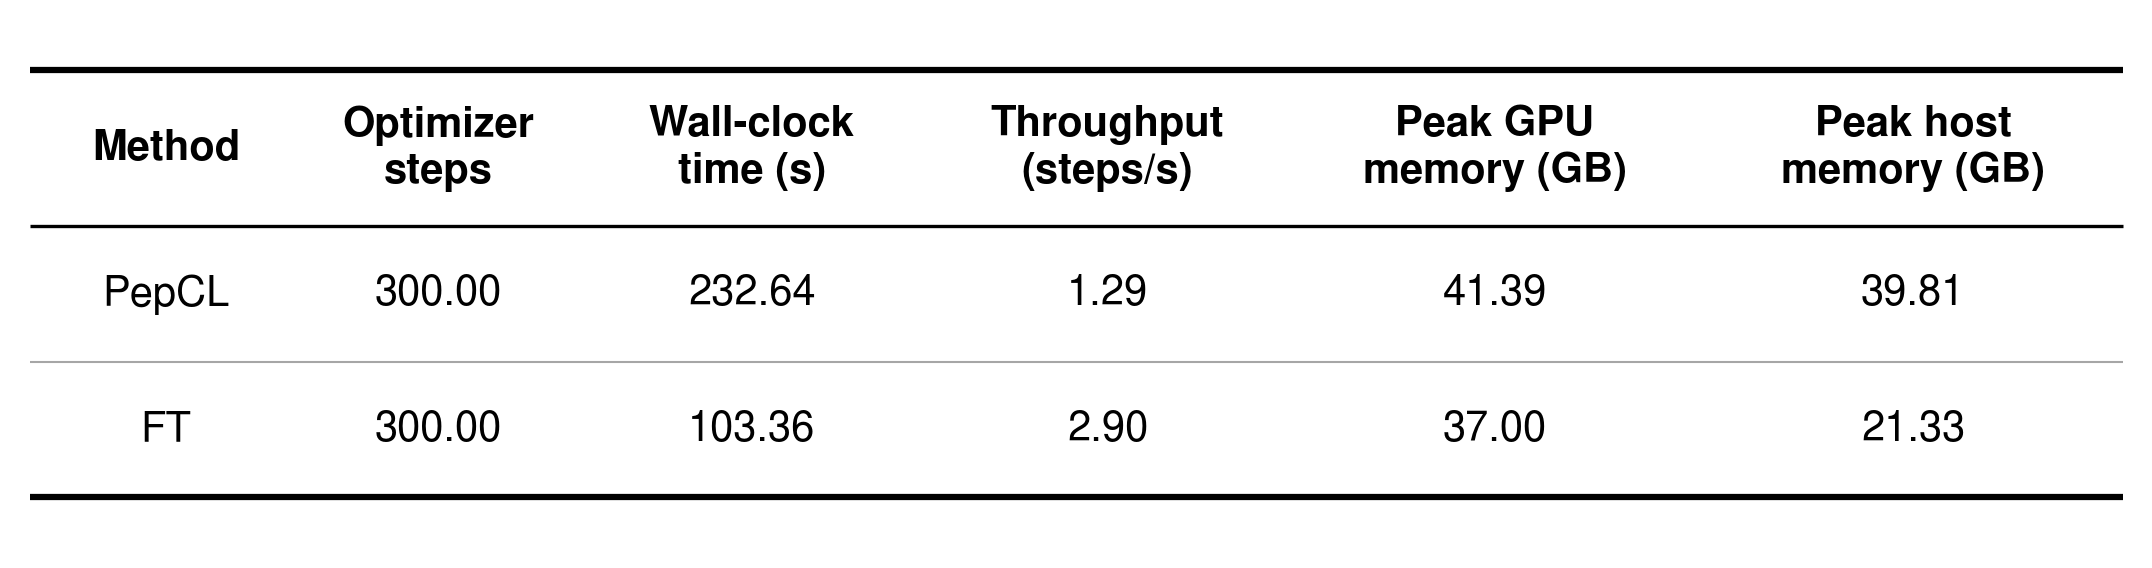

In [ ]:
fig,ax,tbl,display_df=plot_pepcl_compute_summary_table_df(
    resource_results,
    method_order=["PepCL", "FT"],
    decimals=2,
    fig_size=(9,2.2),
    dpi=300,
    header_fontsize=10,
    body_fontsize=10,
    table_bbox=(0.0,0.08,1.0,0.84),
    row_height_scale=1.25,
    header_height_scale=1.15,
    top_linewidth=1.5,
    header_linewidth=0.8,
    bottom_linewidth=1.5,
    row_linewidth=0.5,
    row_line_alpha=0.35,
    independent_lines=True,
    # save_path=f"{lr_step_var_figures_dir}/pepcl_ft_compute_summary_table",
)